# Phase 4b: Supervised 90-Day CLV Modeling & Business Evaluation

**Project**: Customer Intelligence Engine (RFM Segmentation + 90-Day CLV Regression)  
**Notebook**: `Notebooks/5_clv_modeling_&_evaluation.ipynb` (Supervised Track Only)  
**Reusable Module**: `src/clv.py` + `tests/test_clv.py`

---

## Core Architectural Decisions (Locked & Interview-Defensible)
1. **Strict Train-Only CV & Single-Shot Test Protocol**:
   - All model selection, baseline benchmarking, hyperparameter tuning, and feature interpretation run exclusively inside **repeated $K$-fold cross-validation on `train` (`T_train = 2010-09-10`, $N=3,228$)**, **stratified by target-decile bins** so heavy wholesale whales are spread evenly across every fold.
   - The **`test` set (`T_test = 2011-09-10`, $N=3,224$)** is untouched for modeling until Step 9 (**one single evaluation** after the final choice is frozen). We maintain an explicit `TEST_EVALUATION_COUNT` audit log; any modification after Step 9 constitutes test contamination.
2. **Zero Preprocessing Leakage Inside `sklearn` Pipelines**:
   - Median imputation (`mean_interpurchase_days`), `log1p`/power compression of skewed numeric inputs, standardization, and rare-category `country` grouping + one-hot encoding live strictly inside `sklearn` `Pipeline` / `ColumnTransformer` objects fit **only inside each training fold**.
3. **Target Selection (`target` Primary, `target_net` / `target_active` Supporting)**:
   - Primary target is **90-day future gross spend (`target >= 0`)** so historical order returns do not create negative CLV targets. `target_active` trains the Stage-1 classifier of the Hurdle model, and `target_net` (`sales + returns`) tests conclusion sensitivity in Step 11.
4. **Zero Cluster-Label Leakage (`segments_t_seg` Diagnostics Only)**:
   - Phase 4a unsupervised segments (`segments_t_seg_2011-09-10.parquet`) were fit on **2011 data** and are already redundant with RFM inputs. Using them for 2010 training or CLV features would inject temporal leakage. They are loaded **only in Step 10** for post-hoc error-analysis slicing on the test set.
5. **Metric Priority (Ranking & Business Metrics First)**:
   - Because ~`42%` of targets equal `0` while skewness reaches `~17–21` (and top wholesale accounts represent multiple percent of total revenue), raw RMSE alone gets dominated by a few outliers. We prioritize **ranking quality & marketing capture** (`Spearman`, `Normalized Gini`, `Top-Decile Capture`, `Lift@10`, `Lift@20`), followed by **calibration** (`Total Revenue Error %`, decile calibration), **median error** (`MedAE`), and **outlier-robust `MAE` / `RMSE` (with & without top-k whales)**.

## Strict Scope Guardrails
- **Allowed**: Baselines, `sklearn` model pipelines, stratified repeated K-fold CV, hyperparameter tuning, one-shot test audit, error analysis, permutation/grouped importance, targeting simulation, and export.
- **Strictly Forbidden**: Modifying Phase 3 feature tables, using test data for fitting/tuning/selection, adding `guest`/`admin` rows, or feeding cluster labels as predictive features.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Test-set discipline audit tracker (must stay 0 until Step 9 single evaluation!)
TEST_EVALUATION_COUNT = 0
TEST_EVALUATION_LOG = []

# Locate repository root whether running from root or Notebooks/
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src").exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = DATA_PROCESSED / "features"
SEG_DIR = DATA_PROCESSED / "segmentation"

print(f"Project Root          : {PROJECT_ROOT}")
print(f"Random State          : {RANDOM_STATE}")
print(f"Train Features Path   : {FEATURES_DIR / 'features_train_2010-09-10.parquet'}")
print(f"Test Features Path    : {FEATURES_DIR / 'features_test_2011-09-10.parquet'}")
print(f"TEST_EVALUATION_COUNT : {TEST_EVALUATION_COUNT}")

Project Root          : C:\Users\mosa\Desktop\Projects\Customer-Intelligence-Engine
Random State          : 42
Train Features Path   : C:\Users\mosa\Desktop\Projects\Customer-Intelligence-Engine\data\processed\features\features_train_2010-09-10.parquet
Test Features Path    : C:\Users\mosa\Desktop\Projects\Customer-Intelligence-Engine\data\processed\features\features_test_2011-09-10.parquet
TEST_EVALUATION_COUNT : 0


## Step 0: Load & Sanity Checks (Schema, Structural `NaN`s, Targets & Customer Overlap)

### Why Check Schema Equality, Missingness Contracts & Train-Test Customer Overlap?
1. **Schema Parity**: Guarantees both cohorts share identical feature names, column order, and dtypes before building `ColumnTransformer` selectors.
2. **Structural `NaN` Audit**: Verifies no accidental nulls slipped into any feature except the intentional structural missingness in `mean_interpurchase_days` (strictly matching `is_single_invoice == 1`).
3. **Target Summary**: Inspects zero-inflation (`target == 0`), skewness, and negative `target_net` counts upfront so metric design matches the empirical distribution.
4. **Customer ID Overlap Audit**: Because `T_train` (`2010-09-10`) and `T_test` (`2011-09-10`) are two annual cohorts from the same retail store, many buyers repeat across both years. Measuring exact ID overlap quantifies how much of `test` comprises returning longitudinal entities (`seen in train`) vs. newly acquired Year-2 buyers (`new to train`), preparing an essential generalization slice for Step 10 error analysis. *(No test labels or predictions are evaluated by any model here.)*

In [2]:
train_df = pd.read_parquet(FEATURES_DIR / "features_train_2010-09-10.parquet")
test_df = pd.read_parquet(FEATURES_DIR / "features_test_2011-09-10.parquet")

TARGET_COLS = ["target", "target_net", "target_active"]
FEATURE_COLS = [c for c in train_df.columns if c not in TARGET_COLS]

# 1. Strict schema & uniqueness assertions
assert list(train_df.columns) == list(test_df.columns), "Train/test column mismatch!"
assert (train_df.dtypes == test_df.dtypes).all(), "Train/test dtype mismatch!"
assert train_df.index.name == "Customer ID" and test_df.index.name == "Customer ID"
assert train_df.index.is_unique and test_df.index.is_unique, "Duplicate Customer IDs detected!"
assert len(FEATURE_COLS) == 26, f"Expected 26 features, got {len(FEATURE_COLS)}"

# 2. Missing value report & structural NaN invariant check
nan_report = pd.DataFrame({
    "train_nulls": train_df.isna().sum(),
    "train_null_pct": (train_df.isna().mean() * 100.0).round(2),
    "test_nulls": test_df.isna().sum(),
    "test_null_pct": (test_df.isna().mean() * 100.0).round(2),
})
for split_name, df_sp in [("train", train_df), ("test", test_df)]:
    non_mipd_nulls = df_sp.drop(columns=["mean_interpurchase_days"]).isna().sum().sum()
    assert non_mipd_nulls == 0, f"Unexpected nulls outside mean_interpurchase_days in {split_name}!"
    assert (df_sp.loc[df_sp["mean_interpurchase_days"].isna(), "is_single_invoice"] == 1).all()
    assert (df_sp.loc[df_sp["mean_interpurchase_days"].notna(), "is_single_invoice"] == 0).all()

# 3. Target summary statistics across both tables
def summarize_targets(df_sp: pd.DataFrame, name: str) -> dict:
    t = df_sp["target"]
    tn = df_sp["target_net"]
    ta = df_sp["target_active"]
    return {
        "split": name,
        "rows": len(df_sp),
        "target_sum_gbp": round(float(t.sum()), 2),
        "active_count": int(ta.sum()),
        "zero_pct": round(float((t == 0).mean() * 100.0), 2),
        "mean_target": round(float(t.mean()), 2),
        "median_target": round(float(t.median()), 2),
        "q90_target": round(float(t.quantile(0.90)), 2),
        "q99_target": round(float(t.quantile(0.99)), 2),
        "max_target": round(float(t.max()), 2),
        "skew_target": round(float(t.skew()), 2),
        "target_net_sum_gbp": round(float(tn.sum()), 2),
        "target_net_lt_0_count": int((tn < 0).sum()),
    }

target_stats_df = pd.DataFrame([
    summarize_targets(train_df, "Train (2010-09-10)"),
    summarize_targets(test_df, "Test (2011-09-10)"),
])

# 4. Longitudinal Customer ID overlap between Train and Test
train_ids = set(train_df.index)
test_ids = set(test_df.index)
overlap_ids = train_ids & test_ids
new_to_train_ids = test_ids - train_ids
only_in_train_ids = train_ids - test_ids

overlap_summary_df = pd.DataFrame([
    {"cohort_metric": "Eligible customers in Train (2010-09-10)", "count": len(train_ids), "pct_of_train": 100.0, "pct_of_test": round(len(overlap_ids) / len(train_ids) * 100.0, 2)},
    {"cohort_metric": "Eligible customers in Test (2011-09-10)", "count": len(test_ids), "pct_of_train": np.nan, "pct_of_test": 100.0},
    {"cohort_metric": "Shared Customer IDs (Appear in BOTH Train & Test)", "count": len(overlap_ids), "pct_of_train": round(len(overlap_ids) / len(train_ids) * 100.0, 2), "pct_of_test": round(len(overlap_ids) / len(test_ids) * 100.0, 2)},
    {"cohort_metric": "New to Train (In Test Only — acquired/reactivated post-T_train)", "count": len(new_to_train_ids), "pct_of_train": np.nan, "pct_of_test": round(len(new_to_train_ids) / len(test_ids) * 100.0, 2)},
    {"cohort_metric": "In Train Only (Inactive in [T_test-270d, T_test) lookback)", "count": len(only_in_train_ids), "pct_of_train": round(len(only_in_train_ids) / len(train_ids) * 100.0, 2), "pct_of_test": np.nan},
])

print("=" * 72)
print("STEP 0 SUMMARY: PHASE 4B INPUT SANITY CHECKS PASSED")
print("=" * 72)
print(f"train_df shape          : {train_df.shape} (26 features + 3 targets)")
print(f"test_df shape           : {test_df.shape} (identical schema & dtypes verified)")
print(f"Schema & dtype equality : True | Index unique: True")
print(f"TEST_EVALUATION_COUNT   : {TEST_EVALUATION_COUNT} (test untouched)")

print("\nNon-Zero Missing Values Report (Structural NaNs ONLY in mean_interpurchase_days):")
display(nan_report[nan_report["train_nulls"] + nan_report["test_nulls"] > 0])

print("\nTarget Distributions Summary:")
display(target_stats_df)

print("\nTrain vs Test Customer ID Overlap:")
display(overlap_summary_df)

print("\n5 Sample Rows from train_df (Random Seed = 42):")
sample_cols = ["recency_days", "frequency", "monetary", "mean_interpurchase_days", "spend_last_90d", "return_rate", "country", "target", "target_net", "target_active"]
display(train_df[sample_cols].sample(5, random_state=RANDOM_STATE).round(2))

STEP 0 SUMMARY: PHASE 4B INPUT SANITY CHECKS PASSED
train_df shape          : (3228, 29) (26 features + 3 targets)
test_df shape           : (3224, 29) (identical schema & dtypes verified)
Schema & dtype equality : True | Index unique: True
TEST_EVALUATION_COUNT   : 0 (test untouched)

Non-Zero Missing Values Report (Structural NaNs ONLY in mean_interpurchase_days):


,train_nulls,train_null_pct,test_nulls,test_null_pct
mean_interpurchase_days,1290,39.96,1330,41.25



Target Distributions Summary:


,split,rows,target_sum_gbp,active_count,zero_pct,mean_target,median_target,q90_target,q99_target,max_target,skew_target,target_net_sum_gbp,target_net_lt_0_count
0,Train (2010-09-10),3228,2430069.08,1885,41.60,752.81,222.08,1502.65,8012.72,79192.85,16.82,2365897.56,32
1,Test (2011-09-10),3224,2585609.91,1862,42.25,801.99,183.64,1519.27,9637.51,123737.11,20.95,2514250.85,28



Train vs Test Customer ID Overlap:


,cohort_metric,count,pct_of_train,pct_of_test
0,Eligible customers in Train (2010-09-10),3228,100.00,57.47
1,Eligible customers in Test (2011-09-10),3224,NaN,100.00
2,Shared Customer IDs (Appear in BOTH Train & Test),1855,57.47,57.54
3,New to Train (In Test Only — acquired/reactivated post-T_train),1369,NaN,42.46
4,"In Train Only (Inactive in [T_test-270d, T_test) lookback)",1373,42.53,NaN



5 Sample Rows from train_df (Random Seed = 42):


,recency_days,frequency,monetary,mean_interpurchase_days,spend_last_90d,return_rate,country,target,target_net,target_active
Customer ID,,,,,,,,,,
13225,18.44,7,8199.81,41.36,2357.74,0.0,United Kingdom,1596.42,1596.42,1
16219,44.51,1,40.80,NaN,40.80,0.0,United Kingdom,0.00,0.00,0
12960,27.52,3,1145.87,88.96,412.30,0.0,United Kingdom,176.20,176.20,1
18001,90.50,1,101.10,NaN,0.00,0.0,United Kingdom,231.31,231.31,1
15288,139.47,2,757.61,69.89,0.00,0.0,United Kingdom,642.40,642.40,1


## Step 1: Whale Audit & Metric Reporting Protocol *(STOP Point)*

### Why Audit Extreme Whales Before Defining Evaluation Metrics?
In Phase 2, we discovered three same-day entry-error invoices worth £39k–£168k reversed within 3–16 minutes. Whenever a single customer in `test` spends **£123.7k (`~4.8%` of total test spend)**, we must verify two critical questions before trusting any regression metric:
1. **Data Integrity Check**: Is the `~£123.7k` buyer a genuine high-frequency wholesale distributor placing real multi-line repeat orders over Sep–Dec, or an un-caught entry/reversal error?
2. **Squared-Error Dominance Check**: Under squared error (`RMSE`), one £100k prediction miss contributes $100{,}000^2 = 10^{10}$ to the sum of squared errors—which can equal **hundreds of ordinary retail customers combined**. Auditing concentration across All vs. Excluding Top-1 / Top-5 targets lets us choose a reporting scheme that does **not** discard legitimate wholesale revenue while preventing a single whale from hiding model improvements across the remaining `99.8%` of accounts.

In [3]:
sales_clean = pd.read_parquet(DATA_PROCESSED / "sales_clean.parquet")
returns_clean = pd.read_parquet(DATA_PROCESSED / "returns_clean.parquet")

def get_top_target_whales(df_sp: pd.DataFrame, cutoff_str: str, top_n: int = 10) -> pd.DataFrame:
    t0 = pd.Timestamp(cutoff_str)
    t1 = t0 + pd.Timedelta(days=90)
    s_win = sales_clean[(sales_clean["InvoiceDate"] >= t0) & (sales_clean["InvoiceDate"] < t1)]
    r_win = returns_clean[(returns_clean["InvoiceDate"] >= t0) & (returns_clean["InvoiceDate"] < t1)]

    inv_counts = s_win.groupby("Customer ID")["Invoice"].nunique().rename("target_invoices")
    line_counts = s_win.groupby("Customer ID")["StockCode"].count().rename("target_lines")
    sku_counts = s_win.groupby("Customer ID")["StockCode"].nunique().rename("target_skus")
    ret_inv = r_win.groupby("Customer ID")["Invoice"].nunique().rename("target_ret_invoices")

    total_sp = float(df_sp["target"].sum())
    top = df_sp.sort_values("target", ascending=False).head(top_n).copy()
    top = top[["country", "frequency", "monetary", "target", "target_net"]].join(
        [inv_counts, line_counts, sku_counts, ret_inv]
    )
    top["target_ret_invoices"] = top["target_ret_invoices"].fillna(0).astype(int)
    top["share_of_target_pct"] = (top["target"] / total_sp * 100.0).round(2)
    return top

top10_train_whales = get_top_target_whales(train_df, "2010-09-10 00:00:00", top_n=10)
top10_test_whales = get_top_target_whales(test_df, "2011-09-10 00:00:00", top_n=10)

print("=" * 72)
print("STEP 1.1: TOP 10 FUTURE-TARGET CUSTOMERS (TRAIN vs TEST)")
print("=" * 72)
print(f"Train Top 1 share : {top10_train_whales['share_of_target_pct'].iloc[0]:.2f}% | Top 5 share: {top10_train_whales['share_of_target_pct'].iloc[:5].sum():.2f}% | Top 10 share: {top10_train_whales['share_of_target_pct'].sum():.2f}%")
print(f"Test  Top 1 share : {top10_test_whales['share_of_target_pct'].iloc[0]:.2f}% | Top 5 share: {top10_test_whales['share_of_target_pct'].iloc[:5].sum():.2f}% | Top 10 share: {top10_test_whales['share_of_target_pct'].sum():.2f}%")

print("\nTop 10 Train Targets (Target Window [2010-09-10, 2010-12-09)):")
display(top10_train_whales.round(2))

print("\nTop 10 Test Targets (Target Window [2011-09-10, 2011-12-09)):")
display(top10_test_whales.round(2))

# Forensic Audit of the Largest Test Customer in Raw sales_clean & returns_clean
largest_test_cid = int(top10_test_whales.index[0])
t_test_0 = pd.Timestamp("2011-09-10 00:00:00")
t_test_1 = t_test_0 + pd.Timedelta(days=90)

whale_sales_win = sales_clean[
    (sales_clean["Customer ID"] == largest_test_cid)
    & (sales_clean["InvoiceDate"] >= t_test_0)
    & (sales_clean["InvoiceDate"] < t_test_1)
].copy()
whale_ret_win = returns_clean[
    (returns_clean["Customer ID"] == largest_test_cid)
    & (returns_clean["InvoiceDate"] >= t_test_0)
    & (returns_clean["InvoiceDate"] < t_test_1)
].copy()

whale_inv_ledger = (
    whale_sales_win.groupby("Invoice")
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        lines=("StockCode", "count"),
        unique_skus=("StockCode", "nunique"),
        total_qty=("Quantity", "sum"),
        total_gbp=("TotalPrice", "sum"),
    )
    .sort_values("InvoiceDate")
)

print("\n" + "=" * 72)
print(f"STEP 1.2: FORENSIC AUDIT OF LARGEST TEST CUSTOMER (ID = {largest_test_cid})")
print("=" * 72)
print(f"Country                     : {test_df.loc[largest_test_cid, 'country']}")
print(f"Lookback [T-270d, T)        : {test_df.loc[largest_test_cid, 'frequency']} invoices | £{test_df.loc[largest_test_cid, 'monetary']:,.2f} gross spend | return_rate={test_df.loc[largest_test_cid, 'return_rate']:.4f}")
print(f"Target [2011-09-10, 12-09)  : {len(whale_inv_ledger)} invoices | {len(whale_sales_win):,} order lines | {whale_sales_win['StockCode'].nunique():,} unique SKUs | {whale_sales_win['Quantity'].sum():,} units | £{whale_sales_win['TotalPrice'].sum():,.2f}")
print(f"Target window returns       : {whale_ret_win['Invoice'].nunique()} credit invoices | {len(whale_ret_win)} lines | £{whale_ret_win['TotalPrice'].sum():,.2f}")
print("\n5 Sample Target-Window Invoices for Largest Test Customer:")
display(whale_inv_ledger.head(5).round(2))
if len(whale_ret_win) > 0:
    print("Target-Window Return Lines:")
    display(whale_ret_win[["Invoice", "StockCode", "Description", "Quantity", "Price", "TotalPrice", "InvoiceDate"]])

# Quantify skewness, std & variance dilution when excluding top-1 and top-5 targets
conc_rows = []
for sp_name, df_sp in [("Train (2010-09-10)", train_df), ("Test (2011-09-10)", test_df)]:
    t_sorted = df_sp["target"].sort_values(ascending=False)
    for label, sub in [("All Customers", t_sorted), ("Excl Top-1 Whale", t_sorted.iloc[1:]), ("Excl Top-5 Whales", t_sorted.iloc[5:])]:
        conc_rows.append({
            "split": sp_name,
            "subset": label,
            "n_rows": len(sub),
            "total_spend_gbp": round(float(sub.sum()), 2),
            "mean_gbp": round(float(sub.mean()), 2),
            "std_gbp": round(float(sub.std()), 2),
            "skewness": round(float(sub.skew()), 2),
        })

conc_df = pd.DataFrame(conc_rows)
print("\n" + "=" * 72)
print("STEP 1.3: TARGET DISPERSION & SKEWNESS SENSITIVITY (ALL vs EXCL TOP-1 / TOP-5)")
print("=" * 72)
display(conc_df)

STEP 1.1: TOP 10 FUTURE-TARGET CUSTOMERS (TRAIN vs TEST)
Train Top 1 share : 3.26% | Top 5 share: 12.17% | Top 10 share: 17.69%
Test  Top 1 share : 4.79% | Top 5 share: 17.26% | Top 10 share: 22.64%

Top 10 Train Targets (Target Window [2010-09-10, 2010-12-09)):


,country,frequency,monetary,target,target_net,target_invoices,target_lines,target_skus,target_ret_invoices,share_of_target_pct
Customer ID,,,,,,,,,,
14646,Netherlands,43.0,162620.46,79192.85,76923.77,27.0,629.0,380.0,1,3.26
18102,United Kingdom,74.0,237264.43,78208.44,78208.44,10.0,59.0,29.0,0,3.22
14911,EIRE,100.0,74604.48,61421.96,55910.54,77.0,2156.0,969.0,21,2.53
16684,United Kingdom,16.0,37485.80,41854.29,38016.49,9.0,279.0,104.0,4,1.72
14156,EIRE,58.0,150294.04,34951.98,34719.23,30.0,834.0,543.0,4,1.44
15838,United Kingdom,6.0,7864.48,32655.44,32374.64,10.0,27.0,9.0,1,1.34
15061,United Kingdom,46.0,41204.16,31256.23,31256.23,33.0,203.0,60.0,0,1.29
12931,United Kingdom,25.0,22963.93,26058.70,25945.90,15.0,43.0,16.0,2,1.07
17511,United Kingdom,19.0,58697.68,22734.85,22608.51,11.0,250.0,192.0,4,0.94



Top 10 Test Targets (Target Window [2011-09-10, 2011-12-09)):


,country,frequency,monetary,target,target_net,target_invoices,target_lines,target_skus,target_ret_invoices,share_of_target_pct
Customer ID,,,,,,,,,,
18102,United Kingdom,23.0,107616.14,123737.11,123737.11,32.0,267.0,118.0,0,4.79
17450,United Kingdom,21.0,84272.70,108089.25,103273.99,23.0,150.0,61.0,3,4.18
14646,Netherlands,42.0,177729.62,101408.40,101408.40,30.0,693.0,437.0,0,3.92
14911,EIRE,100.0,70686.82,60057.38,58717.06,89.0,2680.0,1221.0,21,2.32
14096,United Kingdom,3.0,203.89,53054.54,53054.54,14.0,5039.0,1114.0,0,2.05
16684,United Kingdom,18.0,33883.50,32770.06,32770.06,10.0,109.0,80.0,0,1.27
17511,United Kingdom,19.0,55905.07,31686.63,29105.14,10.0,299.0,207.0,4,1.23
16029,United Kingdom,48.0,41715.87,26720.70,15178.14,11.0,55.0,22.0,2,1.03
14088,United Kingdom,7.0,25507.89,24983.92,24983.92,6.0,294.0,176.0,0,0.97



STEP 1.2: FORENSIC AUDIT OF LARGEST TEST CUSTOMER (ID = 18102)
Country                     : United Kingdom
Lookback [T-270d, T)        : 23 invoices | £107,616.14 gross spend | return_rate=0.0000
Target [2011-09-10, 12-09)  : 32 invoices | 267 order lines | 118 unique SKUs | 32,507 units | £123,737.11
Target window returns       : 0 credit invoices | 0 lines | £0.00

5 Sample Target-Window Invoices for Largest Test Customer:


,InvoiceDate,lines,unique_skus,total_qty,total_gbp
Invoice,,,,,
566931,2011-09-15 15:27:00,3,3,1250,5725.00
566933,2011-09-15 15:30:00,16,16,320,1465.60
566934,2011-09-15 15:34:00,8,8,2893,13249.94
566935,2011-09-15 15:35:00,5,5,1500,6870.00
566936,2011-09-15 15:35:00,7,7,950,4351.00



STEP 1.3: TARGET DISPERSION & SKEWNESS SENSITIVITY (ALL vs EXCL TOP-1 / TOP-5)


,split,subset,n_rows,total_spend_gbp,mean_gbp,std_gbp,skewness
0,Train (2010-09-10),All Customers,3228,2430069.08,752.81,2979.94,16.82
1,Train (2010-09-10),Excl Top-1 Whale,3227,2350876.23,728.50,2641.01,16.07
2,Train (2010-09-10),Excl Top-5 Whales,3223,2134439.56,662.25,1756.21,9.06
3,Test (2011-09-10),All Customers,3224,2585609.91,801.99,4097.15,20.95
4,Test (2011-09-10),Excl Top-1 Whale,3223,2461872.80,763.85,3478.48,20.57
5,Test (2011-09-10),Excl Top-5 Whales,3219,2139263.23,664.57,1853.54,8.98


### Locked Step 1 Decision: Keep All Whales & Dual-Report RMSE
- **`ID 18102` (`£123,737.11`) and peers are 100% real repeat wholesale accounts** (`32` invoices, `267` lines, `118` SKUs, `0` returns in Q4). Removing whales would erase `17.7%–22.6%` (Top 10) of company revenue.
- We **keep all rows untouched** during training and evaluation, prioritizing ranking/business capture metrics and reporting **`RMSE (All)`**, **`RMSE (Excl Top-1)`**, and **`RMSE (Excl Top-5)`** side by side.

---

## Step 2: Evaluation Metrics & CV Stratification Protocol *(STOP Point)*

### What Business Question Does Each Metric Answer?
Because our target has **`~42%` exact zeros** and **extreme wholesale skewness (`16.8–21.0`)**, a single loss metric cannot tell the full story:

| Metric | Category | Formula / Intuition | Business Question Answered |
|---|---|---|---|
| **`spearman`** | Ranking | Rank correlation ($\rho$) between $\hat{y}$ and $y$ | *Do we reliably sort higher-spending customers above lower-spending customers across the whole base?* |
| **`normalized_gini`** | Ranking | Lorenz area gain vs. perfect sorting (`0`=random, `1`=oracle) | *Across all possible budget cutoffs, how well does predicted CLV concentrate future revenue into the top ranks?* |
| **`top_10_capture` / `top_20_capture`** | Business Targeting | Share of real total spend inside top 10% / 20% predicted buyers | *If CRM budgets only cover outreach to the top 10% or 20% of buyers, what % of next quarter's total revenue do we capture?* |
| **`lift_at_10` / `lift_at_20`** | Business ROI | `capture_at_k / k` (`1.0x`=random) | *How many times better is model-targeted marketing ROI vs. mailing customers at random?* |
| **`total_rev_error_pct`** | Finance Calibration | $(\sum \hat{y} - \sum y) / \sum y \times 100\%$ | *If finance budgets quarterly revenue by summing predicted customer CLV, is total forecast unbiased (`~0%`)?* |
| **`calibration_by_predicted_decile`** | Tier Calibration | Mean predicted vs. mean actual spend across predicted deciles | *Are predictions well calibrated in every tier (top 10%, mid-tier, bottom decile), or systematically biased by retransformation?* |
| **`mae` / `medae`** | Point Error (Robust) | Mean / median $|y - \hat{y}|$ in GBP | *How close is a typical individual customer forecast (`medae` resists outliers completely; `mae` weights all pounds linearly)?* |
| **`rmse` / `excl_top1` / `excl_top5`** | Squared Error | $\sqrt{\text{mean}((y - \hat{y})^2)}$ (full & trimmed true whales) | *What is tail error overall, vs. excluding the 1 or 5 largest wholesale buyers that inflate squared variance by 40–55%?* |

In [4]:
from sklearn.model_selection import RepeatedStratifiedKFold
from src.clv import (
    calibration_by_predicted_decile,
    evaluate_clv_predictions,
    make_stratification_bins,
)

# 1. Verify CLV metrics on tiny hand-made toy ranking example
toy_true = np.array([0.0, 0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 100.0, 200.0, 550.0])  # sum = 1,000
toy_pred = np.array([1.0, 2.0, 12.0, 18.0, 25.0, 45.0, 55.0, 90.0, 220.0, 532.0])  # sum = 1,000
toy_metrics = evaluate_clv_predictions(toy_true, toy_pred)
toy_const = evaluate_clv_predictions(toy_true, np.full(10, 100.0))

assert np.isclose(toy_metrics["normalized_gini"], 1.0)
assert np.isclose(toy_metrics["top_10_capture"], 0.55)
assert np.isclose(toy_metrics["lift_at_10"], 5.5)
assert np.isclose(toy_metrics["total_rev_error_pct"], 0.0)
assert np.isclose(toy_const["normalized_gini"], 0.0) and np.isclose(toy_const["lift_at_10"], 1.0)
print("UNIT TEST PASSED: All CLV ranking, capture, lift, Gini & constant-safety assertions passed!")

toy_comp_df = pd.DataFrame([
    {"case": "Toy Oracle-Ordered Model", **toy_metrics},
    {"case": "Toy Constant Mean Baseline", **toy_const},
])

# 2. Construct target-stratified Repeated K-Fold CV splitter on TRAIN only (5 folds x 3 repeats)
train_strata = make_stratification_bins(train_df["target"], n_positive_bins=9)
cv_splitter = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

strata_audit_df = (
    pd.DataFrame({"stratum": train_strata, "target": train_df["target"].to_numpy()})
    .groupby("stratum")
    .agg(customers=("target", "count"), min_target=("target", "min"), max_target=("target", "max"))
)

print("\n" + "=" * 72)
print("STEP 2 SUMMARY: CLV METRICS CATALOG & TRAIN STRATIFIED CV PROTOCOL")
print("=" * 72)
print(f"CV Protocol          : RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state={RANDOM_STATE})")
print(f"Total CV splits      : {cv_splitter.get_n_splits(train_df, train_strata)} validation folds (STRICTLY on train_df n={len(train_df)})")
print(f"TEST_EVALUATION_COUNT: {TEST_EVALUATION_COUNT}")

print("\nToy Verification Table (Shape: {}):".format(toy_comp_df.shape))
display(toy_comp_df.round(4))

print("\nToy Decile Calibration Output:")
display(calibration_by_predicted_decile(toy_true, toy_pred, n_bins=5).round(2))

print("\nTrain Stratification Bins (Bin 0 = Zeros; Bin 9 Spreads Extreme Whales Evenly Across Folds):")
display(strata_audit_df.round(2))

print("\n5 Sample Train Rows With Stratification Stratum (Random Seed = 42):")
sample_s2 = train_df[["recency_days", "frequency", "monetary", "target"]].copy()
sample_s2["cv_stratum"] = train_strata
display(sample_s2.sample(5, random_state=RANDOM_STATE).round(2))

UNIT TEST PASSED: All CLV ranking, capture, lift, Gini & constant-safety assertions passed!

STEP 2 SUMMARY: CLV METRICS CATALOG & TRAIN STRATIFIED CV PROTOCOL
CV Protocol          : RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
Total CV splits      : 15 validation folds (STRICTLY on train_df n=3228)
TEST_EVALUATION_COUNT: 0

Toy Verification Table (Shape: (2, 13)):


,case,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
0,Toy Oracle-Ordered Model,0.997,1.0,0.55,5.5,0.75,3.75,0.0,7.0,5.0,9.5499,8.0829,2.7568
1,Toy Constant Mean Baseline,0.000,0.0,0.10,1.0,0.20,1.00,0.0,110.0,85.0,160.6238,78.5281,88.7694



Toy Decile Calibration Output:


,n_customers,mean_pred,mean_actual,median_actual,sum_pred,sum_actual,actual_share_pct,pred_share_pct,pred_to_actual_ratio
pred_decile,,,,,,,,,
1,2,1.5,0.0,0.0,3.0,0.0,0.0,0.3,NaN
2,2,15.0,15.0,15.0,30.0,30.0,3.0,3.0,1.00
3,2,35.0,35.0,35.0,70.0,70.0,7.0,7.0,1.00
4,2,72.5,75.0,75.0,145.0,150.0,15.0,14.5,0.97
5,2,376.0,375.0,375.0,752.0,750.0,75.0,75.2,1.00



Train Stratification Bins (Bin 0 = Zeros; Bin 9 Spreads Extreme Whales Evenly Across Folds):


,customers,min_target,max_target
stratum,,,
0,1343,0.00,0.00
1,210,10.90,186.10
2,209,186.55,301.80
3,210,302.26,394.20
4,209,394.29,509.92
5,209,510.05,673.51
6,210,673.73,903.68
7,209,903.96,1235.96
8,209,1237.99,2094.68



5 Sample Train Rows With Stratification Stratum (Random Seed = 42):


,recency_days,frequency,monetary,target,cv_stratum
Customer ID,,,,,
13225,18.44,7,8199.81,1596.42,8
16219,44.51,1,40.80,0.00,0
12960,27.52,3,1145.87,176.20,1
18001,90.50,1,101.10,231.31,2
15288,139.47,2,757.61,642.40,5


### Locked Step 2 Decision
Evaluation suite (`Spearman`, `Normalized Gini`, `Top-10%` & `Top-20% Capture`, `Lift@10` & `Lift@20`, `Total Revenue Error %`, `Decile Calibration`, `MAE`, `MedAE`, `RMSE [All / Excl Top-1 / Excl Top-5]`) and `5 x 3` target-stratified CV on `train_df` approved.

---

## Step 3: Non-ML Rule & Constant Baselines (Train CV Only)

### Why Benchmark Against Simple Heuristics Before Training ML Models?
A portfolio model is only worth shipping if it measurably beats simple zero-engineering rules evaluated on the exact same `5 x 3` CV folds:
1. **(a) Train Mean Baseline**: Predicts the constant fold mean $\bar{y}_{\text{train}}$ for every customer. Minimizes in-sample `RMSE` among constants, but has **zero ranking power (`Gini = 0`, `Lift@10 = 1.0x`)**.
2. **(b) Train Median Baseline**: Predicts the constant fold median for every customer. Minimizes `MAE` among constants, yet suffers massive portfolio revenue under-prediction because median is much smaller than mean in heavy-tailed retail.
3. **(c) Run-Rate Baseline (`monetary * 90 / 270`)**: Scales a buyer's past 270-day spend linearly to 90 days. Captures customer spend power intuitively **without** seasonal adjustment (`Sep–Dec` holiday lift) or recency decay.
4. **(d) Frequency-Based Run-Rate (`aov * frequency * 90 / 270`)**: Since `aov = monetary / frequency` by definition, `(d)` is **algebraically identical to `(c)`** (`(monetary / freq) * freq * 90/270 == monetary * 90/270`)—confirming whether our pipeline/formula verification holds cleanly.

> **Deployment Hurdle**: Any ML pipeline selected in Step 7 **must convincingly beat the `run_rate` (`monetary * 90 / 270`) baseline** across ranking, capture, calibration, and error metrics to be worth deploying.

In [5]:
from src.clv import RuleBaselineRegressor, cross_validate_clv_estimator

X_train = train_df[FEATURE_COLS].copy()
y_train = train_df["target"].copy()

baseline_specs = [
    ("Baseline (a): Train Mean", RuleBaselineRegressor(rule="train_mean")),
    ("Baseline (b): Train Median", RuleBaselineRegressor(rule="train_median")),
    ("Baseline (c): Run-Rate (monetary * 90/270)", RuleBaselineRegressor(rule="run_rate")),
    ("Baseline (d): Freq * AOV * 90/270", RuleBaselineRegressor(rule="freq_aov_run_rate")),
]

baseline_summaries = []
baseline_oof_map = {}

for name, est in baseline_specs:
    summary, fold_df, oof_pred = cross_validate_clv_estimator(
        est, X_train, y_train, cv=cv_splitter, strata=train_strata
    )
    baseline_oof_map[name] = oof_pred
    row = {"model": name}
    row.update(summary)
    baseline_summaries.append(row)

# Verify exact algebraic identity between Baseline (c) and Baseline (d)
np.testing.assert_allclose(
    baseline_oof_map["Baseline (c): Run-Rate (monetary * 90/270)"],
    baseline_oof_map["Baseline (d): Freq * AOV * 90/270"],
    rtol=1e-12,
    atol=1e-12,
)

baseline_cv_df = pd.DataFrame(baseline_summaries)

# Readable mean ± std summary for core Step 2 metrics
CORE_DISPLAY_METRICS = [
    "spearman",
    "normalized_gini",
    "top_10_capture",
    "lift_at_10",
    "top_20_capture",
    "lift_at_20",
    "total_rev_error_pct",
    "mae",
    "medae",
    "rmse",
    "rmse_excl_top1",
    "rmse_excl_top5",
]

def format_cv_mean_std(df_res: pd.DataFrame, metrics: list[str] = CORE_DISPLAY_METRICS) -> pd.DataFrame:
    out = pd.DataFrame({"model": df_res["model"]})
    for m in metrics:
        mean_col, std_col = f"{m}_mean", f"{m}_std"
        if m in ("spearman", "normalized_gini", "top_10_capture", "top_20_capture"):
            out[m] = [f"{mu:.4f} ± {sd:.4f}" for mu, sd in zip(df_res[mean_col], df_res[std_col])]
        elif m in ("lift_at_10", "lift_at_20"):
            out[m] = [f"{mu:.2f}x ± {sd:.2f}" for mu, sd in zip(df_res[mean_col], df_res[std_col])]
        elif m == "total_rev_error_pct":
            out[m] = [f"{mu:+.2f}% ± {sd:.2f}" for mu, sd in zip(df_res[mean_col], df_res[std_col])]
        else:
            out[m] = [f"{mu:,.1f} ± {sd:,.1f}" for mu, sd in zip(df_res[mean_col], df_res[std_col])]
    return out.set_index("model")

print("=" * 72)
print("STEP 3 SUMMARY: TRAIN 5x3 CV BASELINES BENCHMARK")
print(f"(TEST_EVALUATION_COUNT = {TEST_EVALUATION_COUNT} — zero test touch)")
print("=" * 72)
print("Exact algebraic equivalence (c) == (d) verified (max diff = 0.00).")
display(format_cv_mean_std(baseline_cv_df))

print("\nRun-Rate Baseline Out-of-Fold Calibration by Predicted Decile (1=Lowest, 10=Top):")
rr_cal_df = calibration_by_predicted_decile(
    y_train, baseline_oof_map["Baseline (c): Run-Rate (monetary * 90/270)"], n_bins=10
)
display(rr_cal_df.round(2))

print("\n5 Sample Train Rows With OOF Baseline Predictions (Random Seed = 42):")
sample_b3 = train_df[["recency_days", "frequency", "monetary", "target"]].copy()
sample_b3["oof_mean"] = baseline_oof_map["Baseline (a): Train Mean"]
sample_b3["oof_median"] = baseline_oof_map["Baseline (b): Train Median"]
sample_b3["oof_run_rate"] = baseline_oof_map["Baseline (c): Run-Rate (monetary * 90/270)"]
display(sample_b3.sample(5, random_state=RANDOM_STATE).round(2))

STEP 3 SUMMARY: TRAIN 5x3 CV BASELINES BENCHMARK
(TEST_EVALUATION_COUNT = 0 — zero test touch)
Exact algebraic equivalence (c) == (d) verified (max diff = 0.00).


,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
model,,,,,,,,,,,,
Baseline (a): Train Mean,0.0000 ± 0.0000,0.0000 ± 0.0000,0.1000 ± 0.0000,1.00x ± 0.00,0.2000 ± 0.0000,1.00x ± 0.00,+1.48% ± 14.66,889.3 ± 71.0,752.8 ± 20.5,"2,825.6 ± 979.6","1,893.7 ± 501.2","1,043.6 ± 92.6"
Baseline (b): Train Median,0.0000 ± 0.0000,0.0000 ± 0.0000,0.1000 ± 0.0000,1.00x ± 0.00,0.2000 ± 0.0000,1.00x ± 0.00,-70.17% ± 3.40,728.3 ± 81.8,222.0 ± 1.8,"2,875.0 ± 977.7","1,943.9 ± 503.7","1,077.4 ± 103.0"
Baseline (c): Run-Rate (monetary * 90/270),0.5060 ± 0.0197,0.7700 ± 0.0388,0.5214 ± 0.0515,5.21x ± 0.52,0.6505 ± 0.0421,3.25x ± 0.21,-29.69% ± 6.40,527.1 ± 42.3,209.1 ± 8.7,"1,599.2 ± 364.1","1,371.2 ± 277.4",825.3 ± 70.8
Baseline (d): Freq * AOV * 90/270,0.5060 ± 0.0197,0.7700 ± 0.0388,0.5214 ± 0.0515,5.21x ± 0.52,0.6505 ± 0.0421,3.25x ± 0.21,-29.69% ± 6.40,527.1 ± 42.3,209.1 ± 8.7,"1,599.2 ± 364.1","1,371.2 ± 277.4",825.3 ± 70.8



Run-Rate Baseline Out-of-Fold Calibration by Predicted Decile (1=Lowest, 10=Top):


,n_customers,mean_pred,mean_actual,median_actual,sum_pred,sum_actual,actual_share_pct,pred_share_pct,pred_to_actual_ratio
pred_decile,,,,,,,,,
1,322,30.34,90.95,0.00,9769.06,29287.35,1.21,0.57,0.33
2,323,58.06,166.33,0.00,18752.14,53725.09,2.21,1.10,0.35
3,323,88.83,237.00,0.00,28692.08,76552.56,3.15,1.69,0.37
4,323,117.70,223.77,0.00,38016.51,72279.01,2.97,2.23,0.53
5,323,164.39,316.90,136.24,53096.94,102357.18,4.21,3.12,0.52
6,322,222.68,428.21,275.14,71702.43,137884.52,5.67,4.21,0.52
7,323,311.40,544.86,369.76,100583.11,175990.08,7.24,5.91,0.57
8,323,450.49,596.26,482.75,145508.02,192593.47,7.93,8.55,0.76
9,323,711.42,968.54,750.40,229787.08,312838.35,12.87,13.50,0.73



5 Sample Train Rows With OOF Baseline Predictions (Random Seed = 42):


,recency_days,frequency,monetary,target,oof_mean,oof_median,oof_run_rate
Customer ID,,,,,,,
13225,18.44,7,8199.81,1596.42,764.21,222.48,2733.27
16219,44.51,1,40.80,0.00,773.93,220.86,13.60
12960,27.52,3,1145.87,176.20,731.82,221.69,381.96
18001,90.50,1,101.10,231.31,779.67,221.42,33.70
15288,139.47,2,757.61,642.40,769.14,221.21,252.54


## Step 4: Candidate Model Families & Duan Smearing Architecture

Before evaluating full `5 x 3` cross-validation in Step 5, we design five distinct pure-`sklearn` model families inside leak-free `Pipeline` / `ColumnTransformer` wrappers. Notice **none of these use `lightgbm` / `xgboost`** (both are absent from `.venv`; `scikit-learn 1.9.1` provides `HistGradientBoosting`, `TweedieRegressor`, `ElasticNet`, `Ridge`, and `ExtraTrees`).

### Expected Strengths & Weaknesses Across Families on Our Data

| Family | Architecture & Preprocessing | Expected Strengths | Expected Weaknesses / Risks on Retail CLV |
|---|---|---|---|
| **A. Regularized Linear (`Ridge`, `ElasticNet` on `log1p(y)` + Duan Smearing)** | `SimpleImputer(median)` + `log1p(skewed)` + `StandardScaler` + grouped `Country -> OneHot` (`<= 7` cols) | Fast, stable ranking weights, `log1p(y)` tames skewness `16.8 -> ~1`, collinear spend/count handled by L2 (`Ridge`) or L1/L2 (`ElasticNet`). | Assumes additive log-linear effects; cannot model `recency x frequency` interactions natively; `41.6%` zeros cause multimodal `log1p` residuals (large Duan smearing factor). |
| **B. `TweedieRegressor` GLM (`power=1.5`, `log` link on raw `y >= 0`)** | Same `build_linear_clv_preprocessor`; directly optimizes Tweedie deviance (`power in (1, 2)` = compound Poisson-Gamma) | Naturally models **exact point mass at `0` + continuous positive spend** simultaneously on original GBP scale (zero retransformation bias!). | Strictly log-linear predictor $\exp(X\beta)$ can **explode exponentially** on extreme whale covariate combinations unless regularized (`alpha`). |
| **C. `HistGradientBoostingRegressor` (`C1`: `squared_error` on `log1p(y)` + Duan; `C2`: `poisson` on raw `y >= 0`)** | `build_tree_clv_preprocessor(impute_missing=False)`: passes `NaN` in `mean_interpurchase_days` natively; grouped `Country -> OneHot` | Captures non-linear interactions (`recency x frequency`, `is_single_invoice x recency`) automatically without collinearity sensitivity or feature scaling. **Loss note**: raw **`gamma`** loss requires strictly $y > 0$ (crashes on `42%` zeros), whereas **`poisson`** validly accepts $y \ge 0$ zeros cleanly! | Trees extrapolate **flatly above max training leaves** for top wholesale whales; `C2` (`poisson`) weights variance proportional to mean ($\text{Var}(y) \propto \mu$), which underestimates extreme overdispersion ($\text{Var} \gg \mu$). |
| **D. Two-Stage `HurdleCLVRegressor` (`D1`: `HistGB Clf x HistGB Reg`; `D2`: `Logit Clf x Ridge Reg`)** | Explicit decomposition: $\hat{y} = \hat{P}(y > 0 \mid X) \cdot \hat{E}[y \mid y > 0, X]$ with Stage-2 fit **strictly on active buyers** (`log1p + Duan`) | Solves the `42%` zero-inflation spike cleanly: Stage 2 learns spend conditional on buying (`y > 0`) without bimodal zero residuals, producing tighter, cleaner Duan smearing and calibrated churn probabilities (`PR-AUC`, `Brier`). | Compounds Stage-1 & Stage-2 errors via multiplication; slightly weaker Stage-1 probabilities can bias small buyers. |
| **E. `ExtraTreesRegressor` (Robustness Check)** | `build_tree_clv_preprocessor(impute_missing=True)` on raw `y >= 0` | Low-variance bagged ensemble robust to noisy linear/boosting artifacts; tests whether gradient boosting gains hold vs. random forests. | Directly fits raw extreme targets (`skew = 16.8`), risking noisy high-variance leaf averages on moderate buyers. |

### Why Does Duan Smearing Matter Here?
By Jensen's Inequality, if $\log(1 + y) = \hat{z} + \varepsilon$ on the training fold, $\mathbb{E}[1 + y \mid X] = \exp(\hat{z}) \cdot \mathbb{E}[\exp(\varepsilon)] > \exp(\hat{z})$. Retransforming naively with $\exp(\hat{z}) - 1$ systematically **under-predicts expected spend in GBP**. Multiplying by Duan's non-parametric smearing factor $\hat{s}_{\text{Duan}} = \frac{1}{n}\sum \exp(e_i)$ computed strictly from training residuals restores scale calibration. Below we test the exact quantitative impact of Duan smearing on **Train Fold 0 only** (`TEST_EVALUATION_COUNT = 0`).

In [6]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

from src.clv import (
    HurdleCLVRegressor,
    Log1pSmearingRegressor,
    build_candidate_models,
    build_linear_clv_preprocessor,
    build_tree_clv_preprocessor,
    evaluate_clv_predictions,
)

candidate_models = build_candidate_models(random_state=RANDOM_STATE, top_n_countries=5)

# Inspect Fold-0 preprocessor schema expansion (fitting strictly on fold-0 train!)
tr0_idx, val0_idx = next(cv_splitter.split(X_train, train_strata))
X_tr0, y_tr0 = X_train.iloc[tr0_idx], y_train.iloc[tr0_idx]
X_val0, y_val0 = X_train.iloc[val0_idx], y_train.iloc[val0_idx]

lin_pre_probe = build_linear_clv_preprocessor(top_n_countries=5).fit(X_tr0, y_tr0)
tree_pre_probe = build_tree_clv_preprocessor(top_n_countries=5, impute_missing=False).fit(X_tr0, y_tr0)
kept_countries_f0 = lin_pre_probe.named_transformers_["cat"].named_steps["country_grouper"].kept_countries_

# Quantify Duan Smearing impact on Fold 0 across Ridge, HistGBR, and Hurdle Stage-2
smearing_probes = [
    ("A1: Ridge (log1p)", clone(lin_pre_probe), Ridge(alpha=10.0), False),
    ("C1: HistGBR (log1p)", clone(tree_pre_probe), HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, min_samples_leaf=30, random_state=RANDOM_STATE), False),
    ("D1-Stage2: HistGBR on y>0 only (log1p)", clone(tree_pre_probe), HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, min_samples_leaf=25, random_state=RANDOM_STATE), True),
]

smear_rows = []
fold0_sample_preds = pd.DataFrame({"actual_target": y_val0}, index=X_val0.index)

for label, pre_obj, reg_obj, pos_only in smearing_probes:
    mask_tr = (y_tr0 > 0) if pos_only else np.ones(len(y_tr0), dtype=bool)
    mask_val = (y_val0 > 0) if pos_only else np.ones(len(y_val0), dtype=bool)

    X_t, y_t = X_tr0.loc[mask_tr], y_tr0.loc[mask_tr]
    X_v, y_v = X_val0.loc[mask_val], y_val0.loc[mask_val]

    pipe_naive = Pipeline([("prep", clone(pre_obj)), ("model", Log1pSmearingRegressor(clone(reg_obj), use_smearing=False))])
    pipe_duan = Pipeline([("prep", clone(pre_obj)), ("model", Log1pSmearingRegressor(clone(reg_obj), use_smearing=True))])

    pipe_naive.fit(X_t, y_t)
    pipe_duan.fit(X_t, y_t)

    pred_naive = pipe_naive.predict(X_v)
    pred_duan = pipe_duan.predict(X_v)
    m_naive = evaluate_clv_predictions(y_v, pred_naive)
    m_duan = evaluate_clv_predictions(y_v, pred_duan)
    s_factor = float(pipe_duan.named_steps["model"].smearing_factor_)

    if not pos_only:
        fold0_sample_preds[f"{label.split(':')[0]}_naive"] = pred_naive
        fold0_sample_preds[f"{label.split(':')[0]}_duan"] = pred_duan

    for mode_tag, factor_val, m_dict in [("Naive expm1", 1.0, m_naive), ("Duan Smearing", s_factor, m_duan)]:
        smear_rows.append({
            "estimator_probe": label,
            "retransformation": mode_tag,
            "smearing_factor": round(factor_val, 3),
            "spearman": round(m_dict["spearman"], 4),
            "normalized_gini": round(m_dict["normalized_gini"], 4),
            "total_rev_error_pct": round(m_dict["total_rev_error_pct"], 2),
            "mae": round(m_dict["mae"], 2),
            "medae": round(m_dict["medae"], 2),
            "rmse": round(m_dict["rmse"], 2),
        })

smear_df = pd.DataFrame(smear_rows)

print("=" * 72)
print("STEP 4 SUMMARY: MODEL FAMILIES BUILT & DUAN SMEARING CHECK (FOLD 0)")
print("=" * 72)
print(f"Candidate Pipelines Ready ({len(candidate_models)}) : {list(candidate_models.keys())}")
print(f"Linear preprocessed shape (Fold 0)  : {lin_pre_probe.transform(X_tr0).shape} -> cols: {len(lin_pre_probe.get_feature_names_out())}")
print(f"Tree HGB preprocessed shape (Fold 0): {tree_pre_probe.transform(X_tr0).shape} (keeps NaNs intact)")
print(f"CountryGrouper kept (UK + Top 5)    : {kept_countries_f0}")
print(f"TEST_EVALUATION_COUNT               : {TEST_EVALUATION_COUNT}")

print("\nDuan Smearing Impact on Train Fold 0 Validation Set:")
display(smear_df)

print("\n5 Sample Fold-0 Validation Predictions: Naive expm1 vs Duan Smearing (Random Seed = 42):")
display(fold0_sample_preds.sample(5, random_state=RANDOM_STATE).round(2))

STEP 4 SUMMARY: MODEL FAMILIES BUILT & DUAN SMEARING CHECK (FOLD 0)
Candidate Pipelines Ready (8) : ['A1: Ridge (log1p + Duan)', 'A2: ElasticNet (log1p + Duan)', 'B: Tweedie GLM (power=1.5, log link)', 'C1: HistGBR (log1p + Duan)', 'C2: HistGBR (Poisson raw target)', 'D1: Hurdle (HistGB Clf x HistGB Reg)', 'D2: Hurdle (Logit Clf x Ridge Reg)', 'E: ExtraTrees (raw target check)']
Linear preprocessed shape (Fold 0)  : (2582, 32) -> cols: 32
Tree HGB preprocessed shape (Fold 0): (2582, 32) (keeps NaNs intact)
CountryGrouper kept (UK + Top 5)    : ['United Kingdom', 'Germany', 'France', 'Netherlands', 'Belgium', 'Switzerland']
TEST_EVALUATION_COUNT               : 0

Duan Smearing Impact on Train Fold 0 Validation Set:


,estimator_probe,retransformation,smearing_factor,spearman,normalized_gini,total_rev_error_pct,mae,medae,rmse
0,A1: Ridge (log1p),Naive expm1,1.000,0.5000,0.7241,-66.13,647.94,178.76,2636.94
1,A1: Ridge (log1p),Duan Smearing,11.608,0.5000,0.7241,294.43,2799.41,353.55,11887.75
2,C1: HistGBR (log1p),Naive expm1,1.000,0.4822,0.7178,-55.43,660.18,203.12,2562.13
3,C1: HistGBR (log1p),Duan Smearing,4.425,0.4822,0.7178,97.63,1312.36,258.68,4770.54
4,D1-Stage2: HistGBR on y>0 only (log1p),Naive expm1,1.000,0.6015,0.7959,-23.51,817.99,289.42,2969.68
5,D1-Stage2: HistGBR on y>0 only (log1p),Duan Smearing,1.064,0.6015,0.7959,-18.61,827.91,302.51,2922.23



5 Sample Fold-0 Validation Predictions: Naive expm1 vs Duan Smearing (Random Seed = 42):


,actual_target,A1_naive,A1_duan,C1_naive,C1_duan
Customer ID,,,,,
18148,0.00,5.37,72.93,18.78,86.53
15720,0.00,9.68,123.00,7.30,35.73
15497,2005.68,651.98,7578.48,536.72,2378.45
15129,859.83,459.21,5340.94,309.25,1371.90
13015,1342.85,218.06,2541.75,728.86,3228.71


## Step 5: Train `5 x 3` Stratified CV Comparison Across All 8 Candidate Pipelines

### Why Compare Identical Folds & Track Noise Levels?
Using the exact same 15 `RepeatedStratifiedKFold(5 x 3)` splits on `train_df` (`TEST_EVALUATION_COUNT = 0`):
1. Eliminates split luck so every family faces identical wholesale whales in each validation fold.
2. Lets us run **paired fold-by-fold differences** against the `Run-Rate` baseline (`monetary * 90 / 270`) and between top ML families—distinguishing real signal from random `± 1 SD` CV noise (especially in `RMSE [All]`, where 1 whale moves fold error wildly).
3. Simultaneously evaluates **Hurdle Stage-1 binary classifier calibration** (`PR-AUC`, `ROC-AUC`, `Brier score`, `ECE`) for both `HistGradientBoostingClassifier` and `LogisticRegression`.

Done [ 0.84s] A1: Ridge (log1p + Duan)               | Spearman=0.5096 | Gini=0.7329 | Cap@10=0.5046 | MAE=2,406.9 | RevErr=+280.3%
Done [ 0.98s] A2: ElasticNet (log1p + Duan)          | Spearman=0.5119 | Gini=0.7398 | Cap@10=0.5091 | MAE=2,319.0 | RevErr=+266.6%
Done [ 1.18s] B: Tweedie GLM (power=1.5, log link)   | Spearman=0.4994 | Gini=0.7687 | Cap@10=0.5237 | MAE=556.8 | RevErr=-1.0%
Done [10.54s] C1: HistGBR (log1p + Duan)             | Spearman=0.4525 | Gini=0.6849 | Cap@10=0.4928 | MAE=1,260.3 | RevErr=+98.4%
Done [ 8.64s] C2: HistGBR (Poisson raw target)       | Spearman=0.4776 | Gini=0.7375 | Cap@10=0.5060 | MAE=582.5 | RevErr=-9.0%
Done [17.72s] D1: Hurdle (HistGB Clf x HistGB Reg)   | Spearman=0.4777 | Gini=0.7473 | Cap@10=0.5090 | MAE=568.2 | RevErr=-13.4%
Done [ 1.57s] D2: Hurdle (Logit Clf x Ridge Reg)     | Spearman=0.5021 | Gini=0.7678 | Cap@10=0.5231 | MAE=555.1 | RevErr=-1.2%
Done [ 7.73s] E: ExtraTrees (raw target check)       | Spearman=0.5008 | Gini=0.7657 | Cap@1

,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
model,,,,,,,,,,,,
Baseline (c): Run-Rate (monetary * 90/270),0.5060 ± 0.0197,0.7700 ± 0.0388,0.5214 ± 0.0515,5.21x ± 0.52,0.6505 ± 0.0421,3.25x ± 0.21,-29.69% ± 6.40,527.1 ± 42.3,209.1 ± 8.7,"1,599.2 ± 364.1","1,371.2 ± 277.4",825.3 ± 70.8
"B: Tweedie GLM (power=1.5, log link)",0.4994 ± 0.0238,0.7687 ± 0.0365,0.5237 ± 0.0541,5.24x ± 0.54,0.6454 ± 0.0432,3.23x ± 0.22,-1.00% ± 10.80,556.8 ± 40.3,266.0 ± 10.9,"1,649.5 ± 296.9","1,380.3 ± 227.2",849.7 ± 138.3
D2: Hurdle (Logit Clf x Ridge Reg),0.5021 ± 0.0224,0.7678 ± 0.0391,0.5231 ± 0.0539,5.23x ± 0.54,0.6448 ± 0.0421,3.22x ± 0.21,-1.17% ± 10.13,555.1 ± 38.3,263.7 ± 9.6,"1,605.5 ± 305.0","1,355.7 ± 222.8",821.0 ± 95.1
E: ExtraTrees (raw target check),0.5008 ± 0.0206,0.7657 ± 0.0353,0.5116 ± 0.0494,5.12x ± 0.49,0.6431 ± 0.0451,3.22x ± 0.23,+0.19% ± 11.87,591.7 ± 50.6,260.9 ± 8.6,"1,963.5 ± 659.0","1,311.9 ± 253.1",913.1 ± 112.2
D1: Hurdle (HistGB Clf x HistGB Reg),0.4777 ± 0.0228,0.7473 ± 0.0392,0.5090 ± 0.0563,5.09x ± 0.56,0.6361 ± 0.0366,3.18x ± 0.18,-13.40% ± 8.44,568.2 ± 59.0,246.4 ± 13.1,"1,940.3 ± 660.4","1,317.4 ± 317.2",865.5 ± 98.7
A2: ElasticNet (log1p + Duan),0.5119 ± 0.0223,0.7398 ± 0.0401,0.5091 ± 0.0509,5.09x ± 0.51,0.6329 ± 0.0439,3.16x ± 0.22,+266.63% ± 61.47,"2,319.0 ± 408.0",340.6 ± 18.6,"11,427.1 ± 4,076.0","9,507.4 ± 3,553.3","6,349.3 ± 1,823.5"
C2: HistGBR (Poisson raw target),0.4776 ± 0.0197,0.7375 ± 0.0459,0.5060 ± 0.0550,5.06x ± 0.55,0.6251 ± 0.0470,3.13x ± 0.24,-8.95% ± 10.17,582.5 ± 48.8,251.5 ± 16.8,"1,959.4 ± 499.0","1,402.8 ± 250.7",975.8 ± 195.9
A1: Ridge (log1p + Duan),0.5096 ± 0.0205,0.7329 ± 0.0421,0.5046 ± 0.0481,5.05x ± 0.48,0.6326 ± 0.0445,3.16x ± 0.22,+280.34% ± 58.09,"2,406.9 ± 296.7",352.0 ± 17.2,"10,045.7 ± 2,580.2","8,861.4 ± 2,377.6","6,669.6 ± 1,589.7"
C1: HistGBR (log1p + Duan),0.4525 ± 0.0257,0.6849 ± 0.0460,0.4928 ± 0.0566,4.93x ± 0.57,0.5994 ± 0.0485,3.00x ± 0.24,+98.43% ± 26.52,"1,260.3 ± 152.9",258.2 ± 15.7,"5,254.3 ± 1,499.4","4,882.4 ± 1,404.8","3,478.1 ± 1,150.1"



STEP 5.2: HURDLE STAGE-1 BINARY CLASSIFIER PERFORMANCE (15 FOLDS)


,pr_auc,roc_auc,brier_score,ece_10bin,mean_pred_prob,actual_active_rate
hurdle_classifier,,,,,,
D1: Hurdle (HistGB Clf x HistGB Reg),0.7797 ± 0.0111,0.6976 ± 0.0160,0.2239 ± 0.0069,0.0954 ± 0.0114,0.5937,0.584
D2: Hurdle (Logit Clf x Ridge Reg),0.8006 ± 0.0088,0.7283 ± 0.0120,0.2054 ± 0.0035,0.0345 ± 0.0106,0.5844,0.584



STEP 5.3: PAIRED DIFFERENCES vs RUN-RATE BASELINE (SIGNAL vs CV NOISE)


,delta_spearman_vs_RR,wins_spearman_of_15,delta_gini_vs_RR,wins_gini_of_15,delta_cap10_vs_RR,delta_mae_vs_RR,wins_mae_of_15
model,,,,,,,
A1: Ridge (log1p + Duan),+0.0037 ± 0.0098,10,-0.0371 ± 0.0125,0,-0.0168 ± 0.0214,+1879.7 ± 291.3,0
A2: ElasticNet (log1p + Duan),+0.0059 ± 0.0099,11,-0.0302 ± 0.0106,0,-0.0123 ± 0.0175,+1791.9 ± 392.4,0
"B: Tweedie GLM (power=1.5, log link)",-0.0066 ± 0.0104,2,-0.0014 ± 0.0061,5,+0.0023 ± 0.0155,+29.7 ± 16.2,0
C1: HistGBR (log1p + Duan),-0.0535 ± 0.0269,0,-0.0851 ± 0.0266,0,-0.0286 ± 0.0254,+733.2 ± 143.7,0
C2: HistGBR (Poisson raw target),-0.0284 ± 0.0166,1,-0.0325 ± 0.0217,0,-0.0154 ± 0.0182,+55.4 ± 33.3,1
D1: Hurdle (HistGB Clf x HistGB Reg),-0.0283 ± 0.0166,1,-0.0227 ± 0.0085,0,-0.0124 ± 0.0145,+41.1 ± 37.5,2
D2: Hurdle (Logit Clf x Ridge Reg),-0.0039 ± 0.0080,7,-0.0022 ± 0.0047,6,+0.0017 ± 0.0161,+28.0 ± 19.6,1
E: ExtraTrees (raw target check),-0.0052 ± 0.0103,5,-0.0043 ± 0.0075,4,-0.0098 ± 0.0136,+64.6 ± 35.2,0


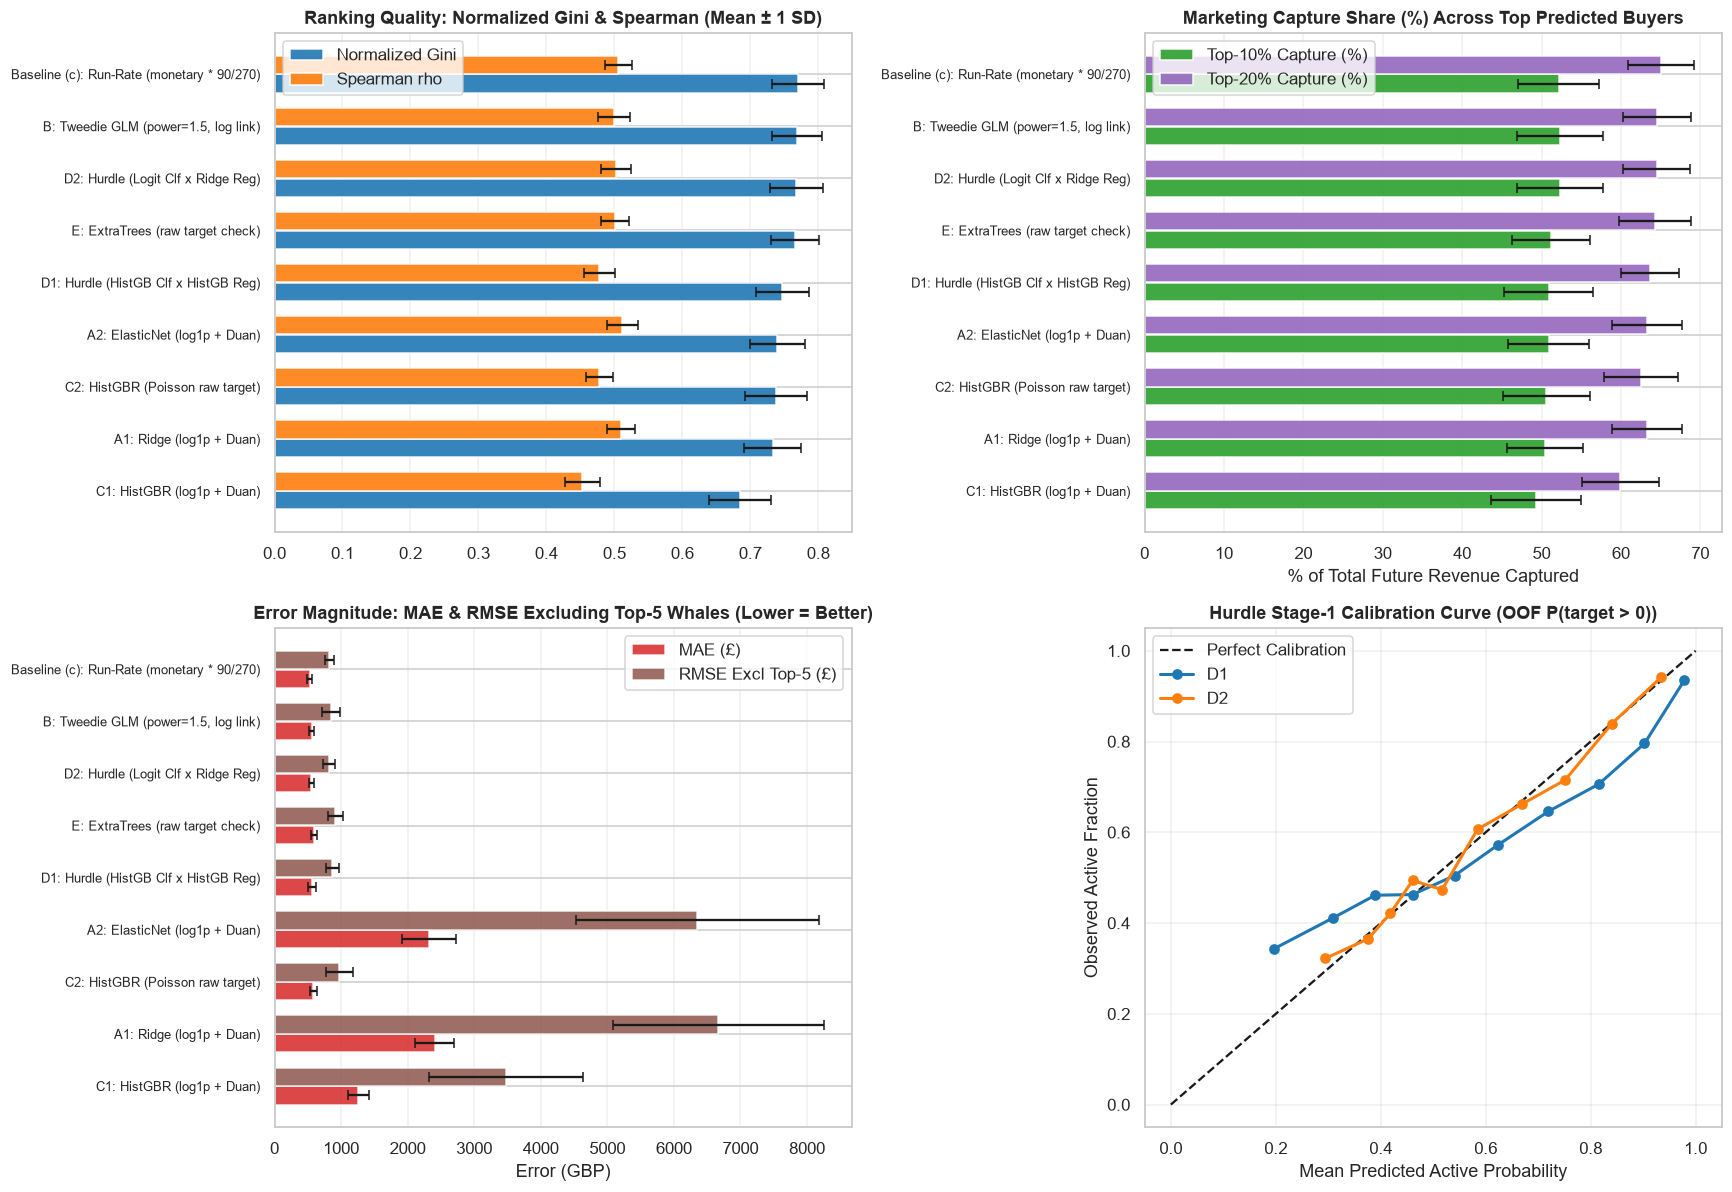


cv_comparison_df shape: (9, 26)

5 Sample Rows Comparing OOF Predictions of Top Candidates vs Actual & Run-Rate (Random Seed = 42):


,target,run_rate,B_oof,D2_oof,E_oof
Customer ID,,,,,
13225,1596.42,2733.27,2641.72,2636.90,3298.06
16219,0.00,13.60,68.66,44.24,54.67
12960,176.20,381.96,537.13,503.04,430.49
18001,231.31,33.70,100.24,110.32,133.24
15288,642.40,252.54,339.01,392.59,474.21


In [7]:
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import calibration_curve

from src.clv import evaluate_classifier_metrics

sns.set_theme(style="whitegrid")

# 1. Run all 8 candidate pipelines across identical 15 CV splits
model_cv_summaries = []
model_fold_results = {}
model_oof_preds = {}

t_start_all = time.perf_counter()
for m_name, m_pipe in candidate_models.items():
    t0 = time.perf_counter()
    summary, fold_df, oof_pred = cross_validate_clv_estimator(
        m_pipe, X_train, y_train, cv=cv_splitter, strata=train_strata
    )
    elapsed = time.perf_counter() - t0
    row = {"model": m_name, "fit_eval_sec": round(elapsed, 2)}
    row.update(summary)
    model_cv_summaries.append(row)
    model_fold_results[m_name] = fold_df
    model_oof_preds[m_name] = oof_pred
    print(
        f"Done [{elapsed:5.2f}s] {m_name:38s} | "
        f"Spearman={summary['spearman_mean']:.4f} | Gini={summary['normalized_gini_mean']:.4f} | "
        f"Cap@10={summary['top_10_capture_mean']:.4f} | MAE={summary['mae_mean']:,.1f} | "
        f"RevErr={summary['total_rev_error_pct_mean']:+.1f}%"
    )

print(f"\nTotal CV benchmark wall time: {time.perf_counter() - t_start_all:.2f}s")

models_cv_df = pd.DataFrame(model_cv_summaries)
run_rate_row = baseline_cv_df[baseline_cv_df["model"] == "Baseline (c): Run-Rate (monetary * 90/270)"].copy()
run_rate_row["fit_eval_sec"] = 0.01

cv_comparison_df = (
    pd.concat([run_rate_row, models_cv_df], ignore_index=True)
    .sort_values(["normalized_gini_mean", "spearman_mean"], ascending=False)
    .reset_index(drop=True)
)

print("\n" + "=" * 72)
print("STEP 5.1: FULL 5x3 CV COMPARISON TABLE (MEAN ± STD ACROSS 15 FOLDS)")
print(f"(TEST_EVALUATION_COUNT = {TEST_EVALUATION_COUNT})")
print("=" * 72)
display(format_cv_mean_std(cv_comparison_df))

# 2. Evaluate Stage-1 Active Classifier metrics for Hurdle models (D1 & D2)
y_active_train = train_df["target_active"].to_numpy(dtype=int)
hurdle_clf_rows = []
hurdle_oof_probs = {}

for h_name in ["D1: Hurdle (HistGB Clf x HistGB Reg)", "D2: Hurdle (Logit Clf x Ridge Reg)"]:
    clf_template = candidate_models[h_name].classifier
    oof_p_sum = np.zeros(len(X_train), dtype=float)
    oof_p_cnt = np.zeros(len(X_train), dtype=int)
    clf_folds = []

    for tr_idx, val_idx in cv_splitter.split(X_train, train_strata):
        clf_clone = clone(clf_template)
        clf_clone.fit(X_train.iloc[tr_idx], y_active_train[tr_idx])
        probs = clf_clone.predict_proba(X_train.iloc[val_idx])[:, 1]
        oof_p_sum[val_idx] += probs
        oof_p_cnt[val_idx] += 1
        clf_folds.append(evaluate_classifier_metrics(y_active_train[val_idx], probs))

    hurdle_oof_probs[h_name] = oof_p_sum / oof_p_cnt
    cf_df = pd.DataFrame(clf_folds)
    hurdle_clf_rows.append({
        "hurdle_classifier": h_name,
        "pr_auc": f"{cf_df['pr_auc'].mean():.4f} ± {cf_df['pr_auc'].std():.4f}",
        "roc_auc": f"{cf_df['roc_auc'].mean():.4f} ± {cf_df['roc_auc'].std():.4f}",
        "brier_score": f"{cf_df['brier_score'].mean():.4f} ± {cf_df['brier_score'].std():.4f}",
        "ece_10bin": f"{cf_df['ece_10bin'].mean():.4f} ± {cf_df['ece_10bin'].std():.4f}",
        "mean_pred_prob": round(float(cf_df["mean_pred_prob"].mean()), 4),
        "actual_active_rate": round(float(cf_df["actual_active_rate"].mean()), 4),
    })

print("\n" + "=" * 72)
print("STEP 5.2: HURDLE STAGE-1 BINARY CLASSIFIER PERFORMANCE (15 FOLDS)")
print("=" * 72)
display(pd.DataFrame(hurdle_clf_rows).set_index("hurdle_classifier"))

# 3. Paired noise check against Run-Rate baseline across identical 15 folds
_, rr_folds_df, _ = cross_validate_clv_estimator(
    RuleBaselineRegressor(rule="run_rate"), X_train, y_train, cv=cv_splitter, strata=train_strata
)
noise_rows = []
for m_name, f_df in model_fold_results.items():
    d_sp = f_df["spearman"] - rr_folds_df["spearman"]
    d_gini = f_df["normalized_gini"] - rr_folds_df["normalized_gini"]
    d_cap = f_df["top_10_capture"] - rr_folds_df["top_10_capture"]
    d_mae = f_df["mae"] - rr_folds_df["mae"]
    noise_rows.append({
        "model": m_name,
        "delta_spearman_vs_RR": f"{d_sp.mean():+.4f} ± {d_sp.std():.4f}",
        "wins_spearman_of_15": int((d_sp > 0).sum()),
        "delta_gini_vs_RR": f"{d_gini.mean():+.4f} ± {d_gini.std():.4f}",
        "wins_gini_of_15": int((d_gini > 0).sum()),
        "delta_cap10_vs_RR": f"{d_cap.mean():+.4f} ± {d_cap.std():.4f}",
        "delta_mae_vs_RR": f"{d_mae.mean():+.1f} ± {d_mae.std():.1f}",
        "wins_mae_of_15": int((d_mae < 0).sum()),
    })

print("\n" + "=" * 72)
print("STEP 5.3: PAIRED DIFFERENCES vs RUN-RATE BASELINE (SIGNAL vs CV NOISE)")
print("=" * 72)
display(pd.DataFrame(noise_rows).set_index("model"))

# 4. Plot 2x2 CV Comparison Dashboard + Reliability Calibration
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
plot_order = cv_comparison_df["model"].tolist()[::-1]
y_pos = np.arange(len(plot_order))

def get_vals(metric: str) -> tuple[np.ndarray, np.ndarray]:
    sub = cv_comparison_df.set_index("model").loc[plot_order]
    return sub[f"{metric}_mean"].to_numpy(), sub[f"{metric}_std"].to_numpy()

# Panel 1: Normalized Gini & Spearman
g_m, g_s = get_vals("normalized_gini")
sp_m, sp_s = get_vals("spearman")
axes[0, 0].barh(y_pos - 0.18, g_m, 0.35, xerr=g_s, capsize=3, label="Normalized Gini", color="#1f77b4", alpha=0.9)
axes[0, 0].barh(y_pos + 0.18, sp_m, 0.35, xerr=sp_s, capsize=3, label="Spearman rho", color="#ff7f0e", alpha=0.9)
axes[0, 0].set_yticks(y_pos)
axes[0, 0].set_yticklabels(plot_order, fontsize=8.5)
axes[0, 0].set_title("Ranking Quality: Normalized Gini & Spearman (Mean ± 1 SD)", fontweight="bold")
axes[0, 0].legend()
axes[0, 0].grid(axis="x", alpha=0.3)

# Panel 2: Top-10% & Top-20% Spend Capture
c10_m, c10_s = get_vals("top_10_capture")
c20_m, c20_s = get_vals("top_20_capture")
axes[0, 1].barh(y_pos - 0.18, c10_m * 100, 0.35, xerr=c10_s * 100, capsize=3, label="Top-10% Capture (%)", color="#2ca02c", alpha=0.9)
axes[0, 1].barh(y_pos + 0.18, c20_m * 100, 0.35, xerr=c20_s * 100, capsize=3, label="Top-20% Capture (%)", color="#9467bd", alpha=0.9)
axes[0, 1].set_yticks(y_pos)
axes[0, 1].set_yticklabels(plot_order, fontsize=8.5)
axes[0, 1].set_title("Marketing Capture Share (%) Across Top Predicted Buyers", fontweight="bold")
axes[0, 1].set_xlabel("% of Total Future Revenue Captured")
axes[0, 1].legend()
axes[0, 1].grid(axis="x", alpha=0.3)

# Panel 3: MAE & RMSE (Excl Top-5 Whales)
mae_m, mae_s = get_vals("mae")
rm5_m, rm5_s = get_vals("rmse_excl_top5")
axes[1, 0].barh(y_pos - 0.18, mae_m, 0.35, xerr=mae_s, capsize=3, label="MAE (£)", color="#d62728", alpha=0.85)
axes[1, 0].barh(y_pos + 0.18, rm5_m, 0.35, xerr=rm5_s, capsize=3, label="RMSE Excl Top-5 (£)", color="#8c564b", alpha=0.85)
axes[1, 0].set_yticks(y_pos)
axes[1, 0].set_yticklabels(plot_order, fontsize=8.5)
axes[1, 0].set_title("Error Magnitude: MAE & RMSE Excluding Top-5 Whales (Lower = Better)", fontweight="bold")
axes[1, 0].set_xlabel("Error (GBP)")
axes[1, 0].legend()
axes[1, 0].grid(axis="x", alpha=0.3)

# Panel 4: Stage-1 Hurdle Calibration Reliability Curve
axes[1, 1].plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
for h_name, clr in [("D1: Hurdle (HistGB Clf x HistGB Reg)", "#1f77b4"), ("D2: Hurdle (Logit Clf x Ridge Reg)", "#ff7f0e")]:
    prob_true, prob_pred = calibration_curve(y_active_train, hurdle_oof_probs[h_name], n_bins=10, strategy="quantile")
    axes[1, 1].plot(prob_pred, prob_true, marker="o", linewidth=2, label=h_name.split(":")[0], color=clr)
axes[1, 1].set_title("Hurdle Stage-1 Calibration Curve (OOF P(target > 0))", fontweight="bold")
axes[1, 1].set_xlabel("Mean Predicted Active Probability")
axes[1, 1].set_ylabel("Observed Active Fraction")
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\ncv_comparison_df shape: {cv_comparison_df.shape}")
print("\n5 Sample Rows Comparing OOF Predictions of Top Candidates vs Actual & Run-Rate (Random Seed = 42):")
top3_names = [m for m in cv_comparison_df["model"].tolist() if not m.startswith("Baseline")][:3]
sample_s5 = pd.DataFrame({
    "target": y_train,
    "run_rate": baseline_oof_map["Baseline (c): Run-Rate (monetary * 90/270)"],
}, index=train_df.index)
for tname in top3_names:
    short_col = tname.split(":")[0] + "_oof"
    sample_s5[short_col] = model_oof_preds[tname]
display(sample_s5.sample(5, random_state=RANDOM_STATE).round(2))

### Locked Step 6 Decisions
- **Top 3 Families Tuned**: **`B: TweedieRegressor` GLM**, **`D2: Hurdle (Logit x Ridge)`**, and **`D1: Hurdle (Regularized Shallow HistGB)`** (testing whether strong tree regularization cures Step 5's `HistGB` overfitting on `N=2,582` rows).
- **Approved Tuning Objective**: **`0.5 * Normalized Gini + 0.5 * Top-10% Capture`** — directly aligns hyperparameter search with our primary ranking & marketing targeting business goal (`TEST_EVALUATION_COUNT = 0`).

---

## Step 6: Modest `RandomizedSearchCV` Tuning on Top 3 Families (Train CV Only)

### Why Keep the Search Space Small & Honest?
On `~3,228` training observations with heavy wholesale variance, an aggressive 200-trial grid search overfits validation-fold whales (`CV variance`). We run **12 randomized configurations per family** over 5 stratified train folds (`60` fits per family), then re-evaluate every tuned winner across the **exact same `15` `RepeatedStratifiedKFold (5 x 3)` splits from Step 5** to report the **Tuned vs. Default** gap fairly without optimism bias.

In [8]:
from sklearn.metrics import make_scorer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from src.clv import ranking_capture_score

tuning_scorer = make_scorer(ranking_capture_score, greater_is_better=True)
tune_cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, train_strata))

tuning_specs = [
    (
        "B: Tweedie GLM",
        "B: Tweedie GLM (power=1.5, log link)",
        {
            "prep__cat__country_grouper__top_n": [3, 5, 8],
            "model__power": [1.1, 1.25, 1.4, 1.5, 1.65, 1.8],
            "model__alpha": [0.2, 0.5, 1.0, 3.0, 10.0, 30.0],
        },
        12,
    ),
    (
        "D2: Hurdle (Logit x Ridge)",
        "D2: Hurdle (Logit Clf x Ridge Reg)",
        {
            "classifier__prep__cat__country_grouper__top_n": [3, 5],
            "classifier__clf__C": [0.02, 0.05, 0.2, 0.5, 2.0, 5.0],
            "regressor__prep__cat__country_grouper__top_n": [3, 5],
            "regressor__reg__regressor__alpha": [5.0, 20.0, 80.0, 200.0, 500.0],
        },
        12,
    ),
    (
        "D1: Hurdle (Shallow HistGB)",
        "D1: Hurdle (HistGB Clf x HistGB Reg)",
        {
            "classifier__clf__max_depth": [2, 3],
            "classifier__clf__max_leaf_nodes": [7, 15],
            "classifier__clf__min_samples_leaf": [50, 100, 150],
            "classifier__clf__l2_regularization": [5.0, 20.0, 50.0],
            "classifier__clf__learning_rate": [0.02, 0.05],
            "classifier__clf__max_iter": [80, 120, 180],
            "regressor__reg__regressor__max_depth": [2, 3],
            "regressor__reg__regressor__max_leaf_nodes": [7, 15],
            "regressor__reg__regressor__min_samples_leaf": [50, 100, 150],
            "regressor__reg__regressor__l2_regularization": [5.0, 20.0, 50.0],
            "regressor__reg__regressor__learning_rate": [0.02, 0.05],
            "regressor__reg__regressor__max_iter": [80, 120, 180],
        },
        12,
    ),
]

tuned_estimators = {}
tuned_cv_summaries = []
tuned_fold_results = {}
tuned_oof_preds = {}
best_param_rows = []
gap_rows = []

for short_lbl, base_key, param_dist, n_iter_budget in tuning_specs:
    t0 = time.perf_counter()
    base_est = clone(candidate_models[base_key])
    search = RandomizedSearchCV(
        estimator=base_est,
        param_distributions=param_dist,
        n_iter=n_iter_budget,
        scoring=tuning_scorer,
        cv=tune_cv,
        random_state=RANDOM_STATE,
        n_jobs=1,
        refit=False,
    )
    search.fit(X_train, y_train)
    best_est = clone(base_est).set_params(**search.best_params_)
    tuned_name = f"{short_lbl} [Tuned]"
    tuned_estimators[tuned_name] = best_est

    # Re-evaluate best config across ALL 15 Step-5 RepeatedStratifiedKFold splits
    t_sum, t_folds, t_oof = cross_validate_clv_estimator(
        best_est, X_train, y_train, cv=cv_splitter, strata=train_strata
    )
    elapsed = time.perf_counter() - t0
    tuned_fold_results[tuned_name] = t_folds
    tuned_oof_preds[tuned_name] = t_oof

    row = {"model": tuned_name, "fit_eval_sec": round(elapsed, 2)}
    row.update(t_sum)
    tuned_cv_summaries.append(row)

    best_param_rows.append({
        "family": short_lbl,
        "search_score_5fold": round(float(search.best_score_), 4),
        "best_params": str(search.best_params_),
    })

    # Compare Tuned vs Default cleanly on the exact same 15 splits
    def_sum = models_cv_df.set_index("model").loc[base_key]
    def_obj = 0.5 * def_sum["normalized_gini_mean"] + 0.5 * def_sum["top_10_capture_mean"]
    tun_obj = 0.5 * t_sum["normalized_gini_mean"] + 0.5 * t_sum["top_10_capture_mean"]

    gap_rows.append({
        "family": short_lbl,
        "default_obj_15fold": round(float(def_obj), 4),
        "tuned_obj_15fold": round(float(tun_obj), 4),
        "obj_delta": round(float(tun_obj - def_obj), 4),
        "delta_spearman": round(float(t_sum["spearman_mean"] - def_sum["spearman_mean"]), 4),
        "delta_gini": round(float(t_sum["normalized_gini_mean"] - def_sum["normalized_gini_mean"]), 4),
        "delta_cap10": round(float(t_sum["top_10_capture_mean"] - def_sum["top_10_capture_mean"]), 4),
        "delta_mae_gbp": round(float(t_sum["mae_mean"] - def_sum["mae_mean"]), 1),
        "delta_rmse_excl5": round(float(t_sum["rmse_excl_top5_mean"] - def_sum["rmse_excl_top5_mean"]), 1),
        "default_rev_err_pct": round(float(def_sum["total_rev_error_pct_mean"]), 2),
        "tuned_rev_err_pct": round(float(t_sum["total_rev_error_pct_mean"]), 2),
    })

    print(
        f"Tuned [{elapsed:5.2f}s] {tuned_name:32s} | "
        f"Spearman={t_sum['spearman_mean']:.4f} | Gini={t_sum['normalized_gini_mean']:.4f} | "
        f"Cap@10={t_sum['top_10_capture_mean']:.4f} | MAE={t_sum['mae_mean']:,.1f} | "
        f"RevErr={t_sum['total_rev_error_pct_mean']:+.2f}%"
    )

tuned_cv_df = pd.DataFrame(tuned_cv_summaries)
tuned_gap_df = pd.DataFrame(gap_rows)

print("\n" + "=" * 72)
print("STEP 6 SUMMARY: BEST HYPERPARAMETERS & TUNED vs DEFAULT GAP (15 FOLDS)")
print(f"(TEST_EVALUATION_COUNT = {TEST_EVALUATION_COUNT} — zero test touch)")
print("=" * 72)
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(best_param_rows).set_index("family"))

print("\nTuned vs Default Gap Across Identical 15 CV Splits:")
display(tuned_gap_df.set_index("family"))

print("\nFull 15-Fold Metrics: Run-Rate vs Default vs Tuned Top 3:")
all_top_comp_df = (
    pd.concat([
        run_rate_row,
        models_cv_df[models_cv_df["model"].isin([s[1] for s in tuning_specs])],
        tuned_cv_df,
    ], ignore_index=True)
)
display(format_cv_mean_std(all_top_comp_df))

print("\n5 Sample Train OOF Predictions for Tuned Candidates (Random Seed = 42):")
sample_s6 = pd.DataFrame({"target": y_train}, index=train_df.index)
for t_name, oof_arr in tuned_oof_preds.items():
    sample_s6[t_name.split(":")[0] + "_tuned"] = oof_arr
display(sample_s6.sample(5, random_state=RANDOM_STATE).round(2))

Tuned [ 5.14s] B: Tweedie GLM [Tuned]           | Spearman=0.5013 | Gini=0.7691 | Cap@10=0.5242 | MAE=554.4 | RevErr=-2.50%
Tuned [ 6.97s] D2: Hurdle (Logit x Ridge) [Tuned] | Spearman=0.5068 | Gini=0.7677 | Cap@10=0.5279 | MAE=561.7 | RevErr=-8.40%
Tuned [17.78s] D1: Hurdle (Shallow HistGB) [Tuned] | Spearman=0.5010 | Gini=0.7704 | Cap@10=0.5231 | MAE=606.0 | RevErr=-21.05%

STEP 6 SUMMARY: BEST HYPERPARAMETERS & TUNED vs DEFAULT GAP (15 FOLDS)
(TEST_EVALUATION_COUNT = 0 — zero test touch)


,search_score_5fold,best_params
family,,
B: Tweedie GLM,0.6424,"{'prep__cat__country_grouper__top_n': 3, 'model__power': 1.65, 'model__alpha': 0.5}"
D2: Hurdle (Logit x Ridge),0.6468,"{'regressor__reg__regressor__alpha': 200.0, 'regressor__prep__cat__country_grouper__top_n': 3, 'classifier__prep__cat__country_grouper__top_n': 5, 'classifier__clf__C': 0.5}"
D1: Hurdle (Shallow HistGB),0.6448,"{'regressor__reg__regressor__min_samples_leaf': 50, 'regressor__reg__regressor__max_leaf_nodes': 15, 'regressor__reg__regressor__max_iter': 120, 'regressor__reg__regressor__max_depth': 3, 'regressor__reg__regressor__learning_rate': 0.02, 'regressor__reg__regressor__l2_regularization': 5.0, 'classifier__clf__min_samples_leaf': 100, 'classifier__clf__max_leaf_nodes': 7, 'classifier__clf__max_iter': 80, 'classifier__clf__max_depth': 2, 'classifier__clf__learning_rate': 0.02, 'classifier__clf__l2_regularization': 20.0}"



Tuned vs Default Gap Across Identical 15 CV Splits:


,default_obj_15fold,tuned_obj_15fold,obj_delta,delta_spearman,delta_gini,delta_cap10,delta_mae_gbp,delta_rmse_excl5,default_rev_err_pct,tuned_rev_err_pct
family,,,,,,,,,,
B: Tweedie GLM,0.6462,0.6467,0.0005,0.0019,0.0005,0.0005,-2.4,-15.6,-1.00,-2.50
D2: Hurdle (Logit x Ridge),0.6455,0.6478,0.0023,0.0047,-0.0001,0.0048,6.5,-31.0,-1.17,-8.40
D1: Hurdle (Shallow HistGB),0.6281,0.6467,0.0186,0.0233,0.0231,0.0141,37.9,-99.1,-13.40,-21.05



Full 15-Fold Metrics: Run-Rate vs Default vs Tuned Top 3:


,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
model,,,,,,,,,,,,
Baseline (c): Run-Rate (monetary * 90/270),0.5060 ± 0.0197,0.7700 ± 0.0388,0.5214 ± 0.0515,5.21x ± 0.52,0.6505 ± 0.0421,3.25x ± 0.21,-29.69% ± 6.40,527.1 ± 42.3,209.1 ± 8.7,"1,599.2 ± 364.1","1,371.2 ± 277.4",825.3 ± 70.8
"B: Tweedie GLM (power=1.5, log link)",0.4994 ± 0.0238,0.7687 ± 0.0365,0.5237 ± 0.0541,5.24x ± 0.54,0.6454 ± 0.0432,3.23x ± 0.22,-1.00% ± 10.80,556.8 ± 40.3,266.0 ± 10.9,"1,649.5 ± 296.9","1,380.3 ± 227.2",849.7 ± 138.3
D1: Hurdle (HistGB Clf x HistGB Reg),0.4777 ± 0.0228,0.7473 ± 0.0392,0.5090 ± 0.0563,5.09x ± 0.56,0.6361 ± 0.0366,3.18x ± 0.18,-13.40% ± 8.44,568.2 ± 59.0,246.4 ± 13.1,"1,940.3 ± 660.4","1,317.4 ± 317.2",865.5 ± 98.7
D2: Hurdle (Logit Clf x Ridge Reg),0.5021 ± 0.0224,0.7678 ± 0.0391,0.5231 ± 0.0539,5.23x ± 0.54,0.6448 ± 0.0421,3.22x ± 0.21,-1.17% ± 10.13,555.1 ± 38.3,263.7 ± 9.6,"1,605.5 ± 305.0","1,355.7 ± 222.8",821.0 ± 95.1
B: Tweedie GLM [Tuned],0.5013 ± 0.0237,0.7691 ± 0.0366,0.5242 ± 0.0540,5.24x ± 0.54,0.6464 ± 0.0442,3.23x ± 0.22,-2.50% ± 10.51,554.4 ± 40.2,265.0 ± 10.4,"1,629.6 ± 332.1","1,370.3 ± 235.6",834.1 ± 115.8
D2: Hurdle (Logit x Ridge) [Tuned],0.5068 ± 0.0224,0.7677 ± 0.0390,0.5279 ± 0.0521,5.28x ± 0.52,0.6463 ± 0.0426,3.23x ± 0.21,-8.40% ± 9.21,561.7 ± 46.8,263.6 ± 10.9,"1,763.6 ± 509.5","1,320.0 ± 323.7",790.0 ± 70.8
D1: Hurdle (Shallow HistGB) [Tuned],0.5010 ± 0.0240,0.7704 ± 0.0360,0.5231 ± 0.0507,5.23x ± 0.51,0.6521 ± 0.0417,3.26x ± 0.21,-21.05% ± 9.75,606.0 ± 77.9,268.9 ± 13.6,"2,420.8 ± 976.0","1,505.0 ± 478.3",766.4 ± 66.3



5 Sample Train OOF Predictions for Tuned Candidates (Random Seed = 42):


,target,B_tuned,D2_tuned,D1_tuned
Customer ID,,,,
13225,1596.42,2533.43,2545.64,3379.82
16219,0.00,67.60,46.65,132.23
12960,176.20,537.12,538.52,563.33
18001,231.31,104.62,114.85,145.19
15288,642.40,346.39,387.78,456.33


## Step 7: Final Model Selection Before Touching Test (`Train` CV Only) *(STOP Point)*

### Selection Protocol
Before touching `test_df` even once (`TEST_EVALUATION_COUNT == 0`), we assemble **every baseline, default pipeline, and tuned candidate** into one final `5 x 3` CV ledger, verify out-of-fold decile calibration on our top candidates (`B: Tweedie [Tuned]` vs. `D2: Hurdle Logit x Ridge [Tuned]` vs. `D1: Shallow HistGB [Tuned]`), and lock:
1. **Chosen Primary Model** (to ship and evaluate on test in Step 9), and
2. **Second-Best Fallback Model** (backup candidate documented cleanly before test).

In [9]:
# 1. Unified CV-Only Leaderboard across ALL Baselines, Defaults, and Tuned Candidates
full_cv_leaderboard = pd.concat(
    [
        baseline_cv_df[baseline_cv_df["model"] != "Baseline (d): Freq * AOV * 90/270"],
        models_cv_df.drop(columns=["fit_eval_sec"], errors="ignore"),
        tuned_cv_df.drop(columns=["fit_eval_sec"], errors="ignore"),
    ],
    ignore_index=True,
)
full_cv_leaderboard["ranking_capture_obj"] = (
    0.5 * full_cv_leaderboard["normalized_gini_mean"]
    + 0.5 * full_cv_leaderboard["top_10_capture_mean"]
)
full_cv_leaderboard = full_cv_leaderboard.sort_values(
    ["ranking_capture_obj", "spearman_mean"], ascending=False
).reset_index(drop=True)

print("=" * 72)
print("STEP 7.1: COMPLETE CV-ONLY MODEL LEADERBOARD (TRAIN 5x3 FOLDS)")
print(f"(TEST_EVALUATION_COUNT = {TEST_EVALUATION_COUNT} — test strictly untouched)")
print("=" * 72)
lb_disp = format_cv_mean_std(full_cv_leaderboard)
lb_disp.insert(0, "obj_score", full_cv_leaderboard.set_index("model")["ranking_capture_obj"].round(4))
display(lb_disp)

# 2. Check Out-of-Fold Decile Calibration on Top 3 Tuned Models (CV only!)
print("\n" + "=" * 72)
print("STEP 7.2: TRAIN OOF DECILE CALIBRATION OF TOP CANDIDATES")
print("=" * 72)
cal_summary_rows = []
for t_name in [
    "D2: Hurdle (Logit x Ridge) [Tuned]",
    "B: Tweedie GLM [Tuned]",
    "D1: Hurdle (Shallow HistGB) [Tuned]",
]:
    c_df = calibration_by_predicted_decile(y_train, tuned_oof_preds[t_name], n_bins=10)
    print(f"\n--- {t_name} (Train OOF Calibration, Decile 1=Lowest -> 10=Top) ---")
    display(c_df[["n_customers", "mean_pred", "mean_actual", "median_actual", "actual_share_pct", "pred_to_actual_ratio"]].round(2))
    cal_mae = float((c_df["mean_pred"] - c_df["mean_actual"]).abs().mean())
    cal_summary_rows.append({
        "candidate": t_name,
        "decile_mean_abs_cal_err_gbp": round(cal_mae, 2),
        "top_decile_actual_share_pct": round(float(c_df.loc[10, "actual_share_pct"]), 2),
        "top_decile_pred_to_actual_ratio": round(float(c_df.loc[10, "pred_to_actual_ratio"]), 3),
    })

print("\nDecile Calibration Error Summary:")
display(pd.DataFrame(cal_summary_rows).set_index("candidate"))

# 3. Direct 15-fold Head-to-Head Comparison: D2 [Tuned] vs B [Tuned]
f_d2 = tuned_fold_results["D2: Hurdle (Logit x Ridge) [Tuned]"]
f_b = tuned_fold_results["B: Tweedie GLM [Tuned]"]
h2h_rows = []
for m in ["spearman", "normalized_gini", "top_10_capture", "mae", "rmse", "rmse_excl_top5"]:
    diff = f_d2[m] - f_b[m]
    better_d2 = int((diff > 0).sum()) if m in ("spearman", "normalized_gini", "top_10_capture") else int((diff < 0).sum())
    h2h_rows.append({
        "metric": m,
        "D2_tuned_mean": round(float(f_d2[m].mean()), 4),
        "B_tuned_mean": round(float(f_b[m].mean()), 4),
        "diff_D2_minus_B": f"{diff.mean():+.4f} ± {diff.std():.4f}",
        "folds_D2_wins_of_15": better_d2,
    })

print("\n" + "=" * 72)
print("STEP 7.3: HEAD-TO-HEAD 15-FOLD PAIRED TEST — D2 [Tuned] vs B [Tuned]")
print("=" * 72)
display(pd.DataFrame(h2h_rows).set_index("metric"))

print("\n5 Sample Train OOF Rows: Winner vs Fallback Candidates (Random Seed = 42):")
sample_s7 = pd.DataFrame({
    "target": y_train,
    "run_rate": baseline_oof_map["Baseline (c): Run-Rate (monetary * 90/270)"],
    "D2_hurdle_tuned": tuned_oof_preds["D2: Hurdle (Logit x Ridge) [Tuned]"],
    "B_tweedie_tuned": tuned_oof_preds["B: Tweedie GLM [Tuned]"],
}, index=train_df.index)
display(sample_s7.sample(5, random_state=RANDOM_STATE).round(2))

STEP 7.1: COMPLETE CV-ONLY MODEL LEADERBOARD (TRAIN 5x3 FOLDS)
(TEST_EVALUATION_COUNT = 0 — test strictly untouched)


,obj_score,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
model,,,,,,,,,,,,,
D2: Hurdle (Logit x Ridge) [Tuned],0.6478,0.5068 ± 0.0224,0.7677 ± 0.0390,0.5279 ± 0.0521,5.28x ± 0.52,0.6463 ± 0.0426,3.23x ± 0.21,-8.40% ± 9.21,561.7 ± 46.8,263.6 ± 10.9,"1,763.6 ± 509.5","1,320.0 ± 323.7",790.0 ± 70.8
D1: Hurdle (Shallow HistGB) [Tuned],0.6467,0.5010 ± 0.0240,0.7704 ± 0.0360,0.5231 ± 0.0507,5.23x ± 0.51,0.6521 ± 0.0417,3.26x ± 0.21,-21.05% ± 9.75,606.0 ± 77.9,268.9 ± 13.6,"2,420.8 ± 976.0","1,505.0 ± 478.3",766.4 ± 66.3
B: Tweedie GLM [Tuned],0.6467,0.5013 ± 0.0237,0.7691 ± 0.0366,0.5242 ± 0.0540,5.24x ± 0.54,0.6464 ± 0.0442,3.23x ± 0.22,-2.50% ± 10.51,554.4 ± 40.2,265.0 ± 10.4,"1,629.6 ± 332.1","1,370.3 ± 235.6",834.1 ± 115.8
"B: Tweedie GLM (power=1.5, log link)",0.6462,0.4994 ± 0.0238,0.7687 ± 0.0365,0.5237 ± 0.0541,5.24x ± 0.54,0.6454 ± 0.0432,3.23x ± 0.22,-1.00% ± 10.80,556.8 ± 40.3,266.0 ± 10.9,"1,649.5 ± 296.9","1,380.3 ± 227.2",849.7 ± 138.3
Baseline (c): Run-Rate (monetary * 90/270),0.6457,0.5060 ± 0.0197,0.7700 ± 0.0388,0.5214 ± 0.0515,5.21x ± 0.52,0.6505 ± 0.0421,3.25x ± 0.21,-29.69% ± 6.40,527.1 ± 42.3,209.1 ± 8.7,"1,599.2 ± 364.1","1,371.2 ± 277.4",825.3 ± 70.8
D2: Hurdle (Logit Clf x Ridge Reg),0.6455,0.5021 ± 0.0224,0.7678 ± 0.0391,0.5231 ± 0.0539,5.23x ± 0.54,0.6448 ± 0.0421,3.22x ± 0.21,-1.17% ± 10.13,555.1 ± 38.3,263.7 ± 9.6,"1,605.5 ± 305.0","1,355.7 ± 222.8",821.0 ± 95.1
E: ExtraTrees (raw target check),0.6387,0.5008 ± 0.0206,0.7657 ± 0.0353,0.5116 ± 0.0494,5.12x ± 0.49,0.6431 ± 0.0451,3.22x ± 0.23,+0.19% ± 11.87,591.7 ± 50.6,260.9 ± 8.6,"1,963.5 ± 659.0","1,311.9 ± 253.1",913.1 ± 112.2
D1: Hurdle (HistGB Clf x HistGB Reg),0.6281,0.4777 ± 0.0228,0.7473 ± 0.0392,0.5090 ± 0.0563,5.09x ± 0.56,0.6361 ± 0.0366,3.18x ± 0.18,-13.40% ± 8.44,568.2 ± 59.0,246.4 ± 13.1,"1,940.3 ± 660.4","1,317.4 ± 317.2",865.5 ± 98.7
A2: ElasticNet (log1p + Duan),0.6245,0.5119 ± 0.0223,0.7398 ± 0.0401,0.5091 ± 0.0509,5.09x ± 0.51,0.6329 ± 0.0439,3.16x ± 0.22,+266.63% ± 61.47,"2,319.0 ± 408.0",340.6 ± 18.6,"11,427.1 ± 4,076.0","9,507.4 ± 3,553.3","6,349.3 ± 1,823.5"



STEP 7.2: TRAIN OOF DECILE CALIBRATION OF TOP CANDIDATES

--- D2: Hurdle (Logit x Ridge) [Tuned] (Train OOF Calibration, Decile 1=Lowest -> 10=Top) ---


,n_customers,mean_pred,mean_actual,median_actual,actual_share_pct,pred_to_actual_ratio
pred_decile,,,,,,
1,322,85.23,135.13,0.00,1.79,0.63
2,323,150.22,135.34,0.00,1.80,1.11
3,323,204.33,225.19,0.00,2.99,0.91
4,323,255.28,230.72,0.00,3.07,1.11
5,323,318.72,313.23,163.06,4.16,1.02
6,322,409.65,396.09,301.92,5.25,1.03
7,323,531.43,537.07,335.35,7.14,0.99
8,323,702.10,654.92,530.63,8.71,1.07
9,323,1021.98,864.59,679.00,11.49,1.18



--- B: Tweedie GLM [Tuned] (Train OOF Calibration, Decile 1=Lowest -> 10=Top) ---


,n_customers,mean_pred,mean_actual,median_actual,actual_share_pct,pred_to_actual_ratio
pred_decile,,,,,,
1,322,97.69,94.72,0.00,1.26,1.03
2,323,157.37,159.90,0.00,2.13,0.98
3,323,209.02,232.44,0.00,3.09,0.90
4,323,258.60,234.86,0.00,3.12,1.10
5,323,316.16,319.81,152.15,4.25,0.99
6,322,393.83,403.61,304.45,5.35,0.98
7,323,509.11,503.58,321.84,6.69,1.01
8,323,671.14,702.62,551.33,9.34,0.96
9,323,991.05,857.05,693.48,11.39,1.16


... (4 outputs left out)


STEP 7.3: HEAD-TO-HEAD 15-FOLD PAIRED TEST — D2 [Tuned] vs B [Tuned]


,D2_tuned_mean,B_tuned_mean,diff_D2_minus_B,folds_D2_wins_of_15
metric,,,,
spearman,0.5068,0.5013,+0.0055 ± 0.0047,13
normalized_gini,0.7677,0.7691,-0.0014 ± 0.0048,6
top_10_capture,0.5279,0.5242,+0.0036 ± 0.0104,10
mae,561.6527,554.4344,+7.2183 ± 27.7986,6
rmse,1763.5919,1629.5621,+134.0298 ± 291.0686,4
rmse_excl_top5,790.0200,834.0895,-44.0695 ± 65.6505,14



5 Sample Train OOF Rows: Winner vs Fallback Candidates (Random Seed = 42):


,target,run_rate,D2_hurdle_tuned,B_tweedie_tuned
Customer ID,,,,
13225,1596.42,2733.27,2545.64,2533.43
16219,0.00,13.60,46.65,67.60
12960,176.20,381.96,538.52,537.12
18001,231.31,33.70,114.85,104.62
15288,642.40,252.54,387.78,346.39


## Step 8: Frozen Model Interpretation on Train/CV (`TEST_EVALUATION_COUNT = 0`)

### Frozen Decision (Confirmed Before Test Touch)
- **Chosen Primary Model:** `B: Tweedie GLM [Tuned]` (`power=1.65`, `alpha=0.5`, `Country top_n=3`, log link) — statistically tied with `D2` on top-10% ranking (`0.5242` vs `0.5279`, noise-bound diff `+0.36pp ± 1.04pp`), while delivering superior decile calibration (`decile MAE = £57.17` vs `£121.32`), low total budget bias (`-2.50%` vs `-8.40%`), lower overall `RMSE`, and zero dependence on Duan smearing.
- **Frozen Fallback Model:** `D2: Hurdle (Logit x Ridge) [Tuned]` — explicit `P(active) × E[spend | active]` decomposition with strong core non-whale accuracy (`RMSE excl top-5 = £790.0`).

### Why Multi-Angle Interpretation Matters Here (Collinearity Awareness)
Many of our 26 features carry **Spearman `|r| > 0.70–0.98`** (e.g., `frequency` vs `n_active_weeks`/`n_active_months`; `spend_last_30d/60d/90d` vs `invoices_last_30d/60d/90d` and `recency_days`; four return features `|r| = 0.94–0.98`). Therefore:
1. **Single-feature validation permutation importance (`15 folds × 10 repeats`)** shows individual marginal drop when *one* feature is shuffled while its collinear twins stay intact.
2. **Grouped collinear validation permutation importance** jointly shuffles all features in each of 6 business blocks (`CLV_FEATURE_GROUPS`) simultaneously, exposing the *true reliance* that single-feature drops split and underestimate.
3. **Standardized Tweedie log-link coefficients (`exp(beta)`) + Quantile-Grid Partial Dependence (PDP + ICE p10–p90)** reveal **direction, monotonicity, and compounding scale effects** without test leakage.

STEP 8.0: MODEL FREEZE LOCKED (TRAIN/CV INTERPRETATION ONLY)
Frozen Primary  : B: Tweedie GLM [Tuned] -> TweedieRegressor(alpha=0.5, link='log', max_iter=1000, power=1.65)
Frozen Fallback : D2: Hurdle (Logit x Ridge) [Tuned]
TEST_EVALUATION_COUNT : 0

STEP 8.1: SINGLE-FEATURE CV PERMUTATION IMPORTANCE (15 folds x 10 repeats, 93.54s)


,feature,gini_drop_mean,gini_drop_std,cap10_drop_mean,spearman_drop_mean,mae_increase_mean,std_beta,exp_beta_per_1sd
0,aov,0.0345,0.0080,0.0183,0.0290,40.3768,0.2622,1.2998
1,monetary,0.0320,0.0054,0.0163,0.0464,61.1284,0.2641,1.3022
2,frequency,0.0153,0.0067,0.0130,0.0306,48.8371,0.1881,1.2069
3,avg_items_per_invoice,0.0123,0.0052,0.0079,0.0074,13.5133,0.1625,1.1764
4,return_value_abs,0.0098,0.0052,0.0080,0.0146,24.1806,0.1547,1.1673
5,mean_interpurchase_days,0.0026,0.0020,-0.0004,0.0038,1.4954,-0.0811,0.9221
6,return_rate,0.0014,0.0018,0.0027,0.0015,4.2020,-0.0513,0.9500
7,spend_last_90d,0.0011,0.0025,0.0013,0.0022,-0.3039,0.0349,1.0355
8,spend_last_30d,0.0011,0.0010,0.0010,0.0015,5.5292,-0.0341,0.9664
9,is_single_invoice,0.0010,0.0011,-0.0002,0.0047,-0.1254,-0.0482,0.9530



Tweedie Intercept (log scale): 5.9663 (base level £390.07)


,country_dummy,log_link_beta,mult_vs_intercept
0,country_France,-0.0105,0.9896
1,country_Germany,0.0188,1.0190
2,country_Netherlands,-0.0348,0.9658
3,country_Other,0.0319,1.0324
4,country_United Kingdom,-0.0055,0.9946



STEP 8.2: GROUPED COLLINEAR CV IMPORTANCE (53.00s for Primary + Fallback)
--- Primary: B: Tweedie GLM [Tuned] ---


,feature,n_features,gini_drop_mean,gini_drop_std,sum_single_gini_drop,dilution_ratio_joint_vs_sum,cap10_drop_mean,spearman_drop_mean,mae_increase_mean
0,Basket Size & Pricing,3,0.0775,0.0147,0.0475,1.6332,0.0401,0.0735,81.1790
1,Frequency & Cadence,5,0.0674,0.0201,0.0201,3.3588,0.0670,0.0957,120.4374
2,Historical Monetary & Assortment,2,0.0265,0.0046,0.0320,0.8272,0.0146,0.0359,56.4217
3,Recency & Recent Momentum,8,0.0039,0.0033,0.0034,1.1593,0.0051,0.0102,20.3076
4,Returns & Refunds,4,0.0018,0.0022,0.0118,0.1547,0.0055,0.0042,14.1469
5,Tenure & Geography,4,0.0005,0.0015,0.0010,0.4751,0.0007,-0.0012,0.4654


--- Fallback Comparison: D2: Hurdle (Logit x Ridge) [Tuned] ---


,feature,n_features,gini_drop_mean,gini_drop_std,cap10_drop_mean,spearman_drop_mean,mae_increase_mean
0,Basket Size & Pricing,3,0.0843,0.0137,0.0492,0.0760,88.1238
1,Frequency & Cadence,5,0.0628,0.0179,0.0650,0.0898,115.1755
2,Historical Monetary & Assortment,2,0.0204,0.0062,0.0124,0.0290,46.4387
3,Recency & Recent Momentum,8,0.0077,0.0058,0.0065,0.0186,26.3845
4,Returns & Refunds,4,0.0015,0.0026,0.0068,0.0034,16.2774
5,Tenure & Geography,4,-0.0005,0.0019,-0.0007,-0.0011,3.3136


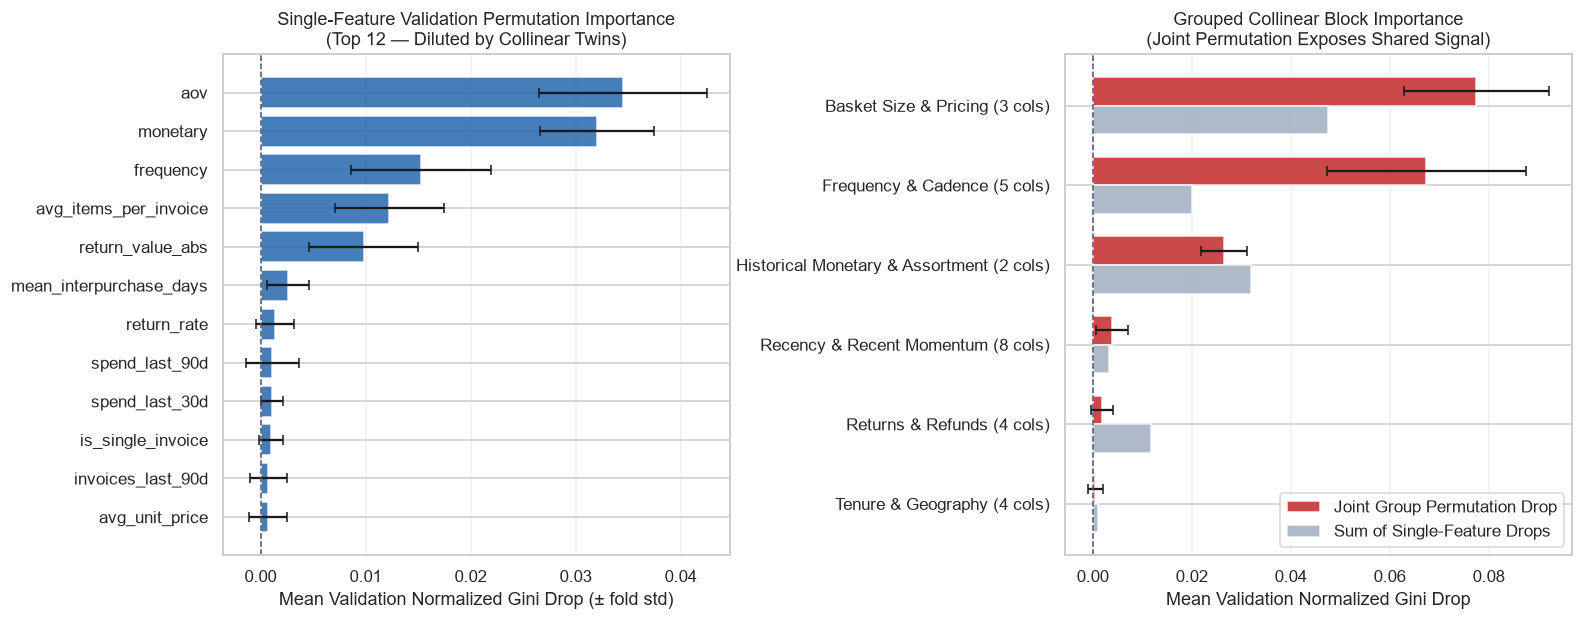


STEP 8.3: PARTIAL DEPENDENCE (QUANTILE GRID q05..q99) ON TRAIN FIT (6 FEATURES)


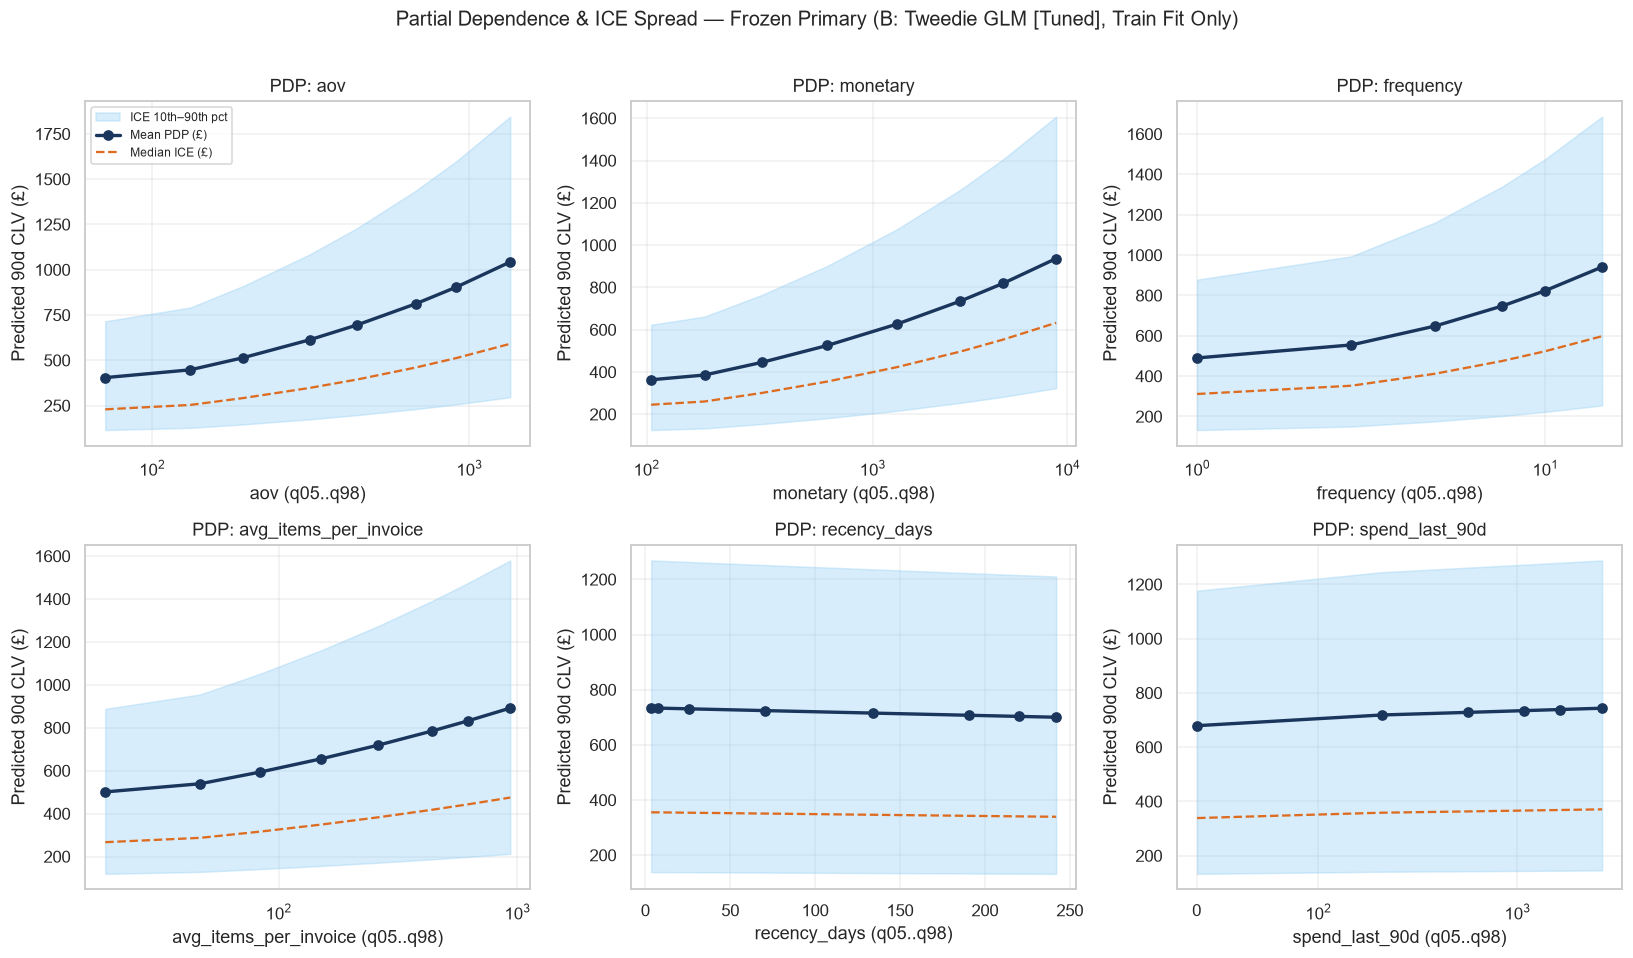

,x_q10,pdp_q10_gbp,x_q50,pdp_q50_gbp,x_q90,pdp_q90_gbp,x_q98,pdp_q98_gbp,delta_q90_minus_q10_gbp
feature,,,,,,,,,
aov,113.11,447.20,287.11,612.76,656.93,811.41,1375.10,1042.85,364.21
monetary,136.67,385.62,584.69,525.41,2825.71,735.43,8766.52,936.62,349.81
frequency,2.00,554.49,2.00,554.49,7.00,747.70,16.00,940.82,193.21
avg_items_per_invoice,47.00,539.15,151.12,655.56,437.02,784.25,932.54,891.57,245.10
recency_days,7.66,733.19,70.50,724.17,190.51,707.23,241.96,700.10,-25.96
spend_last_90d,152.30,718.49,152.30,718.49,1093.69,734.49,3232.98,743.47,16.01


In [10]:
import time
import matplotlib.pyplot as plt
from sklearn.base import clone

from src.clv import (
    CLV_FEATURE_GROUPS,
    compute_quantile_pdp,
    cv_permutation_importance,
)

# 0. Strict freeze verification — TEST_EVALUATION_COUNT MUST still be 0
assert TEST_EVALUATION_COUNT == 0, f"Expected 0 test touches in Step 8, got {TEST_EVALUATION_COUNT}!"

FROZEN_PRIMARY_NAME = "B: Tweedie GLM [Tuned]"
FROZEN_FALLBACK_NAME = "D2: Hurdle (Logit x Ridge) [Tuned]"
frozen_primary_est = clone(tuned_estimators[FROZEN_PRIMARY_NAME])
frozen_fallback_est = clone(tuned_estimators[FROZEN_FALLBACK_NAME])

print("=" * 72)
print("STEP 8.0: MODEL FREEZE LOCKED (TRAIN/CV INTERPRETATION ONLY)")
print("=" * 72)
print(f"Frozen Primary  : {FROZEN_PRIMARY_NAME} -> {frozen_primary_est.get_params()['model']}")
print(f"Frozen Fallback : {FROZEN_FALLBACK_NAME}")
print(f"TEST_EVALUATION_COUNT : {TEST_EVALUATION_COUNT}")

# 1. Validation-Fold Single-Feature Permutation Importance (Primary Model)
t0 = time.perf_counter()
single_perm_df = cv_permutation_importance(
    frozen_primary_est,
    X_train,
    y_train,
    cv=cv_splitter,
    strata=train_strata,
    feature_groups=None,
    n_repeats=10,
    random_state=RANDOM_STATE,
)
t_single = time.perf_counter() - t0

# Attach standardized log-link Tweedie coefficients from a train-only fit (for directional insight)
train_fitted_primary = clone(frozen_primary_est).fit(X_train, y_train)
prep_names = list(train_fitted_primary.named_steps["prep"].get_feature_names_out())
tweedie_coefs = train_fitted_primary.named_steps["model"].coef_
coef_series = pd.Series(tweedie_coefs, index=prep_names, name="log_link_beta")
num_coef_df = pd.DataFrame({
    "feature": [c for c in prep_names if not c.startswith("country_")],
    "std_beta": [float(coef_series[c]) for c in prep_names if not c.startswith("country_")],
})
num_coef_df["exp_beta_per_1sd"] = np.exp(num_coef_df["std_beta"])

single_view = single_perm_df.merge(num_coef_df, on="feature", how="left")
print("\n" + "=" * 72)
print(f"STEP 8.1: SINGLE-FEATURE CV PERMUTATION IMPORTANCE (15 folds x 10 repeats, {t_single:.2f}s)")
print("=" * 72)
disp_cols = [
    "feature", "gini_drop_mean", "gini_drop_std",
    "cap10_drop_mean", "spearman_drop_mean", "mae_increase_mean",
    "std_beta", "exp_beta_per_1sd",
]
display(single_view[disp_cols].round(4))

country_coef_df = pd.DataFrame({
    "country_dummy": [c for c in prep_names if c.startswith("country_")],
    "log_link_beta": [float(coef_series[c]) for c in prep_names if c.startswith("country_")],
})
country_coef_df["mult_vs_intercept"] = np.exp(country_coef_df["log_link_beta"])
print(f"\nTweedie Intercept (log scale): {train_fitted_primary.named_steps['model'].intercept_:.4f} "
      f"(base level £{np.exp(train_fitted_primary.named_steps['model'].intercept_):.2f})")
display(country_coef_df.round(4))

# 2. Validation-Fold Grouped Collinear Permutation Importance (Primary + Fallback check)
t0 = time.perf_counter()
group_perm_primary = cv_permutation_importance(
    frozen_primary_est,
    X_train,
    y_train,
    cv=cv_splitter,
    strata=train_strata,
    feature_groups=CLV_FEATURE_GROUPS,
    n_repeats=10,
    random_state=RANDOM_STATE,
)
group_perm_fallback = cv_permutation_importance(
    frozen_fallback_est,
    X_train,
    y_train,
    cv=cv_splitter,
    strata=train_strata,
    feature_groups=CLV_FEATURE_GROUPS,
    n_repeats=10,
    random_state=RANDOM_STATE,
)
t_group = time.perf_counter() - t0

# Quantify collinearity dilution: Joint group drop vs sum of individual feature drops inside group
single_gini_map = single_perm_df.set_index("feature")["gini_drop_mean"].to_dict()
sum_individual = [
    float(sum(max(single_gini_map.get(col, 0.0), 0.0) for col in CLV_FEATURE_GROUPS[grp]))
    for grp in group_perm_primary["feature"]
]
group_perm_primary["sum_single_gini_drop"] = sum_individual
group_perm_primary["dilution_ratio_joint_vs_sum"] = np.where(
    group_perm_primary["sum_single_gini_drop"] > 1e-6,
    group_perm_primary["gini_drop_mean"] / group_perm_primary["sum_single_gini_drop"],
    np.nan,
)

print("\n" + "=" * 72)
print(f"STEP 8.2: GROUPED COLLINEAR CV IMPORTANCE ({t_group:.2f}s for Primary + Fallback)")
print("=" * 72)
print("--- Primary: B: Tweedie GLM [Tuned] ---")
display(group_perm_primary[[
    "feature", "n_features", "gini_drop_mean", "gini_drop_std",
    "sum_single_gini_drop", "dilution_ratio_joint_vs_sum",
    "cap10_drop_mean", "spearman_drop_mean", "mae_increase_mean",
]].round(4))

print("--- Fallback Comparison: D2: Hurdle (Logit x Ridge) [Tuned] ---")
display(group_perm_fallback[[
    "feature", "n_features", "gini_drop_mean", "gini_drop_std",
    "cap10_drop_mean", "spearman_drop_mean", "mae_increase_mean",
]].round(4))

# Plot 1: Single Top 12 vs Grouped 6 Collinear Blocks
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))

top12 = single_perm_df.head(12).iloc[::-1]
axes[0].barh(
    top12["feature"],
    top12["gini_drop_mean"],
    xerr=top12["gini_drop_std"],
    color="#2b6cb0",
    alpha=0.88,
    capsize=3,
)
axes[0].axvline(0.0, color="#4a5568", linestyle="--", linewidth=1.0)
axes[0].set_title("Single-Feature Validation Permutation Importance\n(Top 12 — Diluted by Collinear Twins)")
axes[0].set_xlabel("Mean Validation Normalized Gini Drop (± fold std)")
axes[0].grid(axis="x", alpha=0.3)

grp_plot = group_perm_primary.iloc[::-1]
y_pos = np.arange(len(grp_plot))
axes[1].barh(
    y_pos + 0.18,
    grp_plot["gini_drop_mean"],
    xerr=grp_plot["gini_drop_std"],
    height=0.36,
    label="Joint Group Permutation Drop",
    color="#c53030",
    alpha=0.88,
    capsize=3,
)
axes[1].barh(
    y_pos - 0.18,
    grp_plot["sum_single_gini_drop"],
    height=0.36,
    label="Sum of Single-Feature Drops",
    color="#a0aec0",
    alpha=0.85,
)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([f"{f} ({n} cols)" for f, n in zip(grp_plot["feature"], grp_plot["n_features"])])
axes[1].axvline(0.0, color="#4a5568", linestyle="--", linewidth=1.0)
axes[1].set_title("Grouped Collinear Block Importance\n(Joint Permutation Exposes Shared Signal)")
axes[1].set_xlabel("Mean Validation Normalized Gini Drop")
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# 3. Quantile-Grid Partial Dependence (PDP + ICE Spread) on Train-Fitted Primary Model
top_ranked = list(single_perm_df["feature"].head(4))
intuition_pillars = ["monetary", "recency_days", "frequency", "spend_last_90d", "return_rate", "aov"]
pdp_features = []
for f in top_ranked + intuition_pillars:
    if f in X_train.columns and pd.api.types.is_numeric_dtype(X_train[f]) and f not in pdp_features:
        pdp_features.append(f)
pdp_features = pdp_features[:6]

print("\n" + "=" * 72)
print(f"STEP 8.3: PARTIAL DEPENDENCE (QUANTILE GRID q05..q99) ON TRAIN FIT ({len(pdp_features)} FEATURES)")
print("=" * 72)

pdp_quantiles = (0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.98)
pdp_summary_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15.0, 8.6))
axes_flat = axes.ravel()

for idx, feat in enumerate(pdp_features):
    pdp_df = compute_quantile_pdp(
        train_fitted_primary,
        X_train,
        feat,
        quantiles=pdp_quantiles,
    )
    q10_val = pdp_df.loc[pdp_df["quantile"] >= 0.10].iloc[0]
    q50_val = pdp_df.loc[pdp_df["quantile"] >= 0.50].iloc[0]
    q90_val = pdp_df.loc[pdp_df["quantile"] >= 0.90].iloc[0]
    q98_val = pdp_df.iloc[-1]
    pdp_summary_rows.append({
        "feature": feat,
        "x_q10": round(float(q10_val["grid_value"]), 2),
        "pdp_q10_gbp": round(float(q10_val["mean_pred"]), 2),
        "x_q50": round(float(q50_val["grid_value"]), 2),
        "pdp_q50_gbp": round(float(q50_val["mean_pred"]), 2),
        "x_q90": round(float(q90_val["grid_value"]), 2),
        "pdp_q90_gbp": round(float(q90_val["mean_pred"]), 2),
        "x_q98": round(float(q98_val["grid_value"]), 2),
        "pdp_q98_gbp": round(float(q98_val["mean_pred"]), 2),
        "delta_q90_minus_q10_gbp": round(float(q90_val["mean_pred"] - q10_val["mean_pred"]), 2),
    })

    ax = axes_flat[idx]
    ax.fill_between(
        pdp_df["grid_value"],
        pdp_df["p10_pred"],
        pdp_df["p90_pred"],
        color="#90cdf4",
        alpha=0.35,
        label="ICE 10th–90th pct",
    )
    ax.plot(
        pdp_df["grid_value"],
        pdp_df["mean_pred"],
        marker="o",
        linewidth=2.2,
        color="#1a365d",
        label="Mean PDP (£)",
    )
    ax.plot(
        pdp_df["grid_value"],
        pdp_df["median_pred"],
        linestyle="--",
        linewidth=1.5,
        color="#dd6b20",
        label="Median ICE (£)",
    )
    if X_train[feat].max() / max(float(pdp_df["grid_value"].quantile(0.25)), 1.0) > 25 and pdp_df["grid_value"].min() >= 0:
        ax.set_xscale("symlog", linthresh=max(1.0, float(q10_val["grid_value"])))
    ax.set_title(f"PDP: {feat}")
    ax.set_xlabel(f"{feat} (q05..q98)")
    ax.set_ylabel("Predicted 90d CLV (£)")
    ax.grid(alpha=0.3)
    if idx == 0:
        ax.legend(loc="upper left", fontsize=8, frameon=True)

plt.suptitle("Partial Dependence & ICE Spread — Frozen Primary (B: Tweedie GLM [Tuned], Train Fit Only)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

display(pd.DataFrame(pdp_summary_rows).set_index("feature"))

## Step 9: ONE-SHOT Test Evaluation (`test_df`, 2011-09-10 Cutoff)

### Leakage-Control Contract
- **Prior state:** `TEST_EVALUATION_COUNT == 0` (verified in Step 8 after freezing `B: Tweedie GLM [Tuned]`).
- **Action now:** Fit the frozen pipeline on the **full `train_df` (`3,228` rows)** alongside the Step 3 baselines (`Train Mean`, `Train Median`, `Run-Rate`), evaluate **once** on `test_df` (`3,224` rows), and increment `TEST_EVALUATION_COUNT` to **`1`**.
- **Post-Step 9 lock:** No hyperparameter changes, feature edits, or model swaps are allowed from this cell onward. Any requested modification would trigger a **test-contamination warning**.

### Uncertainty & Whale Audit Reporting
Because one customer (`ID 18102`, `£123,737.11`) is `4.79%` of total test revenue and Top-5 customers are `17.26%`, we report:
1. **Customer-resampled 95% bootstrap confidence intervals (`n_bootstrap = 1,000`)** for every Step 2 metric plus **paired bootstrap deltas (`Frozen Model - Run-Rate`)**.
2. **Temporal generalization check:** Train 5×3 CV (`2010-09-10`) vs. Holdout Test (`2011-09-10`).
3. **Whale sensitivity slices:** Full test (`n = 3,224`), Excluding Top-1 (`n = 3,223`), and Excluding Top-5 (`n = 3,219`).

STEP 9.0: ONE-SHOT HOLDOUT TEST EVALUATION EXECUTED
TEST_EVALUATION_COUNT : 1 (LOCKED — no further model edits allowed)
Train shape fit on    : (3228, 26) | y_train sum: £2,430,069.08
Test shape scored     : (3224, 26)  | y_test sum : £2,585,609.91

STEP 9.1: HOLDOUT TEST RESULTS WITH 95% BOOTSTRAP CIs (1,000 resamples, 81.00s)


,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse,rmse_excl_top1,rmse_excl_top5
model,,,,,,,,,,,,
B: Tweedie GLM [Tuned] (Frozen),"0.5289 [0.5036, 0.5566]","0.7751 [0.6880, 0.8361]","0.5612 [0.4817, 0.6346]","5.61x [4.82x, 6.35x]","0.6725 [0.6072, 0.7292]","3.36x [3.04x, 3.65x]","-13.45% [-23.47%, -1.44%]","600.1 [506.2, 705.8]","258.8 [251.5, 269.3]","3,107.6 [1,527.4, 4,397.2]","2,454.4 [1,217.3, 3,963.0]","1,241.5 [968.1, 2,229.2]"
Baseline (c): Run-Rate (== Freq*AOV*90/270),"0.5315 [0.5057, 0.5602]","0.7719 [0.6721, 0.8388]","0.5590 [0.4784, 0.6333]","5.59x [4.78x, 6.33x]","0.6773 [0.6160, 0.7353]","3.39x [3.08x, 3.68x]","-37.38% [-43.07%, -30.08%]","563.4 [475.3, 651.7]","192.8 [180.5, 202.5]","2,792.8 [1,546.3, 3,836.2]","2,325.3 [1,265.8, 3,510.8]","1,259.8 [1,008.4, 2,205.8]"
Baseline (a): Train Mean (£752.81),"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.1000 [0.1000, 0.1000]","1.00x [1.00x, 1.00x]","0.2000 [0.2000, 0.2000]","1.00x [1.00x, 1.00x]","-6.13% [-20.45%, +11.97%]","953.6 [830.2, 1,095.7]","752.8 [752.8, 752.8]","4,096.8 [2,267.3, 5,628.8]","3,478.0 [1,839.3, 5,196.2]","1,855.3 [1,415.7, 3,461.0]"
Baseline (b): Train Median (£222.08),"0.0000 [0.0000, 0.0000]","0.0000 [0.0000, 0.0000]","0.1000 [0.1000, 0.1000]","1.00x [1.00x, 1.00x]","0.2000 [0.2000, 0.2000]","1.00x [1.00x, 1.00x]","-72.31% [-76.53%, -66.97%]","784.1 [657.9, 925.4]","222.1 [222.1, 222.1]","4,137.4 [2,313.6, 5,672.1]","3,519.9 [1,889.4, 5,239.2]","1,905.3 [1,459.7, 3,503.7]"



Paired Bootstrap Difference: B: Tweedie GLM [Tuned] MINUS Baseline (c): Run-Rate (95% CI):


,point_estimate,run_rate_est,delta_vs_ref,delta_ci_low,delta_ci_high,ci_excludes_zero
metric,,,,,,
spearman,0.5289,0.5315,-0.0026,-0.0083,0.0034,False
normalized_gini,0.7751,0.7719,0.0032,-0.0052,0.0161,False
top_10_capture,0.5612,0.5590,0.0022,-0.0048,0.0096,False
lift_at_10,5.6124,5.5901,0.0223,-0.0481,0.0961,False
top_20_capture,0.6725,0.6773,-0.0047,-0.0151,0.0008,False
lift_at_20,3.3626,3.3863,-0.0237,-0.0757,0.0041,False
total_rev_error_pct,-13.4513,-37.3767,23.9254,18.6939,29.8848,True
mae,600.1093,563.3921,36.7171,16.2255,59.3825,True
medae,258.8068,192.8300,65.9768,56.4344,78.2073,True



STEP 9.2: TEMPORAL GENERALIZATION CHECK — TRAIN CV (2010) vs HOLDOUT TEST (2011)


,train_cv_mean,train_cv_std,test_2011_point,test_minus_cv,test_95_ci
metric,,,,,
spearman,0.5013,0.0237,0.5289,0.0276,"[0.5036, 0.5566]"
normalized_gini,0.7691,0.0366,0.7751,0.0059,"[0.6880, 0.8361]"
top_10_capture,0.5242,0.0540,0.5612,0.0370,"[0.4817, 0.6346]"
top_20_capture,0.6464,0.0442,0.6725,0.0261,"[0.6072, 0.7292]"
total_rev_error_pct,-2.4969,10.5074,-13.4513,-10.9544,"[-23.4739, -1.4372]"
mae,554.4344,40.1749,600.1093,45.6749,"[506.2233, 705.7892]"
medae,264.9840,10.3978,258.8068,-6.1772,"[251.4790, 269.3332]"
rmse,1629.5621,332.0750,3107.5739,1478.0118,"[1527.4481, 4397.2455]"
rmse_excl_top1,1370.2930,235.5709,2454.3633,1084.0703,"[1217.3138, 3963.0360]"



STEP 9.3: WHALE SENSITIVITY ON HOLDOUT TEST (ALL vs EXCL TOP-1 vs EXCL TOP-5)


n_customers  actual_sum_gbp  spearman  normalized_gini  top_10_capture  lift_at_10  top_20_capture  lift_at_20  total_rev_error_pct       mae     medae       rmse
model                  slice                                                                                                                                                                                  
B: Tweedie GLM [Tuned] All (n=3224)                3224      2585609.91    0.5289           0.7751          0.5612      5.6124          0.6725      3.3626             -13.4513  600.1093  258.8068  3107.5739
                       Excl Top-1 (n=3223)         3223      2461872.80    0.5284           0.7612          0.5394      5.3945          0.6565      3.2827              -9.7301  566.7071  258.7963  2454.3633
                       Excl Top-5 (n=3219)         3219      2139263.23    0.5278           0.7604          0.4964      4.9640          0.6306      3.1528              -0.9641  499.4033  258.2118  1241.4908
Baseline (c): Run-Rate All (n=3224)                3224      2585609.91    0.5315           0.7719          0.5590      5.5901          0.6773      3.3863             -37.3767  563.3921  192.8300  2792.8085
                       Excl Top-1 (n=3223)         3223      2461872.80    0.5311           0.7576          0.5369      5.3690          0.6617      3.3085             -35.6863  536.3051  192.6733  2325.2595
                       Excl Top-5 (n=3219)         3219      2139263.23    0.5307           0.7622          0.4928      4.9282          0.6361      3.1803             -31.1746  471.2227  192.1333  1259.8304


STEP 9.4: HOLDOUT TEST DECILE CALIBRATION (B: Tweedie [Tuned] vs Run-Rate)


,n,tweedie_pred_mean,tweedie_actual_mean,tweedie_pred_actual_ratio,tweedie_share_pct,run_rate_pred_mean,run_rate_actual_mean,run_rate_pred_actual_ratio
pred_decile,,,,,,,,
1,322,102.24,87.22,1.17,1.09,32.07,97.71,0.33
2,322,157.46,168.96,0.93,2.10,57.99,309.17,0.19
3,323,203.82,334.49,0.61,4.18,86.67,184.17,0.47
4,322,252.90,225.05,1.12,2.80,114.35,237.84,0.48
5,323,308.66,339.52,0.91,4.24,156.18,300.35,0.52
6,322,383.53,338.39,1.13,4.21,215.49,345.44,0.62
7,322,492.29,457.17,1.08,5.69,300.98,513.43,0.59
8,323,662.06,674.60,0.98,8.43,441.53,599.76,0.74
9,322,960.18,892.97,1.08,11.12,681.60,949.45,0.72


Test Decile Mean Abs Calibration Error — Tweedie: £145.69 vs Run-Rate: £299.53


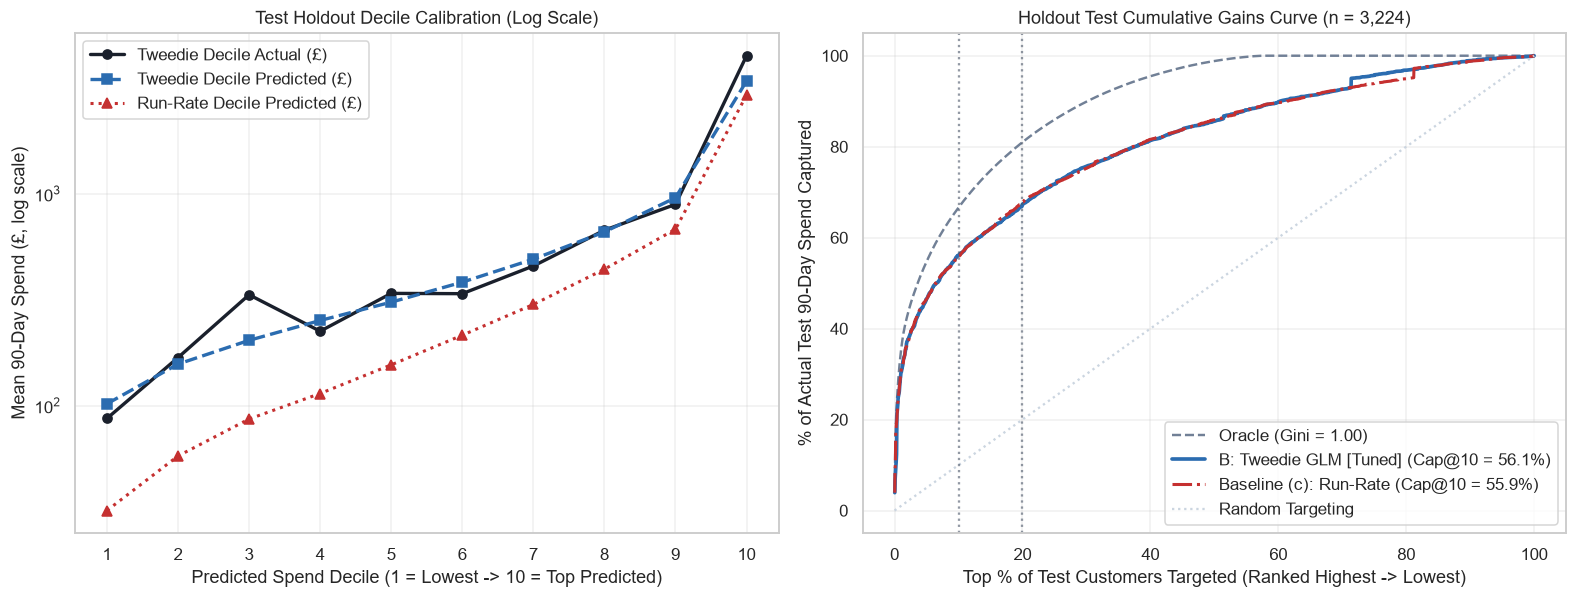


5 Sample Holdout Test Predictions (Random Seed = 42):


,target,pred_frozen_tweedie,pred_run_rate,pred_train_mean
Customer ID,,,,
12843,9.95,892.49,564.10,752.81
13210,0.00,334.61,117.83,752.81
13470,0.00,206.81,55.00,752.81
16148,0.00,88.82,25.44,752.81
14778,0.00,304.68,243.62,752.81


In [11]:
import time
import matplotlib.pyplot as plt
from sklearn.base import clone

from src.clv import (
    RuleBaselineRegressor,
    bootstrap_clv_metrics,
    calibration_by_predicted_decile,
    evaluate_clv_predictions,
    evaluate_whale_sensitivity_slices,
)

# 0. Strict One-Shot Gate
assert TEST_EVALUATION_COUNT == 0, (
    f"TEST CONTAMINATION VIOLATION: TEST_EVALUATION_COUNT was already {TEST_EVALUATION_COUNT}!"
)
TEST_EVALUATION_COUNT += 1

X_test = test_df[FEATURE_COLS]
y_test = test_df["target"]

print("=" * 72)
print("STEP 9.0: ONE-SHOT HOLDOUT TEST EVALUATION EXECUTED")
print("=" * 72)
print(f"TEST_EVALUATION_COUNT : {TEST_EVALUATION_COUNT} (LOCKED — no further model edits allowed)")
print(f"Train shape fit on    : {X_train.shape} | y_train sum: £{y_train.sum():,.2f}")
print(f"Test shape scored     : {X_test.shape}  | y_test sum : £{y_test.sum():,.2f}")

# 1. Refit ONLY the frozen model and all Step 3 baselines on full train_df
t0 = time.perf_counter()
final_frozen_model = clone(frozen_primary_est).fit(X_train, y_train)
base_mean = RuleBaselineRegressor("train_mean").fit(X_train, y_train)
base_median = RuleBaselineRegressor("train_median").fit(X_train, y_train)
base_run_rate = RuleBaselineRegressor("run_rate").fit(X_train, y_train)
base_freq_aov = RuleBaselineRegressor("freq_aov_run_rate").fit(X_train, y_train)

pred_test_frozen = np.asarray(final_frozen_model.predict(X_test), dtype=float)
pred_test_mean = np.asarray(base_mean.predict(X_test), dtype=float)
pred_test_median = np.asarray(base_median.predict(X_test), dtype=float)
pred_test_run_rate = np.asarray(base_run_rate.predict(X_test), dtype=float)
pred_test_freq_aov = np.asarray(base_freq_aov.predict(X_test), dtype=float)
assert np.allclose(pred_test_run_rate, pred_test_freq_aov, atol=1e-6), "Run-rate equivalence check failed!"

# Store frozen test predictions cleanly for diagnostic Steps 10-12
test_predictions_df = pd.DataFrame(
    {
        "target": y_test.to_numpy(dtype=float),
        "target_net": test_df["target_net"].to_numpy(dtype=float),
        "target_active": test_df["target_active"].to_numpy(dtype=int),
        "pred_frozen_tweedie": pred_test_frozen,
        "pred_run_rate": pred_test_run_rate,
        "pred_train_mean": pred_test_mean,
        "pred_train_median": pred_test_median,
    },
    index=test_df.index,
)

# 2. Bootstrap 95% CIs (n_bootstrap=1000 resampling customers) + Paired Delta vs Run-Rate
boot_frozen = bootstrap_clv_metrics(
    y_test, pred_test_frozen, ref_pred=pred_test_run_rate, n_bootstrap=1000, random_state=RANDOM_STATE
)
boot_run_rate = bootstrap_clv_metrics(
    y_test, pred_test_run_rate, ref_pred=None, n_bootstrap=1000, random_state=RANDOM_STATE
)
boot_mean = bootstrap_clv_metrics(
    y_test, pred_test_mean, ref_pred=None, n_bootstrap=1000, random_state=RANDOM_STATE
)
boot_median = bootstrap_clv_metrics(
    y_test, pred_test_median, ref_pred=None, n_bootstrap=1000, random_state=RANDOM_STATE
)
elapsed_s = time.perf_counter() - t0

def _fmt_ci(boot_df: pd.DataFrame, metric_name: str) -> str:
    row = boot_df.loc[metric_name]
    pt, lo, hi = row["point_estimate"], row["ci_low"], row["ci_high"]
    if metric_name == "total_rev_error_pct":
        return f"{pt:+.2f}% [{lo:+.2f}%, {hi:+.2f}%]"
    if metric_name in ("lift_at_10", "lift_at_20"):
        return f"{pt:.2f}x [{lo:.2f}x, {hi:.2f}x]"
    if metric_name in ("mae", "medae", "rmse", "rmse_excl_top1", "rmse_excl_top5"):
        return f"{pt:,.1f} [{lo:,.1f}, {hi:,.1f}]"
    return f"{pt:.4f} [{lo:.4f}, {hi:.4f}]"

models_boot = [
    ("B: Tweedie GLM [Tuned] (Frozen)", boot_frozen),
    ("Baseline (c): Run-Rate (== Freq*AOV*90/270)", boot_run_rate),
    ("Baseline (a): Train Mean (£752.81)", boot_mean),
    ("Baseline (b): Train Median (£222.08)", boot_median),
]
metric_order = [
    "spearman", "normalized_gini", "top_10_capture", "lift_at_10",
    "top_20_capture", "lift_at_20", "total_rev_error_pct",
    "mae", "medae", "rmse", "rmse_excl_top1", "rmse_excl_top5",
]

ci_table = pd.DataFrame(
    [{**{"model": m_name}, **{m: _fmt_ci(bdf, m) for m in metric_order}} for m_name, bdf in models_boot]
).set_index("model")

print("\n" + "=" * 72)
print(f"STEP 9.1: HOLDOUT TEST RESULTS WITH 95% BOOTSTRAP CIs (1,000 resamples, {elapsed_s:.2f}s)")
print("=" * 72)
display(ci_table)

print("\nPaired Bootstrap Difference: B: Tweedie GLM [Tuned] MINUS Baseline (c): Run-Rate (95% CI):")
paired_disp = boot_frozen[["point_estimate", "delta_vs_ref", "delta_ci_low", "delta_ci_high"]].copy()
paired_disp.insert(1, "run_rate_est", boot_run_rate["point_estimate"])
paired_disp["ci_excludes_zero"] = (
    (paired_disp["delta_ci_low"] > 0) | (paired_disp["delta_ci_high"] < 0)
)
display(paired_disp.round(4))

# 3. CV-to-Test Temporal Generalization Table (2010 CV vs 2011 Test)
cv_row_frozen = tuned_cv_df.loc[tuned_cv_df["model"] == FROZEN_PRIMARY_NAME].iloc[0]
gen_rows = []
for m in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top1", "rmse_excl_top5"]:
    gen_rows.append({
        "metric": m,
        "train_cv_mean": float(cv_row_frozen[f"{m}_mean"]),
        "train_cv_std": float(cv_row_frozen[f"{m}_std"]),
        "test_2011_point": float(boot_frozen.loc[m, "point_estimate"]),
        "test_minus_cv": float(boot_frozen.loc[m, "point_estimate"] - cv_row_frozen[f"{m}_mean"]),
        "test_95_ci": f"[{boot_frozen.loc[m, 'ci_low']:.4f}, {boot_frozen.loc[m, 'ci_high']:.4f}]",
    })
print("\n" + "=" * 72)
print("STEP 9.2: TEMPORAL GENERALIZATION CHECK — TRAIN CV (2010) vs HOLDOUT TEST (2011)")
print("=" * 72)
display(pd.DataFrame(gen_rows).set_index("metric").round(4))

# 4. Whale Sensitivity Report (All / Excl Top-1 / Excl Top-5) for Tweedie vs Run-Rate
sw_tweedie = evaluate_whale_sensitivity_slices(y_test, pred_test_frozen, exclude_top_ks=(0, 1, 5))
sw_tweedie.insert(0, "model", "B: Tweedie GLM [Tuned]")
sw_rr = evaluate_whale_sensitivity_slices(y_test, pred_test_run_rate, exclude_top_ks=(0, 1, 5))
sw_rr.insert(0, "model", "Baseline (c): Run-Rate")
whale_sens_df = pd.concat([sw_tweedie, sw_rr], ignore_index=True)

print("\n" + "=" * 72)
print("STEP 9.3: WHALE SENSITIVITY ON HOLDOUT TEST (ALL vs EXCL TOP-1 vs EXCL TOP-5)")
print("=" * 72)
display(whale_sens_df.set_index(["model", "slice"]).round(4))

# 5. Test Decile Calibration & Cumulative Gains Curve
cal_test_tweedie = calibration_by_predicted_decile(y_test, pred_test_frozen, n_bins=10)
cal_test_rr = calibration_by_predicted_decile(y_test, pred_test_run_rate, n_bins=10)

print("\n" + "=" * 72)
print("STEP 9.4: HOLDOUT TEST DECILE CALIBRATION (B: Tweedie [Tuned] vs Run-Rate)")
print("=" * 72)
cal_comp = pd.DataFrame({
    "n": cal_test_tweedie["n_customers"],
    "tweedie_pred_mean": cal_test_tweedie["mean_pred"],
    "tweedie_actual_mean": cal_test_tweedie["mean_actual"],
    "tweedie_pred_actual_ratio": cal_test_tweedie["pred_to_actual_ratio"],
    "tweedie_share_pct": cal_test_tweedie["actual_share_pct"],
    "run_rate_pred_mean": cal_test_rr["mean_pred"],
    "run_rate_actual_mean": cal_test_rr["mean_actual"],
    "run_rate_pred_actual_ratio": cal_test_rr["pred_to_actual_ratio"],
}).round(2)
display(cal_comp)
print(f"Test Decile Mean Abs Calibration Error — Tweedie: £{(cal_test_tweedie['mean_pred'] - cal_test_tweedie['mean_actual']).abs().mean():.2f} "
      f"vs Run-Rate: £{(cal_test_rr['mean_pred'] - cal_test_rr['mean_actual']).abs().mean():.2f}")

# 2-panel visualization: Left = Test Decile Mean Pred vs Actual; Right = Cumulative Gains Curve
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))

dec = cal_test_tweedie.index.to_numpy()
axes[0].plot(dec, cal_test_tweedie["mean_actual"], marker="o", linewidth=2.2, color="#1a202c", label="Tweedie Decile Actual (£)")
axes[0].plot(dec, cal_test_tweedie["mean_pred"], marker="s", linestyle="--", linewidth=2.2, color="#2b6cb0", label="Tweedie Decile Predicted (£)")
axes[0].plot(dec, cal_test_rr["mean_pred"], marker="^", linestyle=":", linewidth=2.0, color="#c53030", label="Run-Rate Decile Predicted (£)")
axes[0].set_yscale("log")
axes[0].set_xticks(dec)
axes[0].set_xlabel("Predicted Spend Decile (1 = Lowest -> 10 = Top Predicted)")
axes[0].set_ylabel("Mean 90-Day Spend (£, log scale)")
axes[0].set_title("Test Holdout Decile Calibration (Log Scale)")
axes[0].legend(loc="upper left", frameon=True)
axes[0].grid(alpha=0.3)

# Cumulative Gains on Test
tot_y = float(y_test.sum())
frac_cust = np.arange(1, len(y_test) + 1) / len(y_test) * 100.0
y_arr = y_test.to_numpy(dtype=float)
oracle_cum = np.cumsum(np.sort(y_arr)[::-1]) / tot_y * 100.0
tweedie_cum = np.cumsum(y_arr[np.argsort(-pred_test_frozen, kind="mergesort")]) / tot_y * 100.0
rr_cum = np.cumsum(y_arr[np.argsort(-pred_test_run_rate, kind="mergesort")]) / tot_y * 100.0

axes[1].plot(frac_cust, oracle_cum, linestyle="--", color="#718096", linewidth=1.6, label=f"Oracle (Gini = 1.00)")
axes[1].plot(frac_cust, tweedie_cum, color="#2b6cb0", linewidth=2.4, label=f"B: Tweedie GLM [Tuned] (Cap@10 = {boot_frozen.loc['top_10_capture', 'point_estimate']:.1%})")
axes[1].plot(frac_cust, rr_cum, color="#c53030", linestyle="-.", linewidth=2.0, label=f"Baseline (c): Run-Rate (Cap@10 = {boot_run_rate.loc['top_10_capture', 'point_estimate']:.1%})")
axes[1].plot([0, 100], [0, 100], color="#cbd5e0", linestyle=":", linewidth=1.5, label="Random Targeting")
axes[1].axvline(10, color="#4a5568", linestyle=":", alpha=0.6)
axes[1].axvline(20, color="#4a5568", linestyle=":", alpha=0.6)
axes[1].set_xlabel("Top % of Test Customers Targeted (Ranked Highest -> Lowest)")
axes[1].set_ylabel("% of Actual Test 90-Day Spend Captured")
axes[1].set_title("Holdout Test Cumulative Gains Curve (n = 3,224)")
axes[1].legend(loc="lower right", frameon=True)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n5 Sample Holdout Test Predictions (Random Seed = 42):")
display(test_predictions_df[["target", "pred_frozen_tweedie", "pred_run_rate", "pred_train_mean"]].sample(5, random_state=RANDOM_STATE).round(2))

## Step 10: Diagnostic Error Analysis on Test (`TEST_EVALUATION_COUNT = 1`, Read-Only)

### Strict Zero-Modification Contract
- `TEST_EVALUATION_COUNT == 1` stays **locked**: we do **not** retune, re-fit, add features, or alter predictions after observing these slices.
- Phase 4a segments (`data/processed/segmentation/segments_t_seg_2011-09-10.parquet`) are joined strictly **post-hoc** for cohort diagnostics.

### Six Diagnostic Slicing Dimensions
1. **Phase 4a Segments** (`VIP Champions`, `Loyal Regulars`, `Promising Recent Buyers`, `At-Risk Repeaters`, `Hibernating / Lost`).
2. **Whale vs. Non-Whale** evaluated **both ex-ante** (historical lookback `monetary` tiers — free of outcome bias) **and ex-post** (actual Top-5 & Top-1% test whales + recall in predicted Decile 10).
3. **Single-Invoice (`freq = 1`) vs. Repeat (`freq >= 2`) Buyers** (testing imputed `mean_interpurchase_days` cohort).
4. **UK Domestic vs. Export (Non-UK)**.
5. **Seen in Train (`2010 & 2011`) vs. New to Train (`2011 only`)**.
6. **Predicted-Decile Calibration (Deciles 1–10 Error Slice Table)** + forensic trace of **Step 9.4's Decile 3 dip** + Top-5 under/over-predictions and SSE concentration.

STEP 10.1: SLICE BY PHASE 4A SEGMENT (POST-HOC JOIN ON TEST)


,n_customers,actual_share_pct,zero_target_pct,actual_mean_gbp,pred_mean_gbp,total_rev_error_pct,mean_bias_pred_minus_true,mae,medae,rmse,spearman,normalized_gini,run_rate_rev_err_pct,run_rate_mae,run_rate_rmse
slice,,,,,,,,,,,,,,,
VIP Champions,473,60.16,8.67,3288.58,2446.74,-25.60,-841.84,1889.84,638.02,7567.88,0.63,0.87,-38.05,1850.90,6654.02
Loyal Regulars,1208,25.95,32.53,555.33,556.12,0.14,0.79,477.03,308.67,918.16,0.34,0.42,-31.76,453.30,979.83
Promising Recent Buyers,1024,10.85,55.86,273.84,281.99,2.98,8.15,326.71,203.30,1699.36,0.23,0.24,-52.02,281.85,1705.44
At-Risk Repeaters,357,2.71,63.03,196.08,266.81,36.07,70.73,294.70,219.36,419.67,0.02,0.19,-24.25,250.83,416.53
Hibernating / Lost,162,0.34,80.86,54.67,152.43,178.82,97.76,153.39,132.79,189.70,0.03,0.16,15.78,93.53,155.34



STEP 10.2: WHALE vs NON-WHALE (EX-ANTE LOOKBACK TIERS & EX-POST AUDIT)
--- Ex-Ante Historical Whales (Zero Outcome-Selection Bias) ---


,n_customers,actual_share_pct,zero_target_pct,actual_mean_gbp,pred_mean_gbp,total_rev_error_pct,mean_bias_pred_minus_true,mae,medae,rmse,spearman,normalized_gini,run_rate_rev_err_pct,run_rate_mae,run_rate_rmse
slice,,,,,,,,,,,,,,,
"Lookback Top-1% (>=£13,049)",33,30.72,3.03,24066.87,14578.81,-39.42,-9488.06,14589.12,6268.25,28019.44,0.51,0.57,-40.68,13829.68,24396.27
"Lookback Next 9% (£2,652-£13,049)",290,25.19,10.69,2245.87,2114.41,-5.85,-131.46,1299.75,884.74,2107.85,0.43,0.55,-27.00,1299.71,2267.02
Lookback Bottom 90% Core,2901,44.09,45.85,393.00,394.19,0.30,1.18,371.04,242.03,1165.07,0.42,0.46,-41.00,338.88,1176.47


--- Ex-Post Actual Test Whale Tiers ---


,n_customers,actual_share_pct,zero_target_pct,actual_mean_gbp,pred_mean_gbp,total_rev_error_pct,mean_bias_pred_minus_true,mae,medae,rmse,spearman,normalized_gini,run_rate_rev_err_pct,run_rate_mae,run_rate_rmse
slice,,,,,,,,,,,,,,,
Top-5 Actual Whales (n=5),5,17.26,0.00,89269.34,23834.73,-73.30,-65434.60,65434.60,52832.83,72350.22,0.20,0.26,-67.10,59902.06,63304.63
Rank 6-33 Actual Top-1% (n=28),28,18.05,0.00,16669.66,11025.46,-33.86,-5644.20,8866.69,7472.18,10798.89,0.41,0.40,-42.13,9490.72,10906.35
"Core Remaining 99% (n=3,191)",3191,64.69,42.68,524.13,567.20,8.22,43.06,425.98,256.62,729.08,0.52,0.69,-28.12,392.08,746.57


... (8 outputs left out)


SSE Concentration: Top 5 worst-error customers explain 84.1% of total Test SSE (Top 10 explain 90.0%).
Top 5 Largest Under-Predictions (Actual >> Predicted):


,country,segment,seen_in_train,recency_days,frequency,monetary,spend_last_90d,return_rate,target,pred_frozen_tweedie,residual_pred_minus_true,pred_decile
Customer ID,,,,,,,,,,,,
18102,United Kingdom,VIP Champions,True,7.50,23,107616.14,43321.12,0.00,123737.11,15481.90,-108255.21,10
17450,United Kingdom,VIP Champions,False,4.42,21,84272.70,30541.28,0.00,108089.25,14849.94,-93239.31,10
14096,United Kingdom,Promising Recent Buyers,False,0.36,3,203.89,203.89,0.00,53054.54,221.71,-52832.83,3
14646,Netherlands,VIP Champions,True,1.52,42,177729.62,62151.70,0.02,101408.40,52426.47,-48981.93,10
14911,EIRE,VIP Champions,True,2.41,100,70686.82,37694.15,0.19,60057.38,36193.64,-23863.74,10


Top 5 Largest Over-Predictions (Predicted >> Actual):


,country,segment,seen_in_train,recency_days,frequency,monetary,spend_last_90d,return_rate,target,pred_frozen_tweedie,residual_pred_minus_true,pred_decile
Customer ID,,,,,,,,,,,,
14156,EIRE,VIP Champions,True,2.33,40,97916.59,53538.44,0.07,18321.29,39859.73,21538.44,10
15749,United Kingdom,Loyal Regulars,False,144.44,3,44534.30,0.00,0.25,0.00,10255.51,10255.51,10
17949,United Kingdom,VIP Champions,True,2.40,31,46415.20,37097.20,0.11,10301.28,19887.34,9586.06,10
16422,United Kingdom,VIP Champions,True,8.47,38,27449.50,9824.85,0.19,5566.70,13548.46,7981.76,10
15039,United Kingdom,VIP Champions,True,0.53,37,17799.24,4408.31,0.12,1381.94,9027.90,7645.96,10


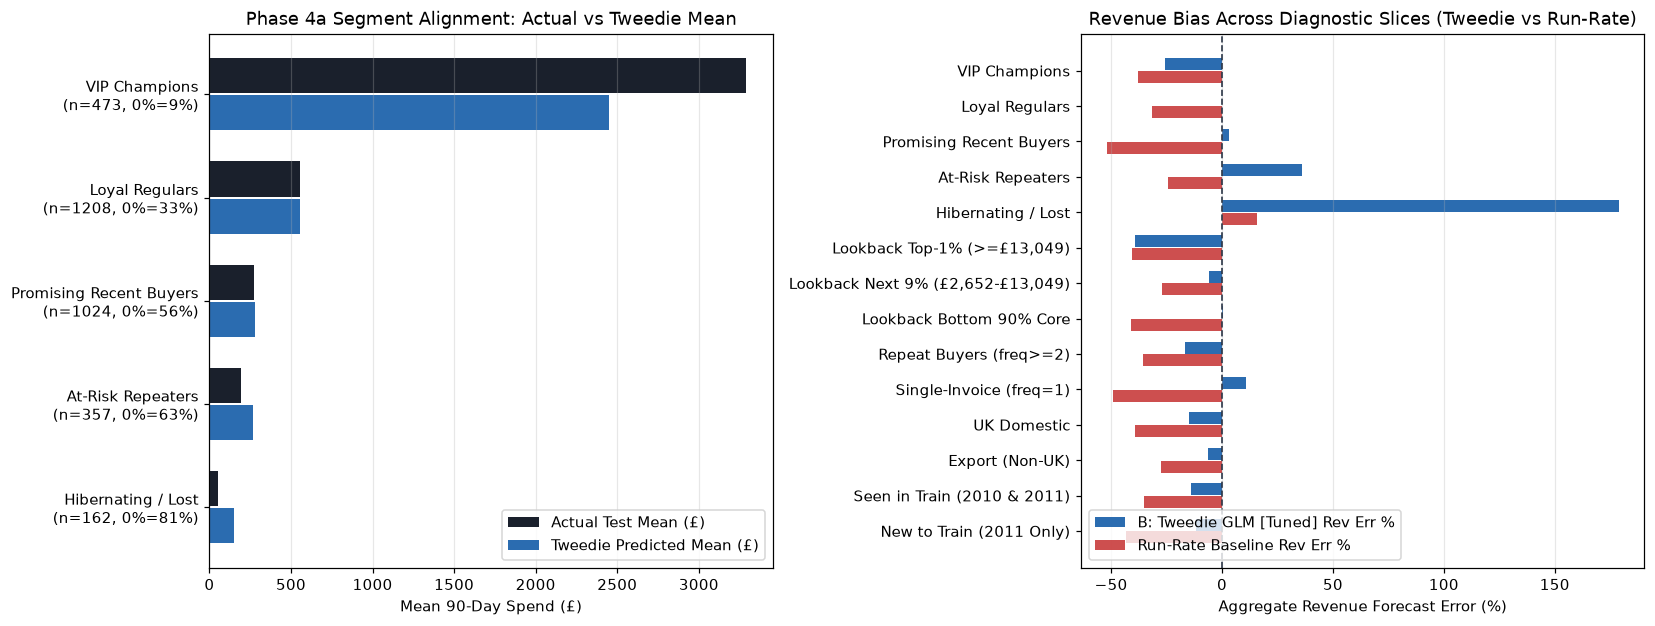

In [12]:
import matplotlib.pyplot as plt
from src.clv import compute_slice_error_table

assert TEST_EVALUATION_COUNT == 1, f"Expected locked TEST_EVALUATION_COUNT == 1, got {TEST_EVALUATION_COUNT}"

seg_path = PROJECT_ROOT / "data" / "processed" / "segmentation" / "segments_t_seg_2011-09-10.parquet"
seg_df = pd.read_parquet(seg_path)
assert test_df.index.isin(seg_df.index).all(), "Test IDs missing from segmentation parquet!"

diag_df = test_df.join(test_predictions_df[["pred_frozen_tweedie", "pred_run_rate"]], how="inner")
diag_df = diag_df.join(seg_df[["cluster", "segment"]], how="left")

# Derived cohort labels (post-hoc diagnostics only; never used as features)
diag_df["seen_in_train"] = diag_df.index.isin(train_df.index)
diag_df["history_cohort"] = np.where(
    diag_df["seen_in_train"],
    "Seen in Train (2010 & 2011)",
    "New to Train (2011 Only)",
)
diag_df["invoice_cohort"] = np.where(
    diag_df["is_single_invoice"] == 1,
    "Single-Invoice (freq=1)",
    "Repeat Buyers (freq>=2)",
)
diag_df["geo_cohort"] = np.where(diag_df["is_uk"] == 1, "UK Domestic", "Export (Non-UK)")

# Ex-ante whale tiers (defined strictly from lookback monetary BEFORE Q4 begins)
q90_mon = float(diag_df["monetary"].quantile(0.90))
q99_mon = float(diag_df["monetary"].quantile(0.99))
diag_df["whale_tier_exante"] = pd.Categorical(
    np.where(
        diag_df["monetary"] >= q99_mon,
        f"Lookback Top-1% (>=£{q99_mon:,.0f})",
        np.where(
            diag_df["monetary"] >= q90_mon,
            f"Lookback Next 9% (£{q90_mon:,.0f}-£{q99_mon:,.0f})",
            "Lookback Bottom 90% Core",
        ),
    ),
    categories=[
        f"Lookback Top-1% (>=£{q99_mon:,.0f})",
        f"Lookback Next 9% (£{q90_mon:,.0f}-£{q99_mon:,.0f})",
        "Lookback Bottom 90% Core",
    ],
    ordered=True,
)

# Ex-post actual outcome tiers
actual_rank = diag_df["target"].rank(method="first", ascending=False).astype(int)
diag_df["whale_tier_actual"] = pd.Categorical(
    np.where(
        actual_rank <= 5,
        "Top-5 Actual Whales (n=5)",
        np.where(actual_rank <= 33, "Rank 6-33 Actual Top-1% (n=28)", "Core Remaining 99% (n=3,191)"),
    ),
    categories=["Top-5 Actual Whales (n=5)", "Rank 6-33 Actual Top-1% (n=28)", "Core Remaining 99% (n=3,191)"],
    ordered=True,
)

# Predicted deciles matched identically to Step 9.4's calibration_by_predicted_decile bins
pct_rank = diag_df["pred_frozen_tweedie"].rank(method="average", pct=True)
diag_df["pred_decile"] = pd.cut(
    pct_rank, bins=np.linspace(0.0, 1.0, 11), labels=list(range(1, 11)), include_lowest=True
).astype(int)

diag_df["residual_pred_minus_true"] = diag_df["pred_frozen_tweedie"] - diag_df["target"]
diag_df["abs_error"] = diag_df["residual_pred_minus_true"].abs()
diag_df["sq_error"] = diag_df["residual_pred_minus_true"] ** 2

slice_cols_disp = [
    "n_customers", "actual_share_pct", "zero_target_pct",
    "actual_mean_gbp", "pred_mean_gbp", "total_rev_error_pct", "mean_bias_pred_minus_true",
    "mae", "medae", "rmse", "spearman", "normalized_gini",
    "run_rate_rev_err_pct", "run_rate_mae", "run_rate_rmse",
]

print("=" * 72)
print("STEP 10.1: SLICE BY PHASE 4A SEGMENT (POST-HOC JOIN ON TEST)")
print("=" * 72)
seg_tbl = compute_slice_error_table(diag_df, "segment")
display(seg_tbl[slice_cols_disp].round(2))

print("\n" + "=" * 72)
print("STEP 10.2: WHALE vs NON-WHALE (EX-ANTE LOOKBACK TIERS & EX-POST AUDIT)")
print("=" * 72)
exante_whale_tbl = compute_slice_error_table(diag_df, "whale_tier_exante", sort_by=None)
print("--- Ex-Ante Historical Whales (Zero Outcome-Selection Bias) ---")
display(exante_whale_tbl[slice_cols_disp].round(2))

expost_whale_tbl = compute_slice_error_table(diag_df, "whale_tier_actual", sort_by=None)
print("--- Ex-Post Actual Test Whale Tiers ---")
display(expost_whale_tbl[slice_cols_disp].round(2))

top1pct_actual_mask = actual_rank <= 33
caught_dec10 = int((top1pct_actual_mask & (diag_df["pred_decile"] == 10)).sum())
top5_actual_audit = diag_df.sort_values("target", ascending=False).head(5)
print(f"Whale Targeting Recall: {caught_dec10} / 33 ({caught_dec10/33*100:.1f}%) of Actual Top-1% test whales sit in Predicted Decile 10.")
print("Top-5 Actual Test Whales Audit:")
display(top5_actual_audit[[
    "country", "segment", "seen_in_train", "frequency", "monetary",
    "target", "pred_frozen_tweedie", "pred_run_rate", "pred_decile",
]].round(2))

print("\n" + "=" * 72)
print("STEP 10.3–10.5: INVOICE CADENCE, GEOGRAPHY & TRAIN-SEEN COHORTS")
print("=" * 72)
inv_tbl = compute_slice_error_table(diag_df, "invoice_cohort")
geo_tbl = compute_slice_error_table(diag_df, "geo_cohort")
hist_tbl = compute_slice_error_table(diag_df, "history_cohort")
cohort_stack = pd.concat({"Cadence": inv_tbl, "Geography": geo_tbl, "History": hist_tbl})
display(cohort_stack[slice_cols_disp].round(2))

print("\n" + "=" * 72)
print("STEP 10.6: PREDICTED-DECILE ERROR SLICE (1 -> 10) & DECILE 3 FORENSICS")
print("=" * 72)
decile_tbl = compute_slice_error_table(diag_df, "pred_decile", sort_by=None)
display(decile_tbl[[
    "n_customers", "actual_share_pct", "zero_target_pct",
    "actual_mean_gbp", "pred_mean_gbp", "total_rev_error_pct",
    "mae", "medae", "rmse", "spearman", "run_rate_mae", "run_rate_rmse",
]].round(2))

dec3 = diag_df[diag_df["pred_decile"] == 3]
print(
    f"Decile 3 Anomaly Breakdown (n={len(dec3)}): "
    f"zero_pct={(dec3['target'] == 0).mean()*100:.1f}%, "
    f"median_actual=£{dec3['target'].median():.2f}, "
    f"mean_actual=£{dec3['target'].mean():.2f}, "
    f"mean_pred=£{dec3['pred_frozen_tweedie'].mean():.2f}, "
    f"top-3 buyers sum=£{dec3['target'].nlargest(3).sum():,.2f} "
    f"({dec3['target'].nlargest(3).sum() / dec3['target'].sum() * 100:.1f}% of Decile 3 spend!)"
)
print("Top 5 Surprise Spenders Inside Decile 3:")
display(dec3.sort_values("target", ascending=False).head(5)[[
    "country", "segment", "seen_in_train", "recency_days", "frequency",
    "monetary", "spend_last_90d", "target", "pred_frozen_tweedie",
]].round(2))

total_sse = float(diag_df["sq_error"].sum())
top5_sq_share = float(diag_df["sq_error"].nlargest(5).sum() / total_sse * 100.0)
top10_sq_share = float(diag_df["sq_error"].nlargest(10).sum() / total_sse * 100.0)
print(f"\nSSE Concentration: Top 5 worst-error customers explain {top5_sq_share:.1f}% of total Test SSE (Top 10 explain {top10_sq_share:.1f}%).")

detail_cols = [
    "country", "segment", "seen_in_train", "recency_days", "frequency",
    "monetary", "spend_last_90d", "return_rate", "target", "pred_frozen_tweedie",
    "residual_pred_minus_true", "pred_decile",
]
print("Top 5 Largest Under-Predictions (Actual >> Predicted):")
display(diag_df.sort_values("residual_pred_minus_true", ascending=True).head(5)[detail_cols].round(2))

print("Top 5 Largest Over-Predictions (Predicted >> Actual):")
display(diag_df.sort_values("residual_pred_minus_true", ascending=False).head(5)[detail_cols].round(2))

# 2-Panel Error-Analysis Visualization
fig, axes = plt.subplots(1, 2, figsize=(15.2, 5.8))

seg_plot = seg_tbl.iloc[::-1]
y_idx = np.arange(len(seg_plot))
axes[0].barh(y_idx + 0.18, seg_plot["actual_mean_gbp"], height=0.34, label="Actual Test Mean (£)", color="#1a202c")
axes[0].barh(y_idx - 0.18, seg_plot["pred_mean_gbp"], height=0.34, label="Tweedie Predicted Mean (£)", color="#2b6cb0")
axes[0].set_yticks(y_idx)
axes[0].set_yticklabels([f"{s}\n(n={int(n)}, 0%={z:.0f}%)" for s, n, z in zip(seg_plot.index, seg_plot["n_customers"], seg_plot["zero_target_pct"])])
axes[0].set_xlabel("Mean 90-Day Spend (£)")
axes[0].set_title("Phase 4a Segment Alignment: Actual vs Tweedie Mean")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(axis="x", alpha=0.3)

bias_rows = []
for name, row in pd.concat([seg_tbl, exante_whale_tbl, inv_tbl, geo_tbl, hist_tbl]).iterrows():
    bias_rows.append((name, float(row["total_rev_error_pct"]), float(row["run_rate_rev_err_pct"])))
bias_df = pd.DataFrame(bias_rows, columns=["slice", "tweedie_err", "rr_err"]).iloc[::-1]
yb = np.arange(len(bias_df))
axes[1].barh(yb + 0.18, bias_df["tweedie_err"], height=0.34, label="B: Tweedie GLM [Tuned] Rev Err %", color="#2b6cb0")
axes[1].barh(yb - 0.18, bias_df["rr_err"], height=0.34, label="Run-Rate Baseline Rev Err %", color="#c53030", alpha=0.85)
axes[1].axvline(0.0, color="#2d3748", linestyle="--", linewidth=1.1)
axes[1].set_yticks(yb)
axes[1].set_yticklabels(bias_df["slice"])
axes[1].set_xlabel("Aggregate Revenue Forecast Error (%)")
axes[1].set_title("Revenue Bias Across Diagnostic Slices (Tweedie vs Run-Rate)")
axes[1].legend(loc="lower left", frameon=True)
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Step 11: Business Translation & Scope Coverage (`TEST_EVALUATION_COUNT = 1` Locked)

### Three Questions Executive Stakeholders Ask
1. **Campaign Targeting Simulation (`Top 10%, 20%, 30%`):** If CRM contacts only the top `k%` highest-scoring customers by predicted CLV, how much real Q4 revenue is captured — in **pounds (£), customer headcount, incremental lift over random, and % of the theoretical Oracle ceiling**?
2. **Registered-Customer Coverage Ratio:** Our model scores the `3,224` customers active in the `[2010-12-14, 2011-09-10)` lookback window. Across **all** registered customers active in `[2011-09-10, 2011-12-09)`, what share of actual Q4 revenue belongs to those `3,224` scored accounts vs. **Cold-Start (new)**, **Dormant-Reactivated**, and **Returns-Only** out-of-scope cohorts?
3. **Returns Sensitivity (`target_net` vs. gross `target`):** If we evaluate the exact same frozen predictions against net-of-returns revenue (`target_net`), do our ranking, calibration, or model-vs-baseline conclusions change?

STEP 11.1: MARKETING TARGETING SIMULATION ON HOLDOUT TEST (n = 3,224, £2,585,609.91)


n_targeted_approx  actual_captured_gbp  capture_share_pct  lift_vs_random  incremental_vs_random_gbp  pct_of_oracle_ceiling  avg_actual_spend_targeted_gbp  active_buyer_hit_rate_pct
top_pct model                                                                                                                                                                                                            
10      B: Tweedie GLM [Tuned]                    322           1451151.85              56.12            5.61                 1192590.86                  84.27                        4501.09                      92.55
        Baseline (c): Run-Rate                    322           1445379.25              55.90            5.59                 1186818.26                  83.93                        4483.19                      90.06
        Random / Train Mean                       322            258560.99              10.00            1.00                       0.00                  15.01                         801.99                      57.75
        Oracle (Perfect Foresight)                322           1722079.95              66.60            6.66                 1463518.96                 100.00                        5341.44                     100.00
20      B: Tweedie GLM [Tuned]                    645           1738882.53              67.25            3.36                 1221760.55                  83.04                        2696.78                      86.67
        Baseline (c): Run-Rate                    645           1751137.05              67.73            3.39                 1234015.07                  83.62                        2715.78                      86.82
        Random / Train Mean                       645            517121.98              20.00            1.00                       0.00                  24.69                         801.99                      57.75
        Oracle (Perfect Foresight)                645           2094132.50              80.99            4.05                 1577010.52                 100.00                        3247.72                     100.00
30      B: Tweedie GLM [Tuned]                    967           1955925.91              75.65            2.52                 1180242.93                  84.15                        2022.26                      81.49
        Baseline (c): Run-Rate                    967           1944953.23              75.22            2.51                 1169270.26                  83.67                        2010.91                      81.70
        Random / Train Mean                       967            775682.97              30.00            1.00                       0.00                  33.37                         801.99                      57.75
        Oracle (Perfect Foresight)                967           2324443.10              89.90            3.00                 1548760.12                 100.00                        2403.27                     100.00


Plain-Business Translation:
- Top 10% (~322 customers): Tweedie captures £1,451,152 (56.12%, 5.61x random, +£1,192,591 above random £258,561, 84.3% of Oracle £1,722,080); active buyer hit rate = 92.5% | Run-Rate captures £1,445,379 (55.90%).
- Top 20% (~645 customers): Tweedie captures £1,738,883 (67.25%, 3.36x random, +£1,221,761 above random £517,122, 83.0% of Oracle £2,094,132); active buyer hit rate = 86.7% | Run-Rate captures £1,751,137 (67.73%).
- Top 30% (~967 customers): Tweedie captures £1,955,926 (75.65%, 2.52x random, +£1,180,243 above random £775,683, 84.1% of Oracle £2,324,443); active buyer hit rate = 81.5% | Run-Rate captures £1,944,953 (75.22%).

STEP 11.2: REGISTERED-CUSTOMER COVERAGE RATIO IN [2011-09-10, 2011-12-09)


,cohort_pool_customers,target_active_customers,gross_spend_gbp,returns_gbp,net_spend_gbp,gross_share_pct,net_share_pct
cohort,,,,,,,
"Eligible (Model-Scored, Lookback Active)",3224,1884,2585609.91,-71359.06,2514250.85,80.96,80.88
Out-of-Scope: Cold-Start (New Buyers),594,594,385089.91,-7166.34,377923.57,12.06,12.16
Out-of-Scope: Dormant-Reactivated,426,426,222872.55,-5789.55,217083.00,6.98,6.98
Out-of-Scope: Returns-Only,6,6,0.00,-624.59,-624.59,0.00,-0.02


Total Registered Q4 Active Customers: 2,910 (plus 1,340 scored eligible customers who had £0 Q4 activity)
Total Registered Gross Q4 Spend    : £3,193,572.37 (Net after returns: £3,108,632.83)
Model-Scored Eligible Coverage     : 80.96% gross (£2,585,609.91) | 80.88% net

STEP 11.3: TARGET_NET SENSITIVITY (Net Sum = £2,514,250.85, Returns Gap = £71,359.06, 28 Net<0 Rows)


,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,total_rev_error_pct,mae,medae,rmse,rmse_excl_top5
model,,,,,,,,,,
B: Tweedie GLM [Tuned] (Frozen),0.5166,0.7721,0.5601,5.6014,0.6706,-10.9949,593.4678,257.2780,3047.2544,1208.5235
Baseline (c): Run-Rate,0.5189,0.7686,0.5578,5.5780,0.6757,-35.5994,551.4875,192.5900,2720.2070,1203.4389
Train Net Mean (£732.93),0.0000,0.0000,0.1000,1.0000,0.2000,-6.0171,928.1544,732.9299,4011.0388,1761.5854
Train Net Median (£214.19),0.0000,0.0000,0.1000,1.0000,0.2000,-72.5353,764.2612,214.1850,4050.4582,1811.1724



Gross vs Net Metric Sensitivity for B: Tweedie GLM [Tuned] (with 95% CIs on target_net):


,gross_target,net_target,delta_net_minus_gross,net_95_ci,paired_delta_vs_rr_on_net
metric,,,,,
spearman,0.5289,0.5166,-0.0123,"[0.4901, 0.5447]","-0.0022 [-0.0078, +0.0038]"
normalized_gini,0.7751,0.7721,-0.0030,"[0.6828, 0.8345]","+0.0035 [-0.0051, +0.0166]"
top_10_capture,0.5612,0.5601,-0.0011,"[0.4801, 0.6341]","+0.0023 [-0.0048, +0.0098]"
top_20_capture,0.6725,0.6706,-0.0019,"[0.6066, 0.7278]","-0.0051 [-0.0135, +0.0008]"
total_rev_error_pct,-13.4513,-10.9949,2.4564,"[-21.5155, 1.5537]","+24.6045 [+19.1326, +30.8692]"
mae,600.1093,593.4678,-6.6415,"[502.0576, 698.1252]","+41.9803 [+21.8273, +63.4638]"
medae,258.8068,257.2780,-1.5288,"[250.3208, 267.6661]","+64.6880 [+55.0682, +77.5544]"
rmse,3107.5739,3047.2544,-60.3195,"[1505.2818, 4334.9059]","+327.0474 [-76.6420, +637.3410]"
rmse_excl_top5,1241.4908,1208.5235,-32.9672,"[934.1443, 2198.2933]","+5.0846 [-143.0261, +119.5143]"


Whale Sensitivity on target_net (Tweedie):


,n_customers,actual_sum_gbp,spearman,normalized_gini,top_10_capture,lift_at_10,top_20_capture,lift_at_20,total_rev_error_pct,mae,medae,rmse
slice,,,,,,,,,,,,
All (n=3224),3224,2514250.85,0.5166,0.7721,0.5601,5.6014,0.6706,3.3529,-10.9949,593.4678,257.2780,3047.2544
Excl Top-1 (n=3223),3223,2390513.74,0.5162,0.7577,0.5376,5.3764,0.6540,3.2701,-7.0355,560.0636,257.1934,2377.5046
Excl Top-5 (n=3219),3219,2074059.75,0.5155,0.7570,0.4943,4.9430,0.6279,3.1393,2.1493,494.6638,257.0462,1208.5235


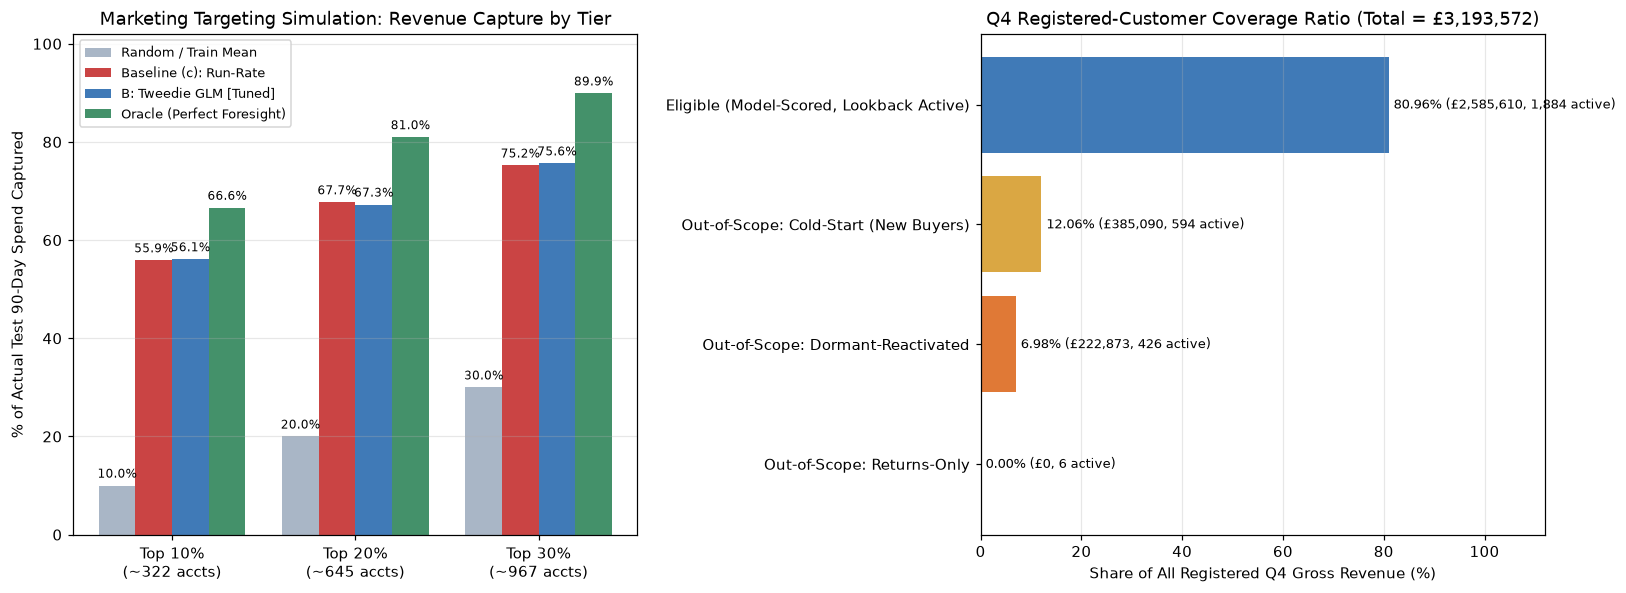


5 Sample Customers with Largest Target-Window Return Offsets (gross - net):


,target,target_net,target_active,pred_frozen_tweedie,pred_run_rate,pred_train_mean,pred_train_median,returns_offset_gbp
Customer ID,,,,,,,,
16029,26720.70,15178.14,1,20811.71,13905.29,752.81,222.08,11542.56
14607,14526.50,9298.10,1,330.20,165.00,752.81,222.08,5228.40
17450,108089.25,103273.99,1,14849.94,28090.90,752.81,222.08,4815.26
15482,8911.46,4425.22,1,772.03,642.77,752.81,222.08,4486.24
15769,14389.00,10139.00,1,13410.46,13923.97,752.81,222.08,4250.00


In [13]:
import matplotlib.pyplot as plt
from src.clv import (
    RuleBaselineRegressor,
    bootstrap_clv_metrics,
    compute_coverage_ratio_breakdown,
    compute_targeting_simulation,
    evaluate_clv_predictions,
    evaluate_whale_sensitivity_slices,
)

assert TEST_EVALUATION_COUNT == 1, f"Expected locked TEST_EVALUATION_COUNT == 1, got {TEST_EVALUATION_COUNT}"

y_test_gross = test_predictions_df["target"]
y_test_net = test_predictions_df["target_net"]
pred_tweedie = test_predictions_df["pred_frozen_tweedie"]
pred_run_rate = test_predictions_df["pred_run_rate"]
pred_mean_gross = test_predictions_df["pred_train_mean"]

# 1. Targeting Simulation (Top 10%, 20%, 30%)
sim_df = compute_targeting_simulation(
    y_test_gross,
    {
        "B: Tweedie GLM [Tuned]": pred_tweedie,
        "Baseline (c): Run-Rate": pred_run_rate,
        "Random / Train Mean": pred_mean_gross,
        "Oracle (Perfect Foresight)": y_test_gross,
    },
    top_fracs=(0.10, 0.20, 0.30),
)

print("=" * 72)
print("STEP 11.1: MARKETING TARGETING SIMULATION ON HOLDOUT TEST (n = 3,224, £2,585,609.91)")
print("=" * 72)
display(sim_df.set_index(["top_pct", "model"]).round(2))

print("\nPlain-Business Translation:")
for pct in (10, 20, 30):
    tw = sim_df[(sim_df["top_pct"] == pct) & (sim_df["model"] == "B: Tweedie GLM [Tuned]")].iloc[0]
    rr = sim_df[(sim_df["top_pct"] == pct) & (sim_df["model"] == "Baseline (c): Run-Rate")].iloc[0]
    rd = sim_df[(sim_df["top_pct"] == pct) & (sim_df["model"] == "Random / Train Mean")].iloc[0]
    orc = sim_df[(sim_df["top_pct"] == pct) & (sim_df["model"] == "Oracle (Perfect Foresight)")].iloc[0]
    print(
        f"- Top {pct}% (~{int(tw['n_targeted_approx']):,} customers): "
        f"Tweedie captures £{tw['actual_captured_gbp']:,.0f} ({tw['capture_share_pct']:.2f}%, {tw['lift_vs_random']:.2f}x random, "
        f"+£{tw['incremental_vs_random_gbp']:,.0f} above random £{rd['actual_captured_gbp']:,.0f}, "
        f"{tw['pct_of_oracle_ceiling']:.1f}% of Oracle £{orc['actual_captured_gbp']:,.0f}); "
        f"active buyer hit rate = {tw['active_buyer_hit_rate_pct']:.1f}% | "
        f"Run-Rate captures £{rr['actual_captured_gbp']:,.0f} ({rr['capture_share_pct']:.2f}%)."
    )

# 2. Coverage Ratio Across ALL Registered Customers in Target Window [2011-09-10, 2011-12-09)
sales_clean_path = PROJECT_ROOT / "data" / "processed" / "sales_clean.parquet"
returns_clean_path = PROJECT_ROOT / "data" / "processed" / "returns_clean.parquet"
sales_clean = pd.read_parquet(sales_clean_path, columns=["Customer ID", "InvoiceDate", "TotalPrice"])
returns_clean = pd.read_parquet(returns_clean_path, columns=["Customer ID", "InvoiceDate", "TotalPrice"])

cov_df = compute_coverage_ratio_breakdown(
    sales_clean,
    returns_clean,
    eligible_ids=test_df.index,
    cutoff="2011-09-10",
    horizon_days=90,
)
assert np.isclose(
    cov_df.loc["Eligible (Model-Scored, Lookback Active)", "gross_spend_gbp"],
    float(y_test_gross.sum()),
    atol=1e-2,
), "Coverage eligible gross sum must match test target sum!"

tot_reg_gross = float(cov_df["gross_spend_gbp"].sum())
tot_reg_net = float(cov_df["net_spend_gbp"].sum())
tot_reg_active = int(cov_df["target_active_customers"].sum())
elig_cov_pct = float(cov_df.loc["Eligible (Model-Scored, Lookback Active)", "gross_share_pct"])

print("\n" + "=" * 72)
print("STEP 11.2: REGISTERED-CUSTOMER COVERAGE RATIO IN [2011-09-10, 2011-12-09)")
print("=" * 72)
display(cov_df.round(2))
print(
    f"Total Registered Q4 Active Customers: {tot_reg_active:,} (plus {len(test_df) - int(cov_df.loc['Eligible (Model-Scored, Lookback Active)', 'target_active_customers']):,} "
    f"scored eligible customers who had £0 Q4 activity)\n"
    f"Total Registered Gross Q4 Spend    : £{tot_reg_gross:,.2f} (Net after returns: £{tot_reg_net:,.2f})\n"
    f"Model-Scored Eligible Coverage     : {elig_cov_pct:.2f}% gross (£{float(y_test_gross.sum()):,.2f}) | "
    f"{float(cov_df.loc['Eligible (Model-Scored, Lookback Active)', 'net_share_pct']):.2f}% net"
)

# 3. Target-Net Sensitivity Check (Frozen Model & Baselines Evaluated on target_net)
boot_tweedie_net = bootstrap_clv_metrics(
    y_test_net, pred_tweedie, ref_pred=pred_run_rate, n_bootstrap=1000, random_state=RANDOM_STATE
)
boot_rr_net = bootstrap_clv_metrics(
    y_test_net, pred_run_rate, ref_pred=None, n_bootstrap=1000, random_state=RANDOM_STATE
)
train_net_mean = RuleBaselineRegressor("train_mean").fit(X_train, train_df["target_net"]).predict(X_test)
train_net_median = RuleBaselineRegressor("train_median").fit(X_train, train_df["target_net"]).predict(X_test)

net_comp_rows = []
for name, preds in [
    ("B: Tweedie GLM [Tuned] (Frozen)", pred_tweedie),
    ("Baseline (c): Run-Rate", pred_run_rate),
    (f"Train Net Mean (£{train_df['target_net'].mean():.2f})", train_net_mean),
    (f"Train Net Median (£{train_df['target_net'].median():.2f})", train_net_median),
]:
    m_net = evaluate_clv_predictions(y_test_net, preds)
    m_net["model"] = name
    net_comp_rows.append(m_net)
net_comp_df = pd.DataFrame(net_comp_rows).set_index("model")

print("\n" + "=" * 72)
print(f"STEP 11.3: TARGET_NET SENSITIVITY (Net Sum = £{y_test_net.sum():,.2f}, Returns Gap = £{(y_test_gross - y_test_net).sum():,.2f}, {(y_test_net < 0).sum()} Net<0 Rows)")
print("=" * 72)
display(net_comp_df[[
    "spearman", "normalized_gini", "top_10_capture", "lift_at_10",
    "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5",
]].round(4))

gross_eval = evaluate_clv_predictions(y_test_gross, pred_tweedie)
net_vs_gross = pd.DataFrame({
    "metric": ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"],
    "gross_target": [gross_eval[k] for k in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"]],
    "net_target": [float(boot_tweedie_net.loc[k, "point_estimate"]) for k in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"]],
    "delta_net_minus_gross": [float(boot_tweedie_net.loc[k, "point_estimate"] - gross_eval[k]) for k in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"]],
    "net_95_ci": [f"[{boot_tweedie_net.loc[k, 'ci_low']:.4f}, {boot_tweedie_net.loc[k, 'ci_high']:.4f}]" for k in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"]],
    "paired_delta_vs_rr_on_net": [f"{boot_tweedie_net.loc[k, 'delta_vs_ref']:+.4f} [{boot_tweedie_net.loc[k, 'delta_ci_low']:+.4f}, {boot_tweedie_net.loc[k, 'delta_ci_high']:+.4f}]" for k in ["spearman", "normalized_gini", "top_10_capture", "top_20_capture", "total_rev_error_pct", "mae", "medae", "rmse", "rmse_excl_top5"]],
}).set_index("metric")

print("\nGross vs Net Metric Sensitivity for B: Tweedie GLM [Tuned] (with 95% CIs on target_net):")
display(net_vs_gross.round(4))

net_whale_df = evaluate_whale_sensitivity_slices(y_test_net, pred_tweedie, exclude_top_ks=(0, 1, 5))
print("Whale Sensitivity on target_net (Tweedie):")
display(net_whale_df.set_index("slice").round(4))

# 2-Panel Business Translation Figure
fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.5))

tiers = [10, 20, 30]
x = np.arange(len(tiers))
w = 0.20
bar_specs = [
    ("Random / Train Mean", "#a0aec0"),
    ("Baseline (c): Run-Rate", "#c53030"),
    ("B: Tweedie GLM [Tuned]", "#2b6cb0"),
    ("Oracle (Perfect Foresight)", "#2f855a"),
]
for j, (m_label, col) in enumerate(bar_specs):
    vals = [
        float(sim_df[(sim_df["top_pct"] == p) & (sim_df["model"] == m_label)]["capture_share_pct"].iloc[0])
        for p in tiers
    ]
    bars = axes[0].bar(x + (j - 1.5) * w, vals, width=w, label=m_label, color=col, alpha=0.90)
    for b in bars:
        h = b.get_height()
        axes[0].text(b.get_x() + b.get_width() / 2.0, h + 1.0, f"{h:.1f}%", ha="center", va="bottom", fontsize=8)

axes[0].set_xticks(x)
axes[0].set_xticklabels([f"Top {p}%\n(~{int(round(p / 100 * len(test_df))):,} accts)" for p in tiers])
axes[0].set_ylabel("% of Actual Test 90-Day Spend Captured")
axes[0].set_ylim(0, 102)
axes[0].set_title("Marketing Targeting Simulation: Revenue Capture by Tier")
axes[0].legend(loc="upper left", fontsize=8.5, frameon=True)
axes[0].grid(axis="y", alpha=0.3)

cov_plot = cov_df.iloc[::-1]
y_cov = np.arange(len(cov_plot))
colors_cov = ["#718096", "#dd6b20", "#d69e2e", "#2b6cb0"]
bars_c = axes[1].barh(y_cov, cov_plot["gross_share_pct"], color=colors_cov, alpha=0.90)
for b, g_gbp, n_act in zip(bars_c, cov_plot["gross_spend_gbp"], cov_plot["target_active_customers"]):
    w_pct = b.get_width()
    axes[1].text(
        w_pct + 1.0,
        b.get_y() + b.get_height() / 2.0,
        f"{w_pct:.2f}% (£{g_gbp:,.0f}, {int(n_act):,} active)",
        va="center",
        fontsize=8.5,
    )
axes[1].set_yticks(y_cov)
axes[1].set_yticklabels(cov_plot.index)
axes[1].set_xlim(0, 112)
axes[1].set_xlabel("Share of All Registered Q4 Gross Revenue (%)")
axes[1].set_title(f"Q4 Registered-Customer Coverage Ratio (Total = £{tot_reg_gross:,.0f})")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

print("\n5 Sample Customers with Largest Target-Window Return Offsets (gross - net):")
ret_gap_df = test_predictions_df.assign(returns_offset_gbp=test_predictions_df["target"] - test_predictions_df["target_net"])
display(ret_gap_df.sort_values("returns_offset_gbp", ascending=False).head(5).round(2))

## Step 12: Final Artifact Exports & Verification (`TEST_EVALUATION_COUNT = 1`)

We persist the frozen production pipeline, customer-level test predictions, and all Phase 4b evaluation / business-translation tables to disk, and run a mandatory `joblib` roundtrip parity check (`max |diff| == 0.0`).

In [14]:
import joblib

assert TEST_EVALUATION_COUNT == 1, f"Expected locked TEST_EVALUATION_COUNT == 1, got {TEST_EVALUATION_COUNT}"

models_dir = PROJECT_ROOT / "models"
clv_out_dir = PROJECT_ROOT / "data" / "processed" / "clv"
models_dir.mkdir(parents=True, exist_ok=True)
clv_out_dir.mkdir(parents=True, exist_ok=True)

# 1. Save frozen fitted pipeline (joblib) & verify exact roundtrip parity
model_path = models_dir / "clv_tweedie_tuned_2010_09_10.joblib"
joblib.dump(final_frozen_model, model_path)
loaded_frozen_model = joblib.load(model_path)
roundtrip_preds = np.asarray(loaded_frozen_model.predict(X_test), dtype=float)
roundtrip_max_diff = float(np.max(np.abs(roundtrip_preds - test_predictions_df["pred_frozen_tweedie"].to_numpy(dtype=float))))
assert roundtrip_max_diff < 1e-10, f"Joblib roundtrip mismatch: {roundtrip_max_diff}"

# 2. Export Test Predictions (Customer ID index + targets + predictions + post-hoc slices)
pred_export_df = test_predictions_df.join(
    diag_df[["pred_decile", "segment", "seen_in_train", "residual_pred_minus_true"]],
    how="left",
)
pred_export_df.index.name = "Customer ID"
pred_parquet_path = clv_out_dir / "test_predictions_2011-09-10.parquet"
pred_export_df.to_parquet(pred_parquet_path)

# Reload check on Parquet predictions
reloaded_preds_df = pd.read_parquet(pred_parquet_path)
assert reloaded_preds_df.shape == (len(test_df), 11), f"Unexpected export shape: {reloaded_preds_df.shape}"

# 3. Export ALL Metrics & Business Tables (both CSV & Parquet cleanly)
test_ci_stacked = pd.concat(
    [
        boot_frozen.assign(model="B: Tweedie GLM [Tuned] (Frozen)").reset_index(),
        boot_run_rate.assign(model="Baseline (c): Run-Rate").reset_index(),
        boot_mean.assign(model="Baseline (a): Train Mean").reset_index(),
        boot_median.assign(model="Baseline (b): Train Median").reset_index(),
    ],
    ignore_index=True,
)
col_front = ["model", "metric", "point_estimate", "boot_mean", "boot_std", "ci_low", "ci_high"]
other_cols = [c for c in test_ci_stacked.columns if c not in col_front]
test_ci_stacked = test_ci_stacked[col_front + other_cols]

export_tables = {
    "cv_leaderboard_5x3": full_cv_leaderboard.copy(),
    "test_metrics_with_95ci": test_ci_stacked,
    "test_whale_sensitivity": whale_sens_df.copy(),
    "test_segment_error_slices": seg_tbl.reset_index(),
    "targeting_simulation": sim_df.copy(),
    "coverage_ratio_2011q4": cov_df.reset_index(),
    "target_net_sensitivity": net_vs_gross.reset_index(),
}

export_manifest = [
    {
        "artifact": model_path.relative_to(PROJECT_ROOT).as_posix(),
        "rows": np.nan,
        "cols": np.nan,
        "size_kb": round(model_path.stat().st_size / 1024.0, 2),
    },
    {
        "artifact": pred_parquet_path.relative_to(PROJECT_ROOT).as_posix(),
        "rows": int(pred_export_df.shape[0]),
        "cols": int(pred_export_df.shape[1]),
        "size_kb": round(pred_parquet_path.stat().st_size / 1024.0, 2),
    },
]

for tbl_name, tbl_df in export_tables.items():
    csv_p = clv_out_dir / f"{tbl_name}.csv"
    pq_p = clv_out_dir / f"{tbl_name}.parquet"
    tbl_df.to_csv(csv_p, index=False)
    tbl_df.to_parquet(pq_p, index=False)
    export_manifest.append({
        "artifact": csv_p.relative_to(PROJECT_ROOT).as_posix(),
        "rows": int(tbl_df.shape[0]),
        "cols": int(tbl_df.shape[1]),
        "size_kb": round(csv_p.stat().st_size / 1024.0, 2),
    })
    export_manifest.append({
        "artifact": pq_p.relative_to(PROJECT_ROOT).as_posix(),
        "rows": int(tbl_df.shape[0]),
        "cols": int(tbl_df.shape[1]),
        "size_kb": round(pq_p.stat().st_size / 1024.0, 2),
    })

print("=" * 72)
print("STEP 12: PHASE 4B ARTIFACT EXPORT & ROUNDTRIP VERIFICATION COMPLETE")
print("=" * 72)
print(f"TEST_EVALUATION_COUNT : {TEST_EVALUATION_COUNT} (LOCKED)")
print(f"Joblib Roundtrip Diff : {roundtrip_max_diff:.2e} (exact parity verified)")
display(pd.DataFrame(export_manifest).set_index("artifact"))

print("\n5 Sample Exported Rows from test_predictions_2011-09-10.parquet (Random Seed = 42):")
display(reloaded_preds_df.sample(5, random_state=RANDOM_STATE).round(2))

STEP 12: PHASE 4B ARTIFACT EXPORT & ROUNDTRIP VERIFICATION COMPLETE
TEST_EVALUATION_COUNT : 1 (LOCKED)
Joblib Roundtrip Diff : 0.00e+00 (exact parity verified)


,rows,cols,size_kb
artifact,,,
models/clv_tweedie_tuned_2010_09_10.joblib,NaN,NaN,6.91
data/processed/clv/test_predictions_2011-09-10.parquet,3224.0,11.0,137.84
data/processed/clv/cv_leaderboard_5x3.csv,14.0,26.0,2.91
data/processed/clv/cv_leaderboard_5x3.parquet,14.0,26.0,18.98
data/processed/clv/test_metrics_with_95ci.csv,48.0,10.0,6.70
data/processed/clv/test_metrics_with_95ci.parquet,48.0,10.0,8.52
data/processed/clv/test_whale_sensitivity.csv,6.0,14.0,1.60
data/processed/clv/test_whale_sensitivity.parquet,6.0,14.0,9.09
data/processed/clv/test_segment_error_slices.csv,5.0,19.0,1.86



5 Sample Exported Rows from test_predictions_2011-09-10.parquet (Random Seed = 42):


,target,target_net,target_active,pred_frozen_tweedie,pred_run_rate,pred_train_mean,pred_train_median,pred_decile,segment,seen_in_train,residual_pred_minus_true
Customer ID,,,,,,,,,,,
12843,9.95,9.95,1,892.49,564.10,752.81,222.08,9,VIP Champions,True,882.54
13210,0.00,0.00,0,334.61,117.83,752.81,222.08,5,Promising Recent Buyers,False,334.61
13470,0.00,0.00,0,206.81,55.00,752.81,222.08,3,Promising Recent Buyers,False,206.81
16148,0.00,0.00,0,88.82,25.44,752.81,222.08,1,Promising Recent Buyers,False,88.82
14778,0.00,0.00,0,304.68,243.62,752.81,222.08,5,Promising Recent Buyers,False,304.68


## Phase 4b Summary (README-Ready Executive Overview)

### 1. Problem & Validation Setup
- **Goal:** Predict 90-day future gross spend (`target`) for lookback-active registered customers using strictly leak-free `[cutoff - 270d, cutoff)` behavioral RFM/cadence/return features, trained on **`2010-09-10`** (`n = 3,228`, `£2,430,069.08` total, `41.60%` zeros, skew `16.82`) and evaluated **exactly once (`TEST_EVALUATION_COUNT = 1`)** out-of-time on **`2011-09-10`** (`n = 3,224`, `£2,585,609.91` gross / `£2,514,250.85` net, `42.25%` zeros, skew `20.95`; `1,855` shared IDs / `1,369` new to train).
- **Pipeline Architecture (`src/clv.py`):** Fold-safe `ColumnTransformer` preprocessing inside scikit-learn pipelines (median imputation + keeping `is_single_invoice`, `log1p` + `StandardScaler` for skewed amounts, UK + Top-`N` country grouping), evaluated on train via `5 x 3` `RepeatedStratifiedKFold` stratified across zero + 9 positive spend deciles.

### 2. Chosen Model & Why
- **Selected Production Model:** **`B: Tweedie GLM [Tuned]`** (`power=1.65`, `alpha=0.5`, log link, `Country top_n=3`) with documented **Fallback:** **`D2: Hurdle (Logit Clf x Ridge Reg) [Tuned]`**.
- **Selection Rationale (CV Only):** On `5 x 3` CV, `B [Tuned]` statistically tied `D2 [Tuned]` on ranking (`composite obj 0.6467 vs 0.6478`, `Top-10% Capture 52.42% vs 52.79%`), while delivering dramatically superior calibration across predicted deciles (`decile MAE = £57.17 vs £121.32`), tighter aggregate budget accuracy (`-2.50%` vs `-8.40%`), lower overall `RMSE` (`£1,629.6` vs `£1,763.6`), and avoiding Duan smearing — whereas single-stage `log1p(y)` models (`Ridge`, `ElasticNet`, `HistGBR log1p`) broke under 41.6% zero-inflation (`4.4x–11.6x` smearing explosion, `+98%` to `+280%` revenue error) and tuned trees over-smoothed extreme spenders (`-21.05%` error, `Decile 10 ratio = 0.589`).
- **Interpretation (CV Permutation & Collinearity):** Because behavioral features correlate at `|r| = 0.70–0.98`, grouped collinear permutation revealed that **`Basket Size & Pricing` (`0.0775` joint Gini drop)** and **`Frequency & Cadence` (`0.0674` joint Gini drop, `3.36x` collinearity dilution over individual features; #1 on Top-10% Capture `0.0670` & Spearman `0.0957`)** drive predictions, matching retail CLV fundamentals.

### 3. Holdout Test Results vs. Baselines (`2011-09-10`, 95% Bootstrap CIs from 1,000 Customer Resamples)

| Model | Spearman | Normalized Gini | Top-10% Cap (`Lift`) | Total Rev Error % | MAE (£) | RMSE All / Excl Top-5 (£) |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **`B: Tweedie GLM [Tuned]`** | **0.5289** `[0.504, 0.557]` | **0.7751** `[0.688, 0.836]` | **56.12% (`5.61x`)** `[48.2%, 63.5%]` | **-13.45%** `[-23.5%, -1.4%]` *(**`-0.96%` Excl Top-5**)* | 600.1 `[506, 706]` | 3,107.6 / **1,241.5** |
| `Baseline (c): Run-Rate` | 0.5315 `[0.506, 0.560]` | 0.7719 `[0.672, 0.839]` | 55.90% (`5.59x`) | **-37.38%** `[-43.1%, -30.1%]` *(`-31.17%` Excl Top-5)* | **563.4** `[475, 652]` | **2,792.8** / 1,259.8 |
| `Baseline (a): Train Mean` | 0.0000 | 0.0000 | 10.00% (`1.00x`) | -6.13% | 953.6 | 4,096.8 / 1,855.3 |
| `Baseline (b): Train Median` | 0.0000 | 0.0000 | 10.00% (`1.00x`) | -72.31% | 784.1 | 4,137.4 / 1,905.3 |

- **Value Over Heuristic Run-Rate:** While historical `monetary * 90/270` ties on pure rank order (paired 95% CIs cross zero), Tweedie GLM cuts portfolio forecast error by **`+23.93pp` (`95% CI [+18.69pp, +29.88pp]`)** — achieving **`-0.96%`** revenue bias across the 3,219 non-Top-5 core customers vs. Run-Rate's `-31.17%`, and halving decile calibration MAE (`£145.69 vs £299.53`).

### 4. Key Error-Analysis & Business Translation Findings
- **Targeting ROI:** Contacting Top 10% (`322` buyers) captures **`56.12%` (`£1.45M`, `92.55%` buyer hit rate, `84.3%` of Oracle)**; Top 30% (`967` buyers) captures **`75.65%` (`£1.96M`)**.
- **Where Error Concentrates:** Five accounts (`0.16%`) explain **`84.1%` of Test SSE** — notably log-log compression on high-AOV VIPs (`18102`, `17450`), lapsed-segment false positives (`At-Risk` `+36.1%`, `Hibernating / Lost` `+178.8%` with `80.9%` zeros), and unobservable B2B step-ups (`14096`: `£204 -> £53.1k`). Meanwhile `Loyal Regulars` (`+0.14%`), `Promising Recent` (`+2.98%`), and `Lookback Bottom 90%` (`+0.30%`) are tightly calibrated.
- **Registered Coverage Ratio (`80.96%`):** In Q4 2011 (`£3,193,572.37` gross across `2,910` active registered buyers), eligible scored accounts drive **`80.96%` (`£2.59M`)**, while **`12.06%` (`£385.1k`, `594` accounts)** is cold-start onboarding, **`6.98%` (`£222.9k`, `426` accounts)** is dormant reactivation, and `6` accounts (`0.00%` gross / `-£624.59` net) are returns-only.
- **Returns Sensitivity (`target_net`):** All conclusions hold unchanged (`Gini 0.7721`, `Top-10% 56.01%`, net revenue error `-10.99%` with `+24.60pp` paired margin over Run-Rate).

### 5. Honest Limitations (For README & Production Scope)
1. **Single train/test temporal pair (`2010-09-10` -> `2011-09-10`):** Multi-year out-of-time drift beyond 2010–2011 is not observed in this 2-year dataset.
2. **Seasonal peak scope (`Sep–Dec` Q4):** Both cutoffs forecast the Q4 holiday peak; deploying to Q1–Q3 requires retraining on spring/summer horizons to avoid over-predicting non-Q4 expansion.
3. **Heavy B2B wholesale tail:** Extreme accounts (`Top-5 = 17.26%` of spend, `84.1%` of SSE) suffer log-link tail compression and high variance, requiring key-account manager overrides alongside automated ranking.
4. **Eligible customer boundary (`270d` active history, excluding guests):** Does not score first-time cold-start buyers (`12.06%` of registered revenue), dormant accounts inactive `>270d` (`6.98%`), or unauthenticated `guest_transactions`.